# Soccer Match Outcome Prediction - Clean End-to-End ML Pipeline


In [1]:
import os
import sqlite3
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import defaultdict, deque
from IPython.display import display

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel, RFE
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score,
)
from xgboost import XGBClassifier

# Colab is supported, but the notebook can also run in a local Jupyter session
try:
    from google.colab import drive
    IN_COLAB = True
except ModuleNotFoundError:
    drive = None
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')

BASE_DIR = os.environ.get(
    'ML_ASSIGNMENT_DIR',
    '/content/drive/MyDrive/ML Assignment' if IN_COLAB else os.path.abspath('ML Assignment')
)
DB_PATH = os.path.join(BASE_DIR, 'database.sqlite')
SPLIT_DIR = os.path.join(BASE_DIR, 'splitted_dataset')
PREPROCESSED_DIR = os.path.join(BASE_DIR, 'preprocessed_dataset')
FEATURE_DIR = os.path.join(BASE_DIR, 'engineered_dataset')
FINAL_MODEL_DIR = os.path.join(BASE_DIR, 'final_dataset')
LR_DIR = os.path.join(BASE_DIR, 'logistic_regression')
RF_DIR = os.path.join(BASE_DIR, 'random_forest')
XGB_DIR = os.path.join(BASE_DIR, 'xgboost')
DT_DIR = os.path.join(BASE_DIR, 'decision_tree')
OUT_DIR = os.path.join(BASE_DIR, 'final_comparison')

for directory in [
    BASE_DIR, SPLIT_DIR, PREPROCESSED_DIR, FEATURE_DIR, FINAL_MODEL_DIR,
    LR_DIR, RF_DIR, XGB_DIR, DT_DIR, OUT_DIR,
]:
    os.makedirs(directory, exist_ok=True)

print('Project directory:', BASE_DIR)
print('Database path:', DB_PATH)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/ML Assignment
Database path: /content/drive/MyDrive/ML Assignment/database.sqlite


In [2]:
# Shared probability-threshold and evaluation helpers used by all classifiers.
def predict_with_draw_threshold(probabilities, threshold=0.30):
    """Class IDs: 0=Away Win, 1=Draw, 2=Home Win."""
    p = np.asarray(probabilities)
    return np.where(p[:, 1] >= threshold, 1, np.where(p[:, 2] >= p[:, 0], 2, 0))

def tune_draw_threshold(y_true, probabilities):
    grid = np.linspace(0.20, 0.42, 23)
    scores = [
        f1_score(y_true, predict_with_draw_threshold(probabilities, t),
                 average='macro', zero_division=0)
        for t in grid
    ]
    best = grid[int(np.argmax(scores))]
    if best in (grid[0], grid[-1]):
        print('WARNING: selected draw threshold is at the edge of the search grid.')
    return float(best)

def evaluate(y_true, probabilities, threshold):
    predictions = predict_with_draw_threshold(probabilities, threshold)
    return predictions, {
        'Accuracy': accuracy_score(y_true, predictions),
        'Macro Precision': precision_score(y_true, predictions, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_true, predictions, average='macro', zero_division=0),
        'Macro F1': f1_score(y_true, predictions, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_true, predictions, average='weighted', zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities, multi_class='ovr', average='weighted'),
        'Argmax Accuracy': accuracy_score(y_true, np.asarray(probabilities).argmax(axis=1)),
    }

def prepare_model_inputs(
    X_train_source, X_val_source, X_test_source,
    y_train_encoded, y_val_encoded, y_test_encoded,
    *, use_market_features=False, expected_val_rows=None,
    expected_test_rows=None, model_name='model'
):
    """Return aligned copies and apply the common second-line data-integrity checks."""
    X_train = X_train_source.copy()
    X_val = X_val_source.copy()
    X_test = X_test_source.copy()

    market_cols = [c for c in X_train.columns if c.startswith('market_')]
    if not use_market_features:
        X_train = X_train.drop(columns=market_cols, errors='ignore')
        X_val = X_val.drop(columns=market_cols, errors='ignore')
        X_test = X_test.drop(columns=market_cols, errors='ignore')
        assert not any(c.startswith('market_') for c in X_train.columns)

    assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns),         f'{model_name}: train/validation/test columns differ'
    assert len(X_train) == len(y_train_encoded), f'{model_name}: train labels are misaligned'
    assert len(X_val) == len(y_val_encoded), f'{model_name}: validation labels are misaligned'
    assert len(X_test) == len(y_test_encoded), f'{model_name}: test labels are misaligned'
    if expected_val_rows is not None:
        assert len(X_val) == expected_val_rows, f'{model_name}: validation set was shrunk'
    if expected_test_rows is not None:
        assert len(X_test) == expected_test_rows, f'{model_name}: test set was shrunk'

    event_cols = ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']
    player_id_cols = [f'{side}_player_{i}' for side in ('home', 'away') for i in range(1, 12)]
    odds_cols = [f'{book}{outcome}' for book in ('B365','BW','IW','LB','PS','WH','SJ','VC','GB','BS')
                 for outcome in ('H','D','A')]
    forbidden = ['home_team_goal','away_team_goal','target_outcome','total_goals','goal_difference']         + event_cols + player_id_cols + odds_cols
    found = [c for c in X_train.columns if c in forbidden or '_implied_' in c]
    assert not found, f'{model_name}: forbidden columns present: {found}'

    for split_name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]:
        assert frame.select_dtypes(exclude=np.number).shape[1] == 0,             f'{model_name} {split_name}: non-numeric columns present'
        assert frame.isna().sum().sum() == 0, f'{model_name} {split_name}: missing values remain'
        assert np.isfinite(frame.to_numpy()).all(), f'{model_name} {split_name}: infinite values remain'

    print(f'{model_name}: model-input validation passed; market features',
          'kept' if use_market_features else 'dropped', f'({len(market_cols)} columns found).')
    return X_train, X_val, X_test, market_cols

## 2. Dataset Loading and Quality Audit

In [3]:
# Open the supplied SQLite database and inspect table counts
if not os.path.isfile(DB_PATH):
    raise FileNotFoundError(
        f'Database not found at {DB_PATH}. Set ML_ASSIGNMENT_DIR to the folder containing database.sqlite.'
    )
conn = sqlite3.connect(DB_PATH)
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;", conn
)

table_counts = []
for table_name in tables['name']:
    # Table names originate from sqlite_master, not external user input.
    count = pd.read_sql_query(f'SELECT COUNT(*) AS row_count FROM "{table_name}";', conn).iloc[0, 0]
    table_counts.append({'Table': table_name, 'Total Rows': int(count)})
display(pd.DataFrame(table_counts))

# Load Match once (the original notebook read this table more than once)
match_df = pd.read_sql_query('SELECT * FROM "Match";', conn)
print('\nMatch table shape:', match_df.shape)
display(match_df.head())

,Table,Total Rows
0,Country,11
1,League,11
2,Match,25979
3,Player,11060
4,Player_Attributes,183978
5,Team,299
6,Team_Attributes,1458
7,sqlite_sequence,7



Match table shape: (25979, 115)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


**Dataset/Data Dictionary**

In [4]:
EVENT_COLS   = ["goal","shoton","shotoff","foulcommit","card","cross","corner","possession"]
RESULT_COLS  = ["home_team_goal","away_team_goal"]
ODDS_PREFIX  = ("B365","BW","IW","LB","PS","WH","SJ","VC","GB","BS")

def availability(col):
    if col in RESULT_COLS:                      return "POST-MATCH (target leakage)"
    if col in EVENT_COLS:                       return "IN/POST-MATCH (event XML – leakage)"
    if col.startswith(ODDS_PREFIX):             return "Pre-match (bookmaker odds)"
    if "player" in col:                         return "Pre-match (line-up)"
    if col in ["id","match_api_id","country_id","league_id","home_team_api_id","away_team_api_id"]:
                                                return "Identifier"
    return "Pre-match (context)"

data_dictionary = pd.DataFrame({
    "Column": match_df.columns,
    "Data Type": match_df.dtypes.astype(str).values,
    "Missing Values": match_df.isnull().sum().values,
    "Missing %": (match_df.isnull().mean() * 100).round(2).values,
    "Unique Values": match_df.nunique().values,
    "Availability / Role": [availability(c) for c in match_df.columns],
})
print("Data Dictionary:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", None):
    display(data_dictionary)

missing_summary = (match_df.isnull().sum().reset_index())
missing_summary.columns = ["Column", "Missing Values"]
missing_summary["Missing %"] = (missing_summary["Missing Values"] / len(match_df) * 100).round(2)
missing_summary = missing_summary.sort_values("Missing Values",ascending=False)

print("Total columns:", match_df.shape[1])
print(
    "Columns containing missing values:",
    (missing_summary["Missing Values"] > 0).sum()
)

duplicate_rows = match_df.duplicated().sum()
print("Duplicate rows:", duplicate_rows)

print("Duplicate match IDs:", match_df["id"].duplicated().sum())

Data Dictionary:


,Column,Data Type,Missing Values,Missing %,Unique Values,Availability / Role
0,id,int64,0,0.00,25979,Identifier
1,country_id,int64,0,0.00,11,Identifier
2,league_id,int64,0,0.00,11,Identifier
3,season,object,0,0.00,8,Pre-match (context)
4,stage,int64,0,0.00,38,Pre-match (context)
5,date,object,0,0.00,1694,Pre-match (context)
6,match_api_id,int64,0,0.00,25979,Identifier
7,home_team_api_id,int64,0,0.00,299,Identifier
8,away_team_api_id,int64,0,0.00,299,Identifier
9,home_team_goal,int64,0,0.00,11,POST-MATCH (target leakage)


Total columns: 115
Columns containing missing values: 104
Duplicate rows: 0
Duplicate match IDs: 0


In [5]:
# 1. Derive the ground truth target outcome
def get_match_result(row):
    if row["home_team_goal"] > row["away_team_goal"]:
        return "Home Win"
    elif row["home_team_goal"] < row["away_team_goal"]:
        return "Away Win"
    else:
        return "Draw"

match_df["target_outcome"] = match_df.apply(get_match_result, axis=1)

# 2. Join Team Names and League Names for human-readable EDA
query_context = """
SELECT
    m.id AS match_id,
    l.name AS league_name,
    c.name AS country_name,
    ht.team_long_name AS home_team,
    at.team_long_name AS away_team
FROM Match m
LEFT JOIN League l  ON m.league_id = l.id
LEFT JOIN Country c ON l.country_id = c.id
LEFT JOIN Team ht   ON m.home_team_api_id = ht.team_api_id
LEFT JOIN Team at   ON m.away_team_api_id = at.team_api_id;
"""
context_df = pd.read_sql_query(query_context, conn)
match_clean = match_df.merge(context_df, left_on="id", right_on="match_id",
                             how="left", validate="one_to_one")
assert len(match_clean) == len(match_df), "Rows lost/duplicated in merge"
assert match_clean[["league_name","home_team","away_team"]].notna().all().all()

# 3. Check Target Class Imbalance (Crucial for Evaluation Metric Reasoning)
target_distribution = pd.DataFrame({
    "Count": match_clean["target_outcome"].value_counts(),
    "Percentage (%)": (match_clean["target_outcome"].value_counts(normalize=True) * 100).round(2)
})
display(target_distribution)

,Count,Percentage (%)
target_outcome,,
Home Win,11917,45.87
Away Win,7466,28.74
Draw,6596,25.39


In [6]:
conn.close()
print('SQLite connection closed; downstream stages use the in-memory Match dataset.')

SQLite connection closed; downstream stages use the in-memory Match dataset.


## 3. Chronological Train / Validation / Test Split


In [7]:
# Convert match date to datetime
match_clean["date"] = pd.to_datetime(match_clean["date"], errors="coerce")

# Check date range
print("Earliest match:", match_clean["date"].min())
print("Latest match:", match_clean["date"].max())

# Check missing dates
print("Missing dates:", match_clean["date"].isna().sum())
if match_clean["date"].isna().any():
    raise ValueError("Missing or invalid match dates must be resolved before chronological splitting.")

# Sort chronologically
match_clean = match_clean.sort_values("date").reset_index(drop=True)

display(
    match_clean[
        ["date", "season", "league_name", "home_team", "away_team", "target_outcome"]
    ].head()
)

season_summary = (
    match_clean.groupby("season")
    .agg(
        Matches=("id", "count"),
        Start_Date=("date", "min"),
        End_Date=("date", "max")
    )
    .reset_index()
)

display(season_summary)

# Sort chronologically
match_clean = match_clean.sort_values("date").reset_index(drop=True)

n = len(match_clean)

# Initial 70% and 85% boundaries
train_cutoff = match_clean["date"].iloc[int(n * 0.70)]
val_cutoff = match_clean["date"].iloc[int(n * 0.85)]

# Make boundaries strict by calendar date
train_df = match_clean[match_clean["date"] < train_cutoff].copy()

val_df = match_clean[
    (match_clean["date"] >= train_cutoff) &
    (match_clean["date"] < val_cutoff)
].copy()

test_df = match_clean[match_clean["date"] >= val_cutoff].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nDate ranges:")
print("Training:", train_df["date"].min(), "→", train_df["date"].max())
print("Validation:", val_df["date"].min(), "→", val_df["date"].max())
print("Test:", test_df["date"].min(), "→", test_df["date"].max())

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Rows": [len(train_df), len(val_df), len(test_df)],
    "Start Date": [train_df["date"].min(), val_df["date"].min(), test_df["date"].min()],
    "End Date": [train_df["date"].max(), val_df["date"].max(), test_df["date"].max()]
})

display(split_summary)

def class_distribution(df, name):
    counts = df["target_outcome"].value_counts()
    percentages = df["target_outcome"].value_counts(normalize=True) * 100

    result = pd.DataFrame({
        "Dataset": name,
        "Class": counts.index,
        "Count": counts.values,
        "Percentage (%)": percentages.values.round(2)
    })

    return result

split_class_distribution = pd.concat([
    class_distribution(train_df, "Training"),
    class_distribution(val_df, "Validation"),
    class_distribution(test_df, "Test")
], ignore_index=True)

display(split_class_distribution)

# Majority-class baseline for each dataset split
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    majority_class = df["target_outcome"].value_counts().idxmax()

    majority_pct = df["target_outcome"].value_counts(normalize=True).max()

    print(
        f"{name}: majority baseline = "
        f"{majority_pct:.4f} "
        f"({majority_pct * 100:.2f}%) "
        f"[{majority_class}]"
    )

# Verify match ID integrity across chronological splits
assert train_df["id"].is_unique
assert val_df["id"].is_unique
assert test_df["id"].is_unique

assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])

print("Match ID integrity verified.")
print("No duplicate or overlapping match IDs across splits.")

# Save the three datasets to Google Drive
output_dir = SPLIT_DIR

os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(f"{output_dir}/train.csv", index=False)
val_df.to_csv(f"{output_dir}/validation.csv", index=False)
test_df.to_csv(f"{output_dir}/test.csv", index=False)

print("Train, validation, and test datasets saved successfully.")
print(f"Location: {output_dir}")

print("Files saved:")
print(os.listdir(output_dir))

Earliest match: 2008-07-18 00:00:00
Latest match: 2016-05-25 00:00:00
Missing dates: 0


,date,season,league_name,home_team,away_team,target_outcome
0,2008-07-18,2008/2009,Switzerland Super League,BSC Young Boys,FC Basel,Away Win
1,2008-07-19,2008/2009,Switzerland Super League,FC Aarau,FC Sion,Home Win
2,2008-07-20,2008/2009,Switzerland Super League,FC Luzern,FC Vaduz,Away Win
3,2008-07-20,2008/2009,Switzerland Super League,Neuchâtel Xamax,FC Zürich,Away Win
4,2008-07-23,2008/2009,Switzerland Super League,AC Bellinzona,Neuchâtel Xamax,Away Win


,season,Matches,Start_Date,End_Date
0,2008/2009,3326,2008-07-18,2009-05-31
1,2009/2010,3230,2009-07-11,2010-05-16
2,2010/2011,3260,2010-07-17,2011-05-29
3,2011/2012,3220,2011-07-16,2012-05-23
4,2012/2013,3260,2012-07-13,2013-06-02
5,2013/2014,3032,2013-07-13,2014-05-18
6,2014/2015,3325,2014-07-18,2015-05-31
7,2015/2016,3326,2015-07-17,2016-05-25


Training: 18183
Validation: 3873
Test: 3923

Date ranges:
Training: 2008-07-18 00:00:00 → 2014-02-10 00:00:00
Validation: 2014-02-11 00:00:00 → 2015-04-10 00:00:00
Test: 2015-04-11 00:00:00 → 2016-05-25 00:00:00


,Dataset,Rows,Start Date,End Date
0,Training,18183,2008-07-18,2014-02-10
1,Validation,3873,2014-02-11,2015-04-10
2,Test,3923,2015-04-11,2016-05-25


,Dataset,Class,Count,Percentage (%)
0,Training,Home Win,8433,46.38
1,Training,Away Win,5126,28.19
2,Training,Draw,4624,25.43
3,Validation,Home Win,1753,45.26
4,Validation,Away Win,1147,29.62
5,Validation,Draw,973,25.12
6,Test,Home Win,1731,44.12
7,Test,Away Win,1193,30.41
8,Test,Draw,999,25.47


Training: majority baseline = 0.4638 (46.38%) [Home Win]
Validation: majority baseline = 0.4526 (45.26%) [Home Win]
Test: majority baseline = 0.4412 (44.12%) [Home Win]
Match ID integrity verified.
No duplicate or overlapping match IDs across splits.
Train, validation, and test datasets saved successfully.
Location: /content/drive/MyDrive/ML Assignment/splitted_dataset
Files saved:
['train.csv', 'validation.csv', 'test.csv']


## 4. Exploratory Data Analysis


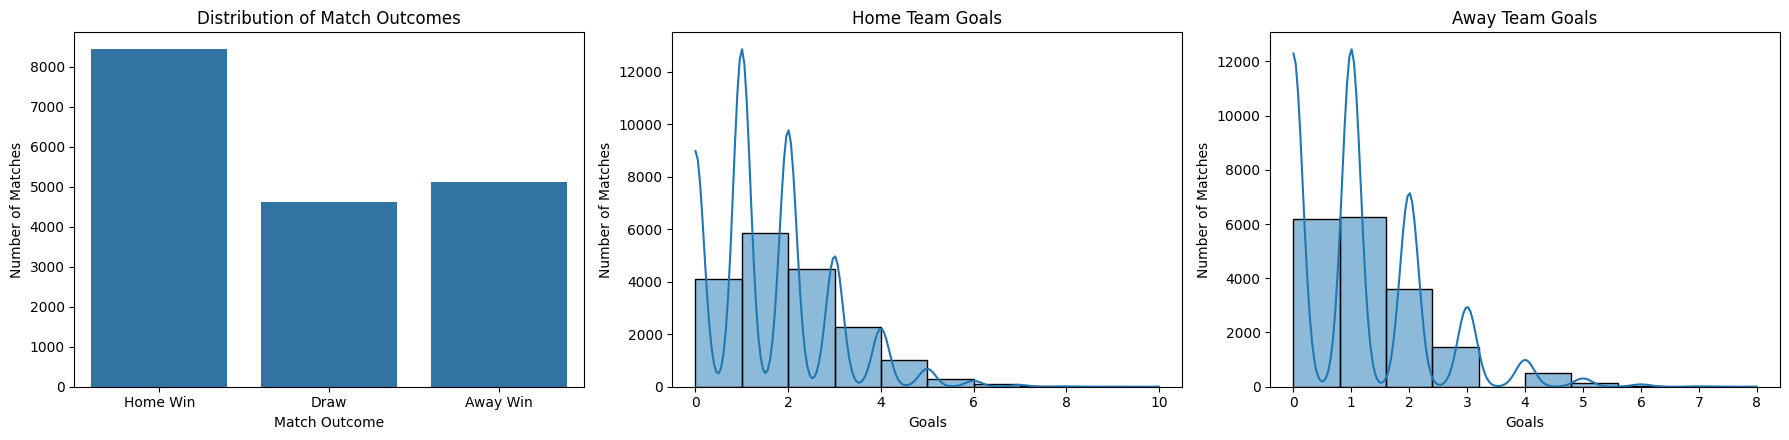

,home_team_goal,away_team_goal,total_goals,goal_difference
count,18183.000000,18183.000000,18183.000000,18183.000000
mean,1.548204,1.151130,2.699335,0.397074
std,1.295421,1.139019,1.675975,1.772589
min,0.000000,0.000000,0.000000,-8.000000
25%,1.000000,0.000000,1.000000,-1.000000
50%,1.000000,1.000000,3.000000,0.000000
75%,2.000000,2.000000,4.000000,1.000000
max,10.000000,8.000000,12.000000,10.000000


,Average_Home_Goals,Average_Away_Goals,Average_Total_Goals,Average_Goal_Difference
target_outcome,,,,
Home Win,2.44,0.54,2.98,1.89
Draw,0.98,0.98,1.97,0.00
Away Win,0.60,2.30,2.90,-1.71


In [8]:
# target
TARGET        = "target_outcome"
CLASS_ORDER   = ["Away Win", "Draw", "Home Win"]      # LabelEncoder order -> 0, 1, 2 (helpers below rely on it)
OUTCOME_ORDER = ["Home Win", "Draw", "Away Win"]      # display order for plots

# EDA works on a TRAINING copy; total_goals / goal_difference exist only here (they are leakage columns)
eda_df = train_df.copy()
eda_df["total_goals"]     = eda_df["home_team_goal"] + eda_df["away_team_goal"]
eda_df["goal_difference"] = eda_df["home_team_goal"] - eda_df["away_team_goal"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=eda_df, x=TARGET, order=OUTCOME_ORDER, ax=axes[0])
axes[0].set(title="Distribution of Match Outcomes", xlabel="Match Outcome", ylabel="Number of Matches")
sns.histplot(eda_df["home_team_goal"], bins=10, kde=True, ax=axes[1])
axes[1].set(title="Home Team Goals", xlabel="Goals", ylabel="Number of Matches")
sns.histplot(eda_df["away_team_goal"], bins=10, kde=True, ax=axes[2])
axes[2].set(title="Away Team Goals", xlabel="Goals", ylabel="Number of Matches")
plt.tight_layout(); plt.show()

display(eda_df[["home_team_goal", "away_team_goal", "total_goals", "goal_difference"]].describe())
goal_summary = (eda_df.groupby(TARGET)
                .agg(Average_Home_Goals=("home_team_goal", "mean"), Average_Away_Goals=("away_team_goal", "mean"),
                     Average_Total_Goals=("total_goals", "mean"), Average_Goal_Difference=("goal_difference", "mean"))
                .reindex(OUTCOME_ORDER))
display(goal_summary.round(2))

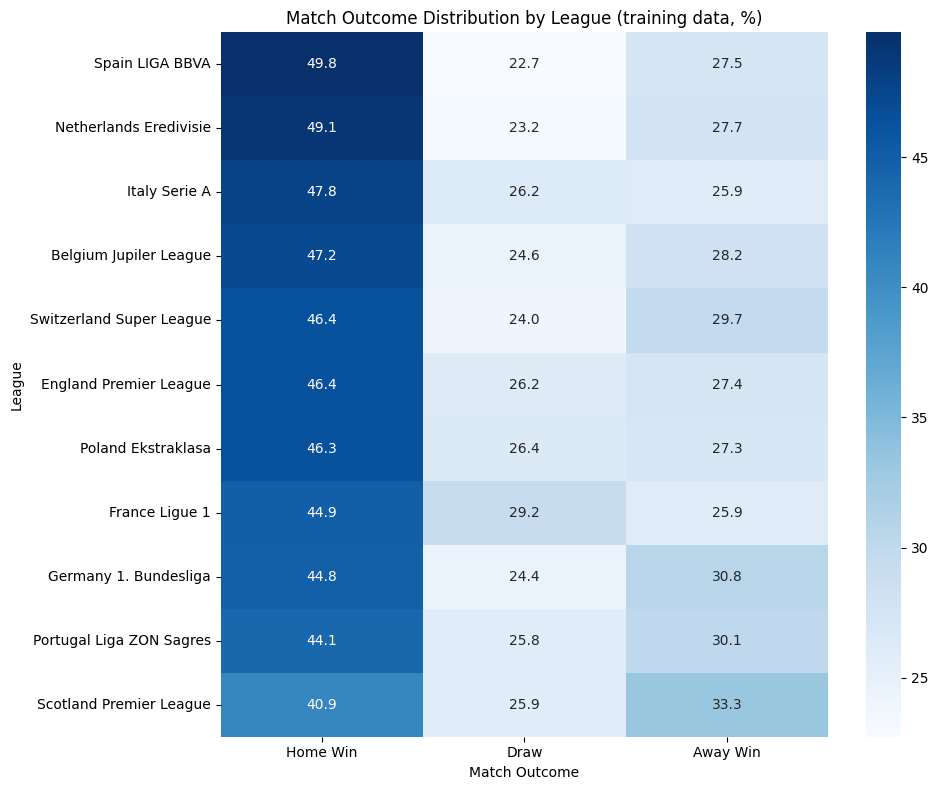

target_outcome,Home Win,Draw,Away Win
season,,,
2008/2009,47.1,25.0,27.9
2009/2010,47.4,25.2,27.4
2010/2011,46.6,25.7,27.6
2011/2012,46.5,25.4,28.1
2012/2013,44.3,26.2,29.5
2013/2014,46.3,24.9,28.9


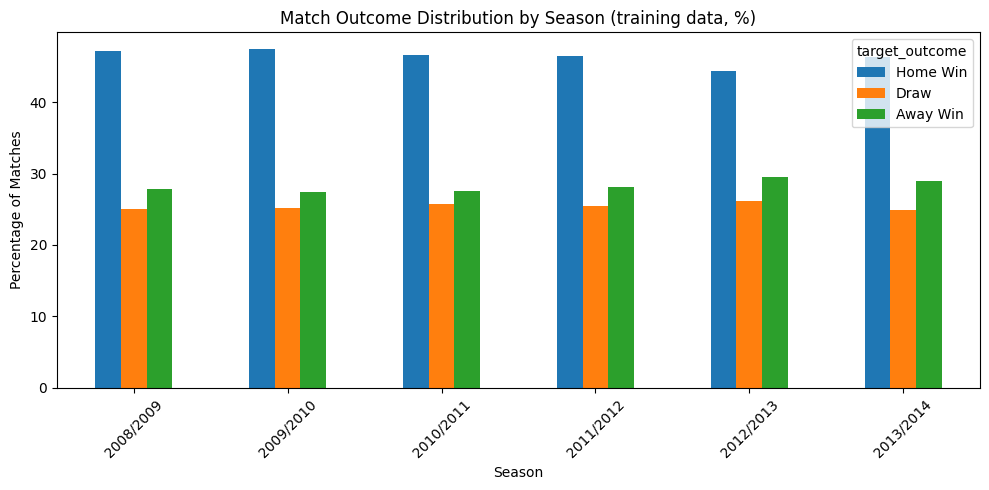

Highest home-win rates


,matches,home_win_rate
home_team,,
FC Barcelona,106,87.7
Real Madrid CF,106,85.8
FC Porto,84,83.3
Manchester United,108,80.6
RSC Anderlecht,76,80.3
SL Benfica,83,79.5
Celtic,107,79.4
FC Bayern Munich,95,78.9
Ajax,96,77.1


Lowest home-win rates


,matches,home_win_rate
home_team,,
AC Ajaccio,51,29.4
De Graafschap,51,29.4
Chievo Verona,106,29.2
Wolverhampton Wanderers,57,28.1
Hull City,50,28.0
Racing Santander,76,26.3
St. Mirren,107,25.2
Hamilton Academical FC,57,24.6
S.C. Olhanense,70,24.3


In [9]:
# Outcome patterns by league, season and team ----
league_outcomes = (pd.crosstab(eda_df["league_name"], eda_df[TARGET], normalize="index")[OUTCOME_ORDER] * 100
                   ).sort_values("Home Win", ascending=False)
plt.figure(figsize=(10, 8))
sns.heatmap(league_outcomes, annot=True, fmt=".1f", cmap="Blues")
plt.title("Match Outcome Distribution by League (training data, %)")
plt.xlabel("Match Outcome"); plt.ylabel("League"); plt.tight_layout(); plt.show()

season_outcomes = (pd.crosstab(eda_df["season"], eda_df[TARGET], normalize="index")[OUTCOME_ORDER] * 100).round(1)
display(season_outcomes)
season_outcomes.plot(kind="bar", figsize=(10, 5))
plt.title("Match Outcome Distribution by Season (training data, %)")
plt.xlabel("Season"); plt.ylabel("Percentage of Matches"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

team_home = (eda_df.groupby("home_team")[TARGET]
             .agg(matches="count", home_win_rate=lambda s: (s == "Home Win").mean() * 100)
             .query("matches >= 50").sort_values("home_win_rate", ascending=False))
print("Highest home-win rates"); display(team_home.head(10).round(1))
print("Lowest home-win rates");  display(team_home.tail(10).round(1))

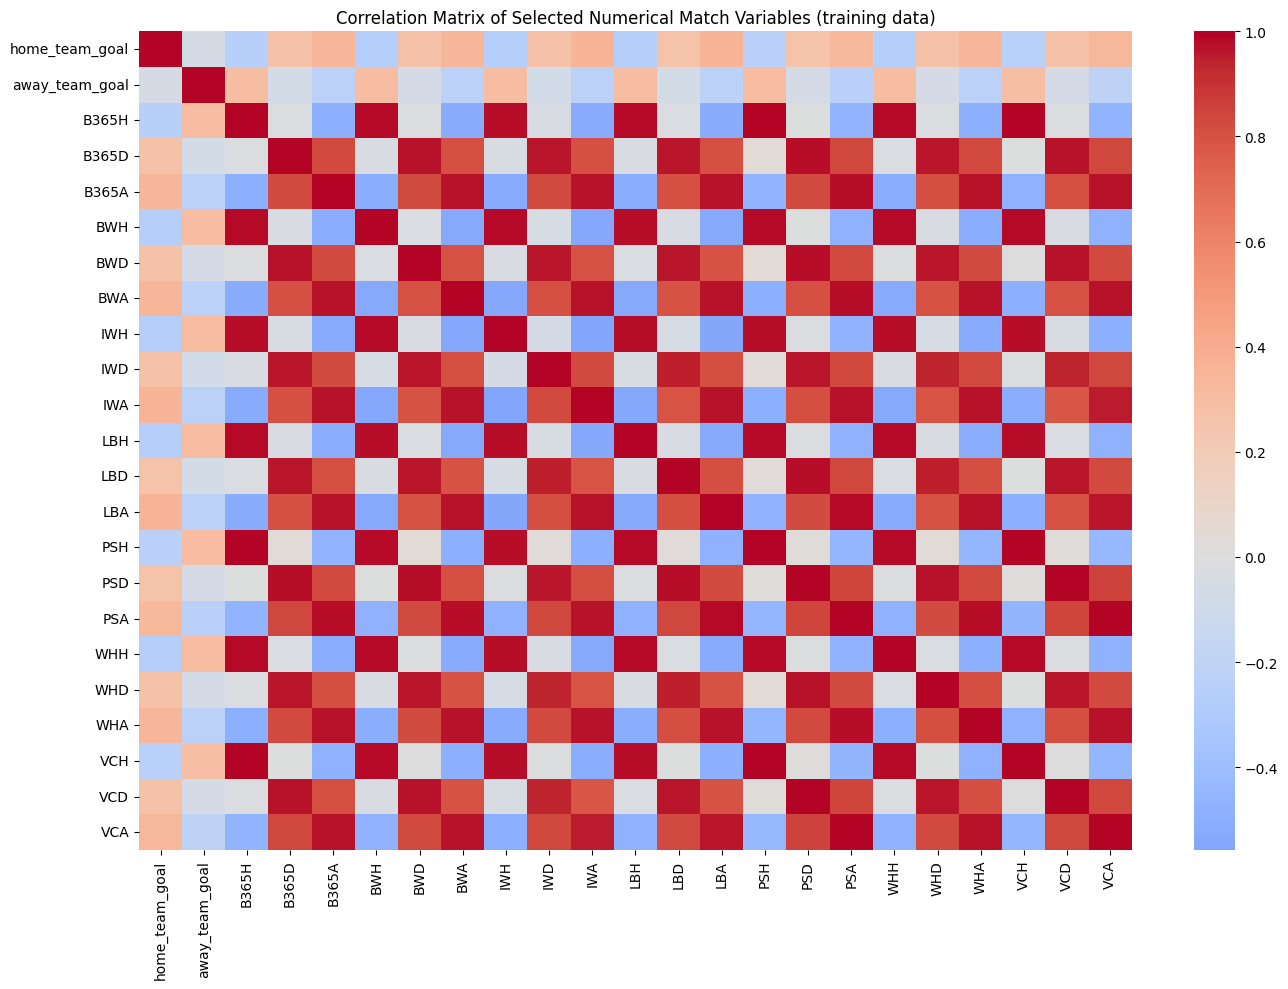

In [10]:
BOOKMAKER_TRIPLETS = {b: (f"{b}H", f"{b}D", f"{b}A")
                      for b in ("B365", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS")}

# Bookmaker odds vs goals correlation (columns subset kept from original cell 62) ----
corr_cols = ["home_team_goal", "away_team_goal"] + [c for b in ("B365", "BW", "IW", "LB", "PS", "WH", "VC")
                                                    for c in BOOKMAKER_TRIPLETS[b]]
eda_corr = eda_df[corr_cols].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(eda_corr, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Selected Numerical Match Variables (training data)")
plt.tight_layout(); plt.show()

In [11]:
eda_insight_log = pd.DataFrame({
    "Analysis": [
        "Overall outcome distribution",
        "Outcome distribution by season",
        "Home vs away goals",
        "League-level outcome patterns",
        "Team home-win rates",
        "Missing-value analysis",
        "Chronological split"
    ],
    "Purpose": [
        "Assess target class balance",
        "Identify changes in outcome patterns over time",
        "Investigate scoring and possible home advantage",
        "Compare outcome patterns across competitions",
        "Identify differences in team home performance",
        "Identify variables requiring preprocessing",
        "Prevent future information from entering training"
    ],
    "Finding": [""] * 7,   # filled below from real numbers
    "ML_Implication": [
        "Choose suitable evaluation metrics and assess class imbalance",
        "Consider temporal variation during evaluation",
        "Consider relevant pre-match features",
        "League may be useful as a contextual feature",
        "Team identity/performance may contain predictive information",
        "Preprocessing must handle missing values",
        "Provides a more realistic validation strategy"
    ]
})

vc = eda_df["target_outcome"].value_counts(normalize=True) * 100
league_home = (pd.crosstab(eda_df["league_name"], eda_df["target_outcome"], normalize="index")["Home Win"] * 100)
miss = match_df.isnull().mean() * 100
odds_miss = miss[[c for c in miss.index if c.startswith(ODDS_PREFIX)]]

findings = [
    f"Home Win {vc['Home Win']:.1f}%, Draw {vc['Draw']:.1f}%, Away Win {vc['Away Win']:.1f}% (imbalanced; majority baseline ≈ {vc.max():.1f}%)",
    f"Home-win share ranges from {season_outcomes['Home Win'].min():.1f}% to {season_outcomes['Home Win'].max():.1f}% across seasons",
    f"Home teams score {eda_df['home_team_goal'].mean():.2f} goals vs {eda_df['away_team_goal'].mean():.2f} for away teams (home advantage)",
    f"Home-win share ranges from {league_home.min():.1f}% ({league_home.idxmin()}) to {league_home.max():.1f}% ({league_home.idxmax()})",
    f"Home-win rate ranges from {team_home['home_win_rate'].min():.1f}% to {team_home['home_win_rate'].max():.1f}% across teams",
    f"{(miss > 0).sum()} Match columns have missing values; odds columns up to {odds_miss.max():.1f}% missing",
    "Training uses earlier matches and testing uses later matches",
]
eda_insight_log["Finding"] = findings
display(eda_insight_log)

,Analysis,Purpose,Finding,ML_Implication
0,Overall outcome distribution,Assess target class balance,"Home Win 46.4%, Draw 25.4%, Away Win 28.2% (im...",Choose suitable evaluation metrics and assess ...
1,Outcome distribution by season,Identify changes in outcome patterns over time,Home-win share ranges from 44.3% to 47.4% acro...,Consider temporal variation during evaluation
2,Home vs away goals,Investigate scoring and possible home advantage,Home teams score 1.55 goals vs 1.15 for away t...,Consider relevant pre-match features
3,League-level outcome patterns,Compare outcome patterns across competitions,Home-win share ranges from 40.9% (Scotland Pre...,League may be useful as a contextual feature
4,Team home-win rates,Identify differences in team home performance,Home-win rate ranges from 23.6% to 87.7% acros...,Team identity/performance may contain predicti...
5,Missing-value analysis,Identify variables requiring preprocessing,104 Match columns have missing values; odds co...,Preprocessing must handle missing values
6,Chronological split,Prevent future information from entering training,Training uses earlier matches and testing uses...,Provides a more realistic validation strategy


## 5. Preprocessing and Leakage Control


In [12]:
# Preserve match IDs separately for safe alignment in feature engineering
train_ids = train_df["id"].copy()
val_ids = val_df["id"].copy()
test_ids = test_df["id"].copy()

# Verify IDs are valid
assert train_ids.is_unique, "Duplicate match IDs found in training data."
assert val_ids.is_unique, "Duplicate match IDs found in validation data."
assert test_ids.is_unique, "Duplicate match IDs found in test data."

assert len(train_ids) == len(train_df)
assert len(val_ids) == len(val_df)
assert len(test_ids) == len(test_df)

print("Match IDs preserved successfully.")
print("Training IDs   :", len(train_ids))
print("Validation IDs :", len(val_ids))
print("Test IDs       :", len(test_ids))

TARGET = "target_outcome"
print("\nTarget column:", TARGET)

for name, df in [("Training", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name} target distribution:")
    display(df[TARGET].value_counts().rename_axis("Outcome").reset_index(name="Count"))

for name, df in [("Training", train_df), ("Validation", val_df), ("Test", test_df)]:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    print(f"{name}:")
    print("  Start:", df["date"].min())
    print("  End  :", df["date"].max())

assert train_df["date"].max() < val_df["date"].min(),  "Train/validation dates overlap"
assert val_df["date"].max()   < test_df["date"].min(), "Validation/test dates overlap"
print("Training end < Validation start: True")
print("Validation end < Test start: True")

for boundary_date in [val_df["date"].min(), test_df["date"].min()]:
    print("=" * 60)
    print("Boundary date:", boundary_date)
    print("Training:", (train_df["date"] == boundary_date).sum())
    print("Validation:", (val_df["date"] == boundary_date).sum())
    print("Test:", (test_df["date"] == boundary_date).sum())

EVENT_COLUMNS = ["goal", "shoton", "shotoff", "foulcommit","card", "cross", "corner", "possession"]

LEAKAGE_COLUMNS = ["home_team_goal", "away_team_goal", "target_outcome", "total_goals", "goal_difference"] + EVENT_COLUMNS

print("\nLeakage columns:")
for col in LEAKAGE_COLUMNS:
    print("-", col)

id_columns = [
    col for col in train_df.columns
    if col.lower() == "id"
    or col.lower().endswith("_id")
    or col.lower().endswith("_api_id")
    or (col.lower().startswith(("home_player_", "away_player_"))
        and col.split("_")[-1].isdigit())      # player API IDs (home_player_1 ... away_player_11)
]

print("\nPotential identifier columns:")
for col in id_columns:
    print("-", col)

id_summary = []

for col in id_columns:
    id_summary.append({
        "Column": col,
        "Unique Values": train_df[col].nunique(),
        "Training Rows": len(train_df),
        "Unique Ratio": round(train_df[col].nunique() / len(train_df), 4)
    })

display(pd.DataFrame(id_summary))

PLAYER_ID_COLUMNS = [f"{s}_player_{i}" for s in ("home", "away") for i in range(1, 12)]

IDENTIFIER_COLUMNS = ["id", "match_id", "country_id", "league_id", "match_api_id", "home_team_api_id", "away_team_api_id"] + PLAYER_ID_COLUMNS
IDENTIFIER_COLUMNS = [
    col for col in IDENTIFIER_COLUMNS
    if col in train_df.columns
]
print("\nIdentifiers selected for removal:")
for col in IDENTIFIER_COLUMNS:
    print("-", col)

EXCLUDE_COLUMNS = sorted(
    set(LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS)
    .intersection(train_df.columns)
)
print("\nTotal columns excluded:", len(EXCLUDE_COLUMNS))

for col in EXCLUDE_COLUMNS:
    print("-", col)

X_train_raw = train_df.drop(columns=EXCLUDE_COLUMNS).copy()
X_val_raw = val_df.drop(columns=EXCLUDE_COLUMNS).copy()
X_test_raw = test_df.drop(columns=EXCLUDE_COLUMNS).copy()
print("\nTraining:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:", X_test_raw.shape)

# Separately store y
y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()
y_test = test_df[TARGET].copy()
print("X_train:", X_train_raw.shape)
print("y_train:", y_train.shape)

Match IDs preserved successfully.
Training IDs   : 18183
Validation IDs : 3873
Test IDs       : 3923

Target column: target_outcome

Training target distribution:


,Outcome,Count
0,Home Win,8433
1,Away Win,5126
2,Draw,4624



Validation target distribution:


,Outcome,Count
0,Home Win,1753
1,Away Win,1147
2,Draw,973



Test target distribution:


,Outcome,Count
0,Home Win,1731
1,Away Win,1193
2,Draw,999


Training:
  Start: 2008-07-18 00:00:00
  End  : 2014-02-10 00:00:00
Validation:
  Start: 2014-02-11 00:00:00
  End  : 2015-04-10 00:00:00
Test:
  Start: 2015-04-11 00:00:00
  End  : 2016-05-25 00:00:00
Training end < Validation start: True
Validation end < Test start: True
Boundary date: 2014-02-11 00:00:00
Training: 0
Validation: 6
Test: 0
Boundary date: 2015-04-11 00:00:00
Training: 0
Validation: 0
Test: 38

Leakage columns:
- home_team_goal
- away_team_goal
- target_outcome
- total_goals
- goal_difference
- goal
- shoton
- shotoff
- foulcommit
- card
- cross
- corner
- possession

Potential identifier columns:
- id
- country_id
- league_id
- match_api_id
- home_team_api_id
- away_team_api_id
- home_player_1
- home_player_2
- home_player_3
- home_player_4
- home_player_5
- home_player_6
- home_player_7
- home_player_8
- home_player_9
- home_player_10
- home_player_11
- away_player_1
- away_player_2
- away_player_3
- away_player_4
- away_player_5
- away_player_6
- away_player_7
- away

,Column,Unique Values,Training Rows,Unique Ratio
0,id,18183,18183,1.0000
1,country_id,11,18183,0.0006
2,league_id,11,18183,0.0006
3,match_api_id,18183,18183,1.0000
4,home_team_api_id,274,18183,0.0151
5,away_team_api_id,274,18183,0.0151
6,home_player_1,728,18183,0.0400
7,home_player_2,1896,18183,0.1043
8,home_player_3,1877,18183,0.1032
9,home_player_4,2032,18183,0.1118



Identifiers selected for removal:
- id
- match_id
- country_id
- league_id
- match_api_id
- home_team_api_id
- away_team_api_id
- home_player_1
- home_player_2
- home_player_3
- home_player_4
- home_player_5
- home_player_6
- home_player_7
- home_player_8
- home_player_9
- home_player_10
- home_player_11
- away_player_1
- away_player_2
- away_player_3
- away_player_4
- away_player_5
- away_player_6
- away_player_7
- away_player_8
- away_player_9
- away_player_10
- away_player_11

Total columns excluded: 40
- away_player_1
- away_player_10
- away_player_11
- away_player_2
- away_player_3
- away_player_4
- away_player_5
- away_player_6
- away_player_7
- away_player_8
- away_player_9
- away_team_api_id
- away_team_goal
- card
- corner
- country_id
- cross
- foulcommit
- goal
- home_player_1
- home_player_10
- home_player_11
- home_player_2
- home_player_3
- home_player_4
- home_player_5
- home_player_6
- home_player_7
- home_player_8
- home_player_9
- home_team_api_id
- home_team_goal
- 

In [13]:
# Copy datasets
X_train = X_train_raw.copy()
X_val = X_val_raw.copy()
X_test = X_test_raw.copy()

# Define all 10 bookmaker odds columns to exclude from raw median imputation
BOOKMAKER_TRIPLETS = {
    "B365": ("B365H", "B365D", "B365A"),
    "BW":   ("BWH",   "BWD",   "BWA"),
    "IW":   ("IWH",   "IWD",   "IWA"),
    "LB":   ("LBH",   "LBD",   "LBA"),
    "PS":   ("PSH",   "PSD",   "PSA"),
    "WH":   ("WHH",   "WHD",   "WHA"),
    "SJ":   ("SJH",   "SJD",   "SJA"),
    "VC":   ("VCH",   "VCD",   "VCA"),
    "GB":   ("GBH",   "GBD",   "GBA"),
    "BS":   ("BSH",   "BSD",   "BSA"),
}
ODDS_COLS = [c for t in BOOKMAKER_TRIPLETS.values() for c in t]

# Numerical columns (EXCLUDING raw odds)
numeric_columns = [
    c for c in X_train.select_dtypes(include=np.number).columns.tolist()
    if c not in ODDS_COLS
]

# Categorical columns
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns (excluding odds):", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

# Numerical imputation values learned from training data (odds remain NaN)
numeric_fill_values = X_train[numeric_columns].median()

# Categorical imputation values learned from training data
categorical_fill_values = {
    col: X_train[col].mode(dropna=True)[0]
    for col in categorical_columns
    if X_train[col].notna().any()
}

assert not any(c in X_train.columns for c in EVENT_COLUMNS + PLAYER_ID_COLUMNS), \
    "Event/player-ID columns must be removed before imputation"

# Apply numerical imputation (only to non-odds numeric columns)
for col in numeric_columns:
    X_train[col] = X_train[col].fillna(numeric_fill_values[col])
    X_val[col] = X_val[col].fillna(numeric_fill_values[col])
    X_test[col] = X_test[col].fillna(numeric_fill_values[col])

# Apply categorical imputation
for col, value in categorical_fill_values.items():
    X_train[col] = X_train[col].fillna(value)
    X_val[col] = X_val[col].fillna(value)
    X_test[col] = X_test[col].fillna(value)

Numerical columns (excluding odds): 45
Categorical columns: 5


In [14]:
# 1) Non-odds columns must be completely imputed
for name, d in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    left = d.drop(columns=ODDS_COLS).isnull().sum().sum()
    print(f"{name}: non-odds missing = {left}")
    assert left == 0

# 2) Odds availability per bookmaker and split (home-odds column used as proxy)
book_missing = pd.DataFrame({
    book: {"train %": X_train[h].isna().mean() * 100,
           "val %":   X_val[h].isna().mean() * 100,
           "test %":  X_test[h].isna().mean() * 100}
    for book, (h, _, _) in BOOKMAKER_TRIPLETS.items()
}).T.round(1)
display(book_missing)

UNSTABLE_BOOKS = book_missing[(book_missing > 50).any(axis=1)].index.tolist()
print("Bookmakers unusable/unstable across splits:", UNSTABLE_BOOKS)   # expected: SJ, GB, BS, PS

print("Training target:")
display(y_train.value_counts())

print("\nValidation target:")
display(y_val.value_counts())

print("\nTest target:")
display(y_test.value_counts())

preprocessing_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Columns": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Missing Values (odds only, kept as NaN)": [
        X_train[ODDS_COLS].isnull().sum().sum(),
        X_val[ODDS_COLS].isnull().sum().sum(),
        X_test[ODDS_COLS].isnull().sum().sum()
    ],
    "Missing Values (non-odds)": [
        X_train.drop(columns=ODDS_COLS).isnull().sum().sum(),
        X_val.drop(columns=ODDS_COLS).isnull().sum().sum(),
        X_test.drop(columns=ODDS_COLS).isnull().sum().sum()
    ]
})
display(preprocessing_summary)

# Final ID alignment verification
assert len(train_ids) == len(X_train) == len(y_train)
assert len(val_ids) == len(X_val) == len(y_val)
assert len(test_ids) == len(X_test) == len(y_test)

# Verify the preprocessing stage did not change row order
assert train_ids.reset_index(drop=True).equals(train_df["id"].reset_index(drop=True))
assert val_ids.reset_index(drop=True).equals(val_df["id"].reset_index(drop=True))
assert test_ids.reset_index(drop=True).equals(test_df["id"].reset_index(drop=True))

print("ID and row alignment verified before saving.")

# Verify raw odds kept their genuine missing rates in EVERY split (not only training)
for c in ["SJH", "GBH", "BSH", "PSH"]:
    print(
        f"{c} NaN rate -> train: {X_train[c].isna().mean():.3f} | "
        f"val: {X_val[c].isna().mean():.3f} | test: {X_test[c].isna().mean():.3f}"
    )

# Imputation must not have touched any odds column
for name, imputed, raw in [("Train", X_train, X_train_raw),
                           ("Validation", X_val, X_val_raw),
                           ("Test", X_test, X_test_raw)]:
    assert imputed[ODDS_COLS].isna().equals(raw[ODDS_COLS].isna()), f"{name}: odds were altered"

print("\nUnstable bookmakers (>50% missing in at least one split):", UNSTABLE_BOOKS)

PREPROCESSED_DIR = os.path.join(BASE_DIR, "preprocessed_dataset")
os.makedirs(PREPROCESSED_DIR, exist_ok=True)

X_train.to_csv(os.path.join(PREPROCESSED_DIR, "X_train_preprocessed.csv"), index=False)
X_val.to_csv(os.path.join(PREPROCESSED_DIR, "X_validation_preprocessed.csv"), index=False)
X_test.to_csv(os.path.join(PREPROCESSED_DIR, "X_test_preprocessed.csv"), index=False)

y_train.to_csv(os.path.join(PREPROCESSED_DIR, "y_train.csv"), index=False)
y_val.to_csv(os.path.join(PREPROCESSED_DIR, "y_validation.csv"), index=False)
y_test.to_csv(os.path.join(PREPROCESSED_DIR, "y_test.csv"), index=False)

# Save match IDs separately
train_ids.rename("id").to_csv(os.path.join(PREPROCESSED_DIR, "train_ids.csv"), index=False)
val_ids.rename("id").to_csv(os.path.join(PREPROCESSED_DIR, "validation_ids.csv"), index=False)
test_ids.rename("id").to_csv(os.path.join(PREPROCESSED_DIR, "test_ids.csv"),index=False)

print("Preprocessed datasets saved to:")
print(PREPROCESSED_DIR)
print("\nFiles:")
print(os.listdir(PREPROCESSED_DIR))

Train: non-odds missing = 0
Validation: non-odds missing = 0
Test: non-odds missing = 0


,train %,val %,test %
B365,13.1,13.1,12.8
BW,13.2,13.1,12.8
IW,13.3,13.6,13.1
LB,13.2,13.3,12.8
PS,75.8,13.5,13.0
WH,13.2,13.1,12.8
SJ,13.2,66.2,100.0
VC,13.2,13.1,12.8
GB,22.1,100.0,100.0
BS,22.1,100.0,100.0


Bookmakers unusable/unstable across splits: ['PS', 'SJ', 'GB', 'BS']
Training target:


,count
target_outcome,
Home Win,8433
Away Win,5126
Draw,4624



Validation target:


,count
target_outcome,
Home Win,1753
Away Win,1147
Draw,973



Test target:


,count
target_outcome,
Home Win,1731
Away Win,1193
Draw,999


,Dataset,Rows,Columns,"Missing Values (odds only, kept as NaN)",Missing Values (non-odds)
0,Training,18183,81,115851,0
1,Validation,3873,81,41700,0
2,Test,3923,81,45909,0


ID and row alignment verified before saving.
SJH NaN rate -> train: 0.132 | val: 0.662 | test: 1.000
GBH NaN rate -> train: 0.221 | val: 1.000 | test: 1.000
BSH NaN rate -> train: 0.221 | val: 1.000 | test: 1.000
PSH NaN rate -> train: 0.758 | val: 0.135 | test: 0.130

Unstable bookmakers (>50% missing in at least one split): ['PS', 'SJ', 'GB', 'BS']
Preprocessed datasets saved to:
/content/drive/MyDrive/ML Assignment/preprocessed_dataset

Files:
['X_train_preprocessed.csv', 'X_validation_preprocessed.csv', 'X_test_preprocessed.csv', 'y_train.csv', 'y_validation.csv', 'y_test.csv', 'train_ids.csv', 'validation_ids.csv', 'test_ids.csv']


## 6. Historical Feature Engineering

In [15]:
# Continue from the in-memory splits and preprocessed matrices
RAW_SPLIT_DIR = SPLIT_DIR
os.makedirs(FEATURE_DIR, exist_ok=True)
train_raw = train_df.copy()
val_raw = val_df.copy()
test_raw = test_df.copy()

assert len(train_raw) == len(X_train) == len(y_train) == len(train_ids)
assert len(val_raw) == len(X_val) == len(y_val) == len(val_ids)
assert len(test_raw) == len(X_test) == len(y_test) == len(test_ids)
assert np.array_equal(train_ids.to_numpy(), train_raw['id'].to_numpy())
assert np.array_equal(val_ids.to_numpy(), val_raw['id'].to_numpy())
assert np.array_equal(test_ids.to_numpy(), test_raw['id'].to_numpy())
print('In-memory raw/preprocessed row and ID alignment verified.')

In-memory raw/preprocessed row and ID alignment verified.


In [16]:
required_history_columns = ["id", "date", "home_team", "away_team", "home_team_goal", "away_team_goal", "target_outcome"]

for name, d in [("train", train_raw), ("validation", val_raw), ("test", test_raw)]:
    missing_cols = [c for c in required_history_columns if c not in d.columns]
    if missing_cols:
        raise ValueError(f"{name}: required columns missing: {missing_cols}")

print("All required historical columns are available in train, validation and test.")

# Post-match event columns (XML text recorded during/after the match) -> leakage
EVENT_COLUMNS = ["goal", "shoton", "shotoff", "foulcommit", "card", "cross", "corner", "possession"]
# Player API IDs: identifiers, removed in Data Preprocessing
PLAYER_ID_COLUMNS = [f"{s}_player_{i}" for s in ("home", "away") for i in range(1, 12)]
# Raw bookmaker odds (the only columns allowed to keep genuine NaN values)
ODDS_COLS = [f"{b}{o}" for b in ("B365", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS")
             for o in ("H", "D", "A")]
LEAKAGE_COLUMNS = {"home_team_goal", "away_team_goal", "target_outcome",
                   "total_goals", "goal_difference"} | set(EVENT_COLUMNS)
print("Leakage columns monitored:", len(LEAKAGE_COLUMNS))

raw_frames = []

for df, split_name in [(train_raw, "train"), (val_raw, "validation"), (test_raw, "test")]:
    temp = df.copy()
    temp["date"] = pd.to_datetime(
        temp["date"], errors="coerce"
    )
    temp["_split"] = split_name
    raw_frames.append(temp)

all_raw = pd.concat(raw_frames, ignore_index=True)

all_raw = all_raw.sort_values("date").reset_index(drop=True)

print("Combined historical dataset:")
print(all_raw.shape)

display(all_raw[["date", "home_team", "away_team", "home_team_goal", "away_team_goal", "target_outcome", "_split"]].head(10))

if not all_raw["date"].is_monotonic_increasing:
    raise ValueError("Historical dataset is not sorted chronologically.")

if all_raw["date"].isna().any():
    raise ValueError("Missing/invalid dates found in historical data.")

print("Historical data is chronologically ordered and has no missing dates.")

valid_outcomes = {"Home Win", "Draw", "Away Win"}
invalid_outcomes = set(all_raw["target_outcome"].dropna().unique()) - valid_outcomes
if invalid_outcomes:
    raise ValueError(f"Unexpected target values found: {invalid_outcomes}")

print("Target outcome values verified.")

All required historical columns are available in train, validation and test.
Leakage columns monitored: 13
Combined historical dataset:
(25979, 122)


,date,home_team,away_team,home_team_goal,away_team_goal,target_outcome,_split
0,2008-07-18,BSC Young Boys,FC Basel,1,2,Away Win,train
1,2008-07-19,FC Aarau,FC Sion,3,1,Home Win,train
2,2008-07-20,FC Luzern,FC Vaduz,1,2,Away Win,train
3,2008-07-20,Neuchâtel Xamax,FC Zürich,1,2,Away Win,train
4,2008-07-23,AC Bellinzona,Neuchâtel Xamax,1,2,Away Win,train
5,2008-07-23,FC Basel,Grasshopper Club Zürich,1,0,Home Win,train
6,2008-07-23,FC Zürich,FC Luzern,1,0,Home Win,train
7,2008-07-24,FC Sion,BSC Young Boys,2,1,Home Win,train
8,2008-07-24,FC Vaduz,FC Aarau,0,2,Away Win,train
9,2008-07-26,FC Luzern,Neuchâtel Xamax,0,1,Away Win,train


Historical data is chronologically ordered and has no missing dates.
Target outcome values verified.


In [17]:
INITIAL_ELO = 1500.0

def create_team_state():
    return {
        # Overall historical performance
        "matches": 0, "wins": 0, "draws": 0, "losses": 0, "points": 0, "goals_for": 0, "goals_against": 0,
        # Historical HOME performance
        "home_matches": 0, "home_wins": 0, "home_draws": 0, "home_losses": 0, "home_points": 0, "home_goals_for": 0, "home_goals_against": 0,
        # Historical AWAY performance
        "away_matches": 0, "away_wins": 0, "away_draws": 0, "away_losses": 0, "away_points": 0, "away_goals_for": 0, "away_goals_against": 0,
        # Rolling form - Keep last 10 so we can calculate 3, 5 and 10
        "recent_points": deque(maxlen=10), "recent_goals_for": deque(maxlen=10), "recent_goals_against": deque(maxlen=10), "recent_results": deque(maxlen=10),
        # Rest information
        "last_match_date": None,
        # Elo rating
        "elo": INITIAL_ELO
    }


team_history = defaultdict(create_team_state)
print("Enhanced historical team state initialized.")

MAX_REST_DAYS = 30.0     # anything longer is "fully rested"

def safe_rate(numerator, denominator):
    return numerator / denominator if denominator > 0 else 0.0

def rolling_average(values, window):
    values = list(values)[-window:]
    if len(values) == 0:
        return 0.0
    return float(np.mean(values))

def rolling_win_rate(results, window):
    results = list(results)[-window:]
    if len(results) == 0:
        return 0.0
    return sum(result == "W" for result in results) / len(results)

def calculate_team_features(history, team, match_date, venue):
    state = history[team]
    matches = state["matches"]
    # Rest days
    if state["last_match_date"] is None:
        days_since_last_match = MAX_REST_DAYS            # unknown history -> neutral value
    else:
        days_since_last_match = (pd.Timestamp(match_date) - pd.Timestamp(state["last_match_date"])).days

        # Defensive protection + cap off-season gaps
        days_since_last_match = min(max(float(days_since_last_match), 0.0), MAX_REST_DAYS)

    # Overall historical performance
    features = {
        "matches_before": matches,
        "win_rate": safe_rate(state["wins"], matches),
        "draw_rate": safe_rate(state["draws"], matches),
        "loss_rate": safe_rate(state["losses"], matches),
        "points_per_match": safe_rate(state["points"], matches),
        "goals_for_per_match": safe_rate(state["goals_for"], matches),
        "goals_against_per_match": safe_rate(state["goals_against"], matches),
        "goal_difference_per_match": safe_rate(
            state["goals_for"] - state["goals_against"], matches),

        # Rolling form: last 3
        "points_last3": rolling_average(state["recent_points"], 3),
        "goals_for_last3": rolling_average(state["recent_goals_for"], 3),
        "goals_against_last3": rolling_average(state["recent_goals_against"], 3),
        "win_rate_last3": rolling_win_rate(state["recent_results"], 3),

        # Rolling form: last 5
        "points_last5": rolling_average(state["recent_points"], 5),
        "goals_for_last5": rolling_average(state["recent_goals_for"], 5),
        "goals_against_last5": rolling_average(state["recent_goals_against"], 5),
        "win_rate_last5": rolling_win_rate(state["recent_results"], 5),

        # Rolling form: last 10
        "points_last10": rolling_average(state["recent_points"], 10),
        "goals_for_last10": rolling_average(state["recent_goals_for"], 10),
        "goals_against_last10": rolling_average(state["recent_goals_against"], 10),
        "win_rate_last10": rolling_win_rate(state["recent_results"], 10),

        # Rest + Elo
        "days_since_last_match": days_since_last_match,
        "elo_before": state["elo"]
    }

    # Venue-specific historical performance
    if venue == "home":
        venue_matches = state["home_matches"]
        features.update({
            "venue_matches_before":venue_matches,
            "venue_win_rate":
                safe_rate(state["home_wins"], venue_matches),
            "venue_draw_rate":
                safe_rate(state["home_draws"], venue_matches),
            "venue_points_per_match":
                safe_rate(state["home_points"], venue_matches),
            "venue_goals_for_per_match":
                safe_rate(state["home_goals_for"], venue_matches),
            "venue_goals_against_per_match":
                safe_rate(state["home_goals_against"], venue_matches)
        })

    elif venue == "away":
        venue_matches = state["away_matches"]
        features.update({
            "venue_matches_before":venue_matches,
            "venue_win_rate":
                safe_rate(state["away_wins"], venue_matches),
            "venue_draw_rate":
                safe_rate(state["away_draws"], venue_matches),
            "venue_points_per_match":
                safe_rate(state["away_points"], venue_matches),
            "venue_goals_for_per_match":
                safe_rate(state["away_goals_for"], venue_matches),
            "venue_goals_against_per_match":
                safe_rate(state["away_goals_against"], venue_matches)
        })
    else:
        raise ValueError("venue must be either 'home' or 'away'")
    return features

# Elo rating update
ELO_K = 20.0
HOME_ELO_ADVANTAGE = 100.0

def update_elo(history, home_team, away_team, result):
    home_elo = history[home_team]["elo"]
    away_elo = history[away_team]["elo"]

    # Expected home score including home advantage
    expected_home = 1 / (1 + 10 ** ((away_elo - (home_elo + HOME_ELO_ADVANTAGE)) / 400))
    expected_away = 1 - expected_home

    if result == "Home Win":
        actual_home = 1.0
        actual_away = 0.0

    elif result == "Draw":
        actual_home = 0.5
        actual_away = 0.5

    elif result == "Away Win":
        actual_home = 0.0
        actual_away = 1.0

    else:
        raise ValueError(f"Unexpected result: {result}")

    history[home_team]["elo"] = (home_elo + ELO_K * (actual_home - expected_home))
    history[away_team]["elo"] = (away_elo + ELO_K * (actual_away - expected_away))

def update_team_history(history, home_team, away_team, home_goals, away_goals, result, match_date):
    home_state = history[home_team]
    away_state = history[away_team]

    # Overall match counts
    home_state["matches"] += 1
    away_state["matches"] += 1

    # Overall goals
    home_state["goals_for"] += home_goals
    home_state["goals_against"] += away_goals
    away_state["goals_for"] += away_goals
    away_state["goals_against"] += home_goals

    # Venue-specific counts and goals
    home_state["home_matches"] += 1
    away_state["away_matches"] += 1
    home_state["home_goals_for"] += home_goals
    home_state["home_goals_against"] += away_goals
    away_state["away_goals_for"] += away_goals
    away_state["away_goals_against"] += home_goals

    # Result updates
    if result == "Home Win":
        # Overall
        home_state["wins"] += 1
        home_state["points"] += 3
        away_state["losses"] += 1
        # Venue specific
        home_state["home_wins"] += 1
        home_state["home_points"] += 3
        away_state["away_losses"] += 1
        # Recent form
        home_state["recent_points"].append(3)
        away_state["recent_points"].append(0)
        home_state["recent_results"].append("W")
        away_state["recent_results"].append("L")

    elif result == "Draw":
        # Overall
        home_state["draws"] += 1
        away_state["draws"] += 1
        home_state["points"] += 1
        away_state["points"] += 1
        # Venue specific
        home_state["home_draws"] += 1
        away_state["away_draws"] += 1
        home_state["home_points"] += 1
        away_state["away_points"] += 1
        # Recent form
        home_state["recent_points"].append(1)
        away_state["recent_points"].append(1)
        home_state["recent_results"].append("D")
        away_state["recent_results"].append("D")

    elif result == "Away Win":
        # Overall
        home_state["losses"] += 1
        away_state["wins"] += 1
        away_state["points"] += 3
        # Venue specific
        home_state["home_losses"] += 1
        away_state["away_wins"] += 1
        away_state["away_points"] += 3
        # Recent form
        home_state["recent_points"].append(0)
        away_state["recent_points"].append(3)
        home_state["recent_results"].append("L")
        away_state["recent_results"].append("W")

    else:
        raise ValueError(f"Unexpected match result: {result}")

    # Recent goals
    home_state["recent_goals_for"].append(home_goals)
    home_state["recent_goals_against"].append(away_goals)
    away_state["recent_goals_for"].append(away_goals)
    away_state["recent_goals_against"].append(home_goals)

    # Elo update
    update_elo(history=history, home_team=home_team, away_team=away_team, result=result)

    # Last match date
    home_state["last_match_date"] = match_date
    away_state["last_match_date"] = match_date

Enhanced historical team state initialized.


In [18]:
engineered_rows = []
team_history = defaultdict(create_team_state)

for match_date, daily_matches in all_raw.groupby("date", sort=True):

    # STEP 1: Generate features using ONLY information available before this date.
    for _, row in daily_matches.iterrows():
        home_team = row["home_team"]
        away_team = row["away_team"]

        home_features = calculate_team_features(history=team_history, team=home_team, match_date=match_date, venue="home")
        away_features = calculate_team_features(history=team_history, team=away_team, match_date=match_date, venue="away")

        engineered_rows.append({
            # Match identity
            "_match_id": row["id"], "date": match_date, "home_team": home_team, "away_team": away_team,

            # HOME: overall historical performance
            "home_matches_before":home_features["matches_before"],
            "home_win_rate":home_features["win_rate"],
            "home_draw_rate":home_features["draw_rate"],
            "home_loss_rate":home_features["loss_rate"],
            "home_points_per_match":home_features["points_per_match"],
            "home_goals_for_per_match":home_features["goals_for_per_match"],
            "home_goals_against_per_match":home_features["goals_against_per_match"],
            "home_goal_difference_per_match":home_features["goal_difference_per_match"],

            # HOME: performance specifically at home
            "home_home_matches_before":home_features["venue_matches_before"],
            "home_home_win_rate":home_features["venue_win_rate"],
            "home_home_draw_rate":home_features["venue_draw_rate"],
            "home_home_points_per_match":home_features["venue_points_per_match"],
            "home_home_goals_for_per_match":home_features["venue_goals_for_per_match"],
            "home_home_goals_against_per_match":home_features["venue_goals_against_per_match"],

            # HOME: rolling form
            "home_points_last3":home_features["points_last3"],
            "home_points_last5":home_features["points_last5"],
            "home_points_last10":home_features["points_last10"],
            "home_goals_for_last3":home_features["goals_for_last3"],
            "home_goals_for_last5":home_features["goals_for_last5"],
            "home_goals_for_last10":home_features["goals_for_last10"],
            "home_goals_against_last3":home_features["goals_against_last3"],
            "home_goals_against_last5":home_features["goals_against_last5"],
            "home_goals_against_last10":home_features["goals_against_last10"],
            "home_win_rate_last3":home_features["win_rate_last3"],
            "home_win_rate_last5":home_features["win_rate_last5"],
            "home_win_rate_last10":home_features["win_rate_last10"],

            # HOME: rest and Elo
            "home_days_since_last_match":home_features["days_since_last_match"],
            "home_elo_before":home_features["elo_before"],

            # AWAY: overall historical performance
            "away_matches_before":away_features["matches_before"],
            "away_win_rate":away_features["win_rate"],
            "away_draw_rate":away_features["draw_rate"],
            "away_loss_rate":away_features["loss_rate"],
            "away_points_per_match":away_features["points_per_match"],
            "away_goals_for_per_match":away_features["goals_for_per_match"],
            "away_goals_against_per_match":away_features["goals_against_per_match"],
            "away_goal_difference_per_match":away_features["goal_difference_per_match"],

            # AWAY: performance specifically away
            "away_away_matches_before":away_features[ "venue_matches_before"],
            "away_away_win_rate":away_features["venue_win_rate"],
            "away_away_draw_rate":away_features["venue_draw_rate"],
            "away_away_points_per_match":away_features["venue_points_per_match"],
            "away_away_goals_for_per_match":away_features["venue_goals_for_per_match"],

            "away_away_goals_against_per_match":away_features["venue_goals_against_per_match"],

            # AWAY: rolling form
            "away_points_last3":away_features["points_last3"],
            "away_points_last5":away_features["points_last5"],
            "away_points_last10":away_features["points_last10"],
            "away_goals_for_last3":away_features["goals_for_last3"],
            "away_goals_for_last5":away_features["goals_for_last5"],
            "away_goals_for_last10":away_features["goals_for_last10"],
            "away_goals_against_last3":away_features["goals_against_last3"],
            "away_goals_against_last5":away_features["goals_against_last5"],
            "away_goals_against_last10":away_features["goals_against_last10"],
            "away_win_rate_last3":away_features["win_rate_last3"],
            "away_win_rate_last5":away_features["win_rate_last5"],
            "away_win_rate_last10":away_features["win_rate_last10"],

            # AWAY: rest and Elo
            "away_days_since_last_match":away_features["days_since_last_match"],
            "away_elo_before":away_features["elo_before"]
        })

    # STEP 2: Only AFTER all features for the date are generated,
    # update team histories using that day's results.
    for _, row in daily_matches.iterrows():
        update_team_history(
            history=team_history, home_team=row["home_team"], away_team=row["away_team"], home_goals=row["home_team_goal"],
            away_goals=row["away_team_goal"], result=row["target_outcome"], match_date=match_date
        )

print(
    "Historical features generated:",
    len(engineered_rows)
)

Historical features generated: 25979


In [19]:
engineered_df = pd.DataFrame(engineered_rows)
print("Engineered dataset shape:")
print(engineered_df.shape)
display(engineered_df.head(10))
first_match = engineered_df.iloc[0]

print("Home matches before:", first_match["home_matches_before"])
print("Away matches before:",first_match["away_matches_before"])
print("Home Elo before:", first_match["home_elo_before"])
print("Away Elo before:", first_match["away_elo_before"])

assert first_match["home_elo_before"] == INITIAL_ELO
assert first_match["away_elo_before"] == INITIAL_ELO
print("Initial-history check passed.")

no_history = engineered_df[(engineered_df["home_matches_before"] == 0) | (engineered_df["away_matches_before"] == 0)]
print("Matches involving a team with no prior history:", len(no_history))

# Overall historical differences
engineered_df["win_rate_difference"] = (
engineered_df["home_win_rate"] - engineered_df["away_win_rate"])
engineered_df["draw_rate_difference"] = (engineered_df["home_draw_rate"] - engineered_df["away_draw_rate"])
engineered_df["points_per_match_difference"] = (engineered_df["home_points_per_match"] - engineered_df["away_points_per_match"])
engineered_df["goals_for_difference"] = (engineered_df["home_goals_for_per_match"] - engineered_df["away_goals_for_per_match"])
engineered_df["goals_against_difference"] = (engineered_df["home_goals_against_per_match"] - engineered_df["away_goals_against_per_match"])

# Venue-specific strength differences
engineered_df["venue_win_rate_difference"] = (engineered_df["home_home_win_rate"] - engineered_df["away_away_win_rate"])
engineered_df["venue_points_difference"] = (engineered_df["home_home_points_per_match"] - engineered_df["away_away_points_per_match"])
engineered_df["venue_goals_for_difference"] = (engineered_df["home_home_goals_for_per_match"] - engineered_df["away_away_goals_for_per_match"])
engineered_df["venue_goals_against_difference"] = (engineered_df["home_home_goals_against_per_match"] - engineered_df["away_away_goals_against_per_match"])

# Rolling form differences
for window in [3, 5, 10]:
    engineered_df[f"points_last{window}_difference"] = (engineered_df[f"home_points_last{window}"] - engineered_df[f"away_points_last{window}"])
    engineered_df[f"goals_for_last{window}_difference"] = (engineered_df[f"home_goals_for_last{window}"] - engineered_df[f"away_goals_for_last{window}"])
    engineered_df[f"goals_against_last{window}_difference"] = (engineered_df[f"home_goals_against_last{window}"] - engineered_df[f"away_goals_against_last{window}"])
    engineered_df[f"win_rate_last{window}_difference"] = (engineered_df[f"home_win_rate_last{window}"] - engineered_df[f"away_win_rate_last{window}"])

# Rest difference
engineered_df["rest_days_difference"] = (engineered_df["home_days_since_last_match"] - engineered_df["away_days_since_last_match"])

# Elo difference
engineered_df["elo_difference"] = (engineered_df["home_elo_before"] - engineered_df["away_elo_before"])

print("Relative team-strength features created.")

Engineered dataset shape:
(25979, 60)


,_match_id,date,home_team,away_team,home_matches_before,home_win_rate,home_draw_rate,home_loss_rate,home_points_per_match,home_goals_for_per_match,...,away_goals_for_last5,away_goals_for_last10,away_goals_against_last3,away_goals_against_last5,away_goals_against_last10,away_win_rate_last3,away_win_rate_last5,away_win_rate_last10,away_days_since_last_match,away_elo_before
0,24559,2008-07-18,BSC Young Boys,FC Basel,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0,1500.000000
1,24560,2008-07-19,FC Aarau,FC Sion,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0,1500.000000
2,24561,2008-07-20,FC Luzern,FC Vaduz,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0,1500.000000
3,24562,2008-07-20,Neuchâtel Xamax,FC Zürich,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0,1500.000000
4,24614,2008-07-23,AC Bellinzona,Neuchâtel Xamax,0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,2.0,2.0,2.0,0.0,0.0,0.0,3.0,1487.198700
5,24613,2008-07-23,FC Basel,Grasshopper Club Zürich,1,1.0,0.0,0.0,3.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0,1500.000000
6,24615,2008-07-23,FC Zürich,FC Luzern,1,1.0,0.0,0.0,3.0,2.0,...,1.0,1.0,2.0,2.0,2.0,0.0,0.0,0.0,3.0,1487.198700
7,24616,2008-07-24,FC Sion,BSC Young Boys,1,0.0,0.0,1.0,0.0,1.0,...,1.0,1.0,2.0,2.0,2.0,0.0,0.0,0.0,6.0,1487.198700
8,24617,2008-07-24,FC Vaduz,FC Aarau,1,1.0,0.0,0.0,3.0,2.0,...,3.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,1507.198700
9,24669,2008-07-26,FC Luzern,Neuchâtel Xamax,2,0.0,0.0,1.0,0.0,0.5,...,1.5,1.5,1.5,1.5,1.5,0.5,0.5,0.5,3.0,1500.335918


Home matches before: 0
Away matches before: 0
Home Elo before: 1500.0
Away Elo before: 1500.0
Initial-history check passed.
Matches involving a team with no prior history: 204
Relative team-strength features created.


In [20]:
# =============================================================================
# RELATIVE TEAM-STRENGTH DIFFERENTIALS (ANTI-LEAKAGE PRE-MATCH PROTOCOL)
# =============================================================================

# 1. Points/Match Difference (Home PPG - Away PPG)
# Measures full-season cumulative points efficiency differential
engineered_df["points_per_match_difference"] = (engineered_df["home_points_per_match"] - engineered_df["away_points_per_match"])

# 2. Recent 5-Match Points Difference (Rolling 5-match points diff)
# Measures short-term momentum across the immediate last 5 competitive fixtures
engineered_df["points_last5_difference"] = (engineered_df["home_points_last5"] - engineered_df["away_points_last5"])

# 3. Goal Difference/Match (Home Goal Diff - Away Goal Diff)
# Net scoring dominance per game (Goals For/Match minus Goals Against/Match)
# Note: Can be derived either from pre-computed net goal differences or per-match goal differentials
if "home_goal_difference_per_match" in engineered_df.columns:
    engineered_df["goal_difference_per_match_difference"] = (
        engineered_df["home_goal_difference_per_match"] - engineered_df["away_goal_difference_per_match"]
    )
else:
    # Mathematical equivalent: (Home GF - Away GF) - (Home GA - Away GA)
    engineered_df["goal_difference_per_match_difference"] = (
        (engineered_df["home_goals_for_per_match"] - engineered_df["home_goals_against_per_match"])
        - (engineered_df["away_goals_for_per_match"] - engineered_df["away_goals_against_per_match"])
    )

# 4. Recent Win Rate Difference (Home Win Rate - Away Win Rate)
# A) Rolling 5-Match Recent Win Rate Differential (short-term form momentum)
engineered_df["win_rate_last5_difference"] = (engineered_df["home_win_rate_last5"] - engineered_df["away_win_rate_last5"])

# B) Cumulative Overall Win Rate Differential (full historical record)
engineered_df["win_rate_difference"] = (engineered_df["home_win_rate"] - engineered_df["away_win_rate"])

# Overall historical differences
engineered_df["draw_rate_difference"] = (
    engineered_df["home_draw_rate"] - engineered_df["away_draw_rate"]
)

engineered_df["goals_for_difference"] = (
    engineered_df["home_goals_for_per_match"] - engineered_df["away_goals_for_per_match"]
)

engineered_df["goals_against_difference"] = (
    engineered_df["home_goals_against_per_match"] - engineered_df["away_goals_against_per_match"]
)

# Venue-specific strength differences
engineered_df["venue_win_rate_difference"] = (
    engineered_df["home_home_win_rate"] - engineered_df["away_away_win_rate"]
)

engineered_df["venue_points_difference"] = (
    engineered_df["home_home_points_per_match"] - engineered_df["away_away_points_per_match"]
)

engineered_df["venue_goals_for_difference"] = (
    engineered_df["home_home_goals_for_per_match"] - engineered_df["away_away_goals_for_per_match"]
)

engineered_df["venue_goals_against_difference"] = (
    engineered_df["home_home_goals_against_per_match"] - engineered_df["away_away_goals_against_per_match"]
)

# Rolling form differences
for window in [3, 5, 10]:

    engineered_df[f"points_last{window}_difference"
    ] = (engineered_df[f"home_points_last{window}"] - engineered_df[f"away_points_last{window}"])

    engineered_df[f"goals_for_last{window}_difference"
    ] = (engineered_df[f"home_goals_for_last{window}"] - engineered_df[f"away_goals_for_last{window}"])

    engineered_df[f"goals_against_last{window}_difference"
    ] = (engineered_df[f"home_goals_against_last{window}"] - engineered_df[f"away_goals_against_last{window}"])

    engineered_df[f"win_rate_last{window}_difference"
    ] = (engineered_df[f"home_win_rate_last{window}"] - engineered_df[f"away_win_rate_last{window}"])

# Rest difference
engineered_df["rest_days_difference"] = (engineered_df["home_days_since_last_match"] - engineered_df["away_days_since_last_match"])

# Elo difference
engineered_df["elo_difference"] = (engineered_df["home_elo_before"] - engineered_df["away_elo_before"])

print("Relative team-strength features created.")


Relative team-strength features created.


In [21]:
engineered_columns = [
    col
    for col in engineered_df.columns
    if col not in ["_match_id", "date", "home_team", "away_team"]
]
print("Number of engineered features:", len(engineered_columns))

for col in engineered_columns:
    print("-", col)

# 1. Direct target / post-match leakage check (LEAKAGE_COLUMNS includes the event columns)
leakage_in_features = set(engineered_columns) & LEAKAGE_COLUMNS
if leakage_in_features:
    raise ValueError(f"Leakage detected in engineered features: {leakage_in_features}")
print("No direct target-leakage columns found.")

# 2. Historical feature integrity checks
for col in ["home_matches_before", "away_matches_before"]:
    if not engineered_df[col].ge(0).all():
        raise ValueError(f"Invalid historical feature: {col} contains negative values.")
print("Historical match-count features are valid.")

# 3. NaN check + cold-start disclosure
missing_historical = engineered_df[engineered_columns].isna().sum()
missing_historical = missing_historical[missing_historical > 0]
if not missing_historical.empty:
    raise ValueError(
        "Missing values detected in engineered features:\n"
        f"{missing_historical}"
    )

cold = (engineered_df["home_matches_before"] == 0) | (engineered_df["away_matches_before"] == 0)
print(f"No NaN values – BUT {cold.sum()} cold-start rows contain 0.0 placeholders "
      f"(no real history). They must be filtered with a burn-in rule (see Final_Preprocessing).")

# 4. Infinite values
numeric_engineered = engineered_df[engineered_columns].select_dtypes(include=np.number)
if np.isinf(numeric_engineered.to_numpy()).any():
    raise ValueError("Infinite values detected in engineered features.")
print("No infinite values found in engineered features.")

# 5. Real temporal-leakage audit: matches_before must equal the number of STRICTLY earlier matches
long_hist = pd.concat([
    all_raw[["date", "home_team"]].rename(columns={"home_team": "team"}),
    all_raw[["date", "away_team"]].rename(columns={"away_team": "team"}),
])
for _, r in engineered_df.sample(500, random_state=42).iterrows():
    exp_home = ((long_hist["team"] == r["home_team"]) & (long_hist["date"] < r["date"])).sum()
    exp_away = ((long_hist["team"] == r["away_team"]) & (long_hist["date"] < r["date"])).sum()
    assert r["home_matches_before"] == exp_home, f"Future info leak (home) in match {r['_match_id']}"
    assert r["away_matches_before"] == exp_away, f"Future info leak (away) in match {r['_match_id']}"
print("Temporal audit passed: features use only strictly earlier matches.")

print("\nLeakage and historical feature integrity checks passed.")

feature_quality = pd.DataFrame({
    "Feature": engineered_columns,
    "Missing Values": [
        engineered_df[col].isnull().sum()
        for col in engineered_columns
    ],
    "Unique Values": [
        engineered_df[col].nunique()
        for col in engineered_columns
    ]
})
display(feature_quality)

Number of engineered features: 80
- home_matches_before
- home_win_rate
- home_draw_rate
- home_loss_rate
- home_points_per_match
- home_goals_for_per_match
- home_goals_against_per_match
- home_goal_difference_per_match
- home_home_matches_before
- home_home_win_rate
- home_home_draw_rate
- home_home_points_per_match
- home_home_goals_for_per_match
- home_home_goals_against_per_match
- home_points_last3
- home_points_last5
- home_points_last10
- home_goals_for_last3
- home_goals_for_last5
- home_goals_for_last10
- home_goals_against_last3
- home_goals_against_last5
- home_goals_against_last10
- home_win_rate_last3
- home_win_rate_last5
- home_win_rate_last10
- home_days_since_last_match
- home_elo_before
- away_matches_before
- away_win_rate
- away_draw_rate
- away_loss_rate
- away_points_per_match
- away_goals_for_per_match
- away_goals_against_per_match
- away_goal_difference_per_match
- away_away_matches_before
- away_away_win_rate
- away_away_draw_rate
- away_away_points_per_match

,Feature,Missing Values,Unique Values
0,home_matches_before,0,304
1,home_win_rate,0,6762
2,home_draw_rate,0,4121
3,home_loss_rate,0,6441
4,home_points_per_match,0,10578
...,...,...,...
75,goals_against_last10_difference,0,557
76,win_rate_last10_difference,0,252
77,rest_days_difference,0,55
78,elo_difference,0,25772


In [22]:
split_lookup = all_raw[["id", "_split"]].copy()
split_lookup = split_lookup.rename(columns={"id": "_match_id"})

engineered_df = engineered_df.merge( split_lookup, on="_match_id", how="left", validate="one_to_one")
print(engineered_df["_split"].value_counts())

print("Feature rows by split:")
display(engineered_df.groupby("_split").agg(Rows=("_match_id", "count"), Start_Date=("date", "min"), End_Date=("date", "max")))

# Reset row indexes
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

# Attach preserved match IDs to preprocessed feature matrices
X_train["_match_id"] = train_ids.reset_index(drop=True)
X_val["_match_id"] = val_ids.reset_index(drop=True)
X_test["_match_id"] = test_ids.reset_index(drop=True)

assert X_train["_match_id"].is_unique
assert X_val["_match_id"].is_unique
assert X_test["_match_id"].is_unique

print("Preserved match IDs attached to feature matrices.")

# Create the engineered feature subsets
train_engineered = (engineered_df[ engineered_df["_split"] == "train"].sort_values("date").reset_index(drop=True))
val_engineered = (engineered_df[ engineered_df["_split"] == "validation"].sort_values("date").reset_index(drop=True))
test_engineered = (engineered_df[ engineered_df["_split"] == "test"].sort_values("date").reset_index(drop=True))

assert train_engineered["_match_id"].is_unique
assert val_engineered["_match_id"].is_unique
assert test_engineered["_match_id"].is_unique

print("Engineered match IDs verified as unique.")

assert len(X_train) == len(train_engineered)
assert len(X_val) == len(val_engineered)
assert len(X_test) == len(test_engineered)

print("Row alignment verified.")

# Verify exact match-ID alignment
def verify_id_alignment(X, engineered, name):
    x_ids = set(X["_match_id"])

    engineered_ids = set(engineered["_match_id"])

    if x_ids != engineered_ids:
        missing_from_engineered =  x_ids - engineered_ids
        missing_from_X =  engineered_ids - x_ids
        raise ValueError(
            f"{name} ID alignment failed.\n"
            f"Missing from engineered: "
            f"{len(missing_from_engineered)}\n"
            f"Missing from X: "
            f"{len(missing_from_X)}"
        )
    print(f"{name}: exact match-ID alignment verified.")

verify_id_alignment(X_train, train_engineered, "Training")
verify_id_alignment(X_val, val_engineered, "Validation")
verify_id_alignment(X_test, test_engineered, "Test")


# Verify dates and teams (not only IDs) line up row-for-row by match ID
def verify_content_alignment(X, engineered, name):
    m = X[["_match_id", "date", "home_team", "away_team"]].merge(
        engineered[["_match_id", "date", "home_team", "away_team"]],
        on="_match_id", suffixes=("_x", "_eng"), validate="one_to_one")
    m["date_x"] = pd.to_datetime(m["date_x"])
    assert (m["date_x"]      == m["date_eng"]).all(),      f"{name}: date mismatch"
    assert (m["home_team_x"] == m["home_team_eng"]).all(), f"{name}: home team mismatch"
    assert (m["away_team_x"] == m["away_team_eng"]).all(), f"{name}: away team mismatch"
    print(f"{name}: date/team alignment verified.")

verify_content_alignment(X_train, train_engineered, "Training")
verify_content_alignment(X_val,   val_engineered,   "Validation")
verify_content_alignment(X_test,  test_engineered,  "Test")

_split
train         18183
test           3923
validation     3873
Name: count, dtype: int64
Feature rows by split:


,Rows,Start_Date,End_Date
_split,,,
test,3923,2015-04-11,2016-05-25
train,18183,2008-07-18,2014-02-10
validation,3873,2014-02-11,2015-04-10


Preserved match IDs attached to feature matrices.
Engineered match IDs verified as unique.
Row alignment verified.
Training: exact match-ID alignment verified.
Validation: exact match-ID alignment verified.
Test: exact match-ID alignment verified.
Training: date/team alignment verified.
Validation: date/team alignment verified.
Test: date/team alignment verified.


In [23]:
ENGINEERED_FEATURE_COLUMNS = [
    col
    for col in engineered_df.columns
    if col not in ["_match_id", "date", "home_team", "away_team", "_split"]
]
print("Total engineered predictors:", len(ENGINEERED_FEATURE_COLUMNS))

def merge_engineered_features(X, engineered):
    X = X.copy()

    # IDs must already exist and be unique
    if "_match_id" not in X.columns:
        raise ValueError("_match_id is missing from preprocessed features.")
    if not X["_match_id"].is_unique:
        raise ValueError("Duplicate match IDs found in X.")
    if not engineered["_match_id"].is_unique:
        raise ValueError("Duplicate match IDs found in engineered data.")

    # Merge explicitly by immutable match ID
    X_final = X.merge(engineered[["_match_id"] + ENGINEERED_FEATURE_COLUMNS], on="_match_id", how="left", validate="one_to_one")

    # Ensure every match received engineered features
    engineered_missing = (X_final[ENGINEERED_FEATURE_COLUMNS].isnull().any(axis=1).sum())

    if engineered_missing > 0:
        raise ValueError(f"{engineered_missing} rows failed to receive engineered features.")

    return X_final

X_train_final = merge_engineered_features(X_train, train_engineered)
X_val_final = merge_engineered_features(X_val, val_engineered)
X_test_final = merge_engineered_features(X_test, test_engineered)

# Drop identifiers/dates, plus event columns as a second line of defence
for df in [X_train_final, X_val_final, X_test_final]:
    df.drop(columns=["_match_id", "date"] + EVENT_COLUMNS, errors="ignore", inplace=True)

# Match identifiers must never reach the model
for name, df in [("Training", X_train_final), ("Validation", X_val_final), ("Test", X_test_final)]:
    assert "_match_id" not in df.columns
    assert "id" not in df.columns
    assert "match_id" not in df.columns
    assert not any(c in df.columns for c in PLAYER_ID_COLUMNS), \
        "Player ID columns found - re-run the corrected Data Preprocessing notebook"
    print(f"{name}: identifier removal verified.")

Total engineered predictors: 80
Training: identifier removal verified.
Validation: identifier removal verified.
Test: identifier removal verified.


In [24]:
print("Final feature matrix shapes")
print("-" * 40)

print("Training   :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Test       :", X_test_final.shape)

final_leakage_columns = [
    col
    for col in (set(X_train_final.columns) & LEAKAGE_COLUMNS)
]

print("Potential leakage columns:")
print(final_leakage_columns)

if final_leakage_columns:
    raise ValueError("Leakage columns remain in final feature matrix.")

print("\nFinal leakage check passed.")

for name, d in [
    ("Training", X_train_final),
    ("Validation", X_val_final),
    ("Test", X_test_final)]:

    non_odds_missing = d.drop(columns=ODDS_COLS, errors="ignore").isnull().sum().sum()

    print(f"{name}: total missing = {d.isnull().sum().sum()}, outside odds columns = {non_odds_missing}")
    assert non_odds_missing == 0

for name, df in [("Training", X_train_final), ("Validation", X_val_final), ("Test", X_test_final)]:
    numeric_part = df.select_dtypes(include=np.number)
    print(name, "infinite values:", np.isinf(numeric_part).sum().sum())

feature_summary = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Data Type": X_train_final.dtypes.astype(str),
    "Unique Values": [
        X_train_final[col].nunique()
        for col in X_train_final.columns
    ],
    "Missing Values": [
        X_train_final[col].isnull().sum()
        for col in X_train_final.columns
    ]
})

display(feature_summary)

X_train_final.to_csv(os.path.join(FEATURE_DIR, "X_train_features.csv"), index=False)
X_val_final.to_csv(os.path.join(FEATURE_DIR, "X_validation_features.csv"), index=False)
X_test_final.to_csv(os.path.join(FEATURE_DIR, "X_test_features.csv"), index=False)

y_train.to_csv(os.path.join(FEATURE_DIR, "y_train_features.csv"), index=False)
y_val.to_csv(os.path.join(FEATURE_DIR, "y_validation_features.csv"), index=False)
y_test.to_csv(os.path.join(FEATURE_DIR, "y_test_features.csv"), index=False)

print("Feature-engineered datasets saved.")
print(os.listdir(FEATURE_DIR))

METRICS = {
    "matches_before": "number of matches played before this match",
    "win_rate": "share of previous matches won",
    "draw_rate": "share of previous matches drawn",
    "loss_rate": "share of previous matches lost",
    "points_per_match": "average league points per previous match",
    "goals_for_per_match": "average goals scored per previous match",
    "goals_against_per_match": "average goals conceded per previous match",
    "goal_difference_per_match": "average goal difference per previous match",
    "days_since_last_match": "days of rest since last match (capped at 30)",
    "elo_before": "Elo rating before the match",
}

# Names used by the "*_difference" features
DIFF_METRICS = {
    "points": METRICS["points_per_match"],
    "goals_for": METRICS["goals_for_per_match"],
    "goals_against": METRICS["goals_against_per_match"],
    "rest_days": METRICS["days_since_last_match"],
    "elo": METRICS["elo_before"],
}

def describe_metric(base):
    if base in METRICS:
        return METRICS[base]
    for w in (3, 5, 10):
        tag = f"_last{w}"
        if base.endswith(tag):
            core = base[:-len(tag)]
            if core == "win_rate":
                return f"win rate over the last {w} matches"
            return f"average {core.replace('_', ' ')} over the last {w} matches"
    return base.replace("_", " ")

def describe_feature(f):
    if f.endswith("_difference"):
        core = f[:-len("_difference")]
        if core.startswith("venue_"):
            core = core[len("venue_"):]
            who = "Home team's home record minus away team's away record"
        else:
            who = "Home team minus away team"
        return f"{who} – {DIFF_METRICS.get(core) or describe_metric(core)}"
    if f.startswith("home_home_"):   who, base = "Home team (home matches only)", f[10:]
    elif f.startswith("away_away_"): who, base = "Away team (away matches only)", f[10:]
    elif f.startswith("home_"):      who, base = "Home team", f[5:]
    elif f.startswith("away_"):      who, base = "Away team", f[5:]
    else:                            who, base = "Match", f
    return f"{who} – {describe_metric(base)}"

feature_dictionary = pd.DataFrame({"Feature": ENGINEERED_FEATURE_COLUMNS})
feature_dictionary["Description"] = feature_dictionary["Feature"].apply(describe_feature)

print("Feature dictionary entries:", len(feature_dictionary))
assert len(feature_dictionary) == len(ENGINEERED_FEATURE_COLUMNS)
display(feature_dictionary)
feature_dictionary.to_csv(os.path.join(FEATURE_DIR, "feature_dictionary.csv"), index=False)
print("Feature dictionary saved.")

Final feature matrix shapes
----------------------------------------
Training   : (18183, 160)
Validation : (3873, 160)
Test       : (3923, 160)
Potential leakage columns:
[]

Final leakage check passed.
Training: total missing = 115851, outside odds columns = 0
Validation: total missing = 41700, outside odds columns = 0
Test: total missing = 45909, outside odds columns = 0
Training infinite values: 0
Validation infinite values: 0
Test infinite values: 0


,Feature,Data Type,Unique Values,Missing Values
season,season,object,6,0
stage,stage,int64,38,0
home_player_X1,home_player_X1,float64,3,0
home_player_X2,home_player_X2,float64,8,0
home_player_X3,home_player_X3,float64,7,0
...,...,...,...,...
goals_against_last10_difference,goals_against_last10_difference,float64,510,0
win_rate_last10_difference,win_rate_last10_difference,float64,243,0
rest_days_difference,rest_days_difference,float64,54,0
elo_difference,elo_difference,float64,17976,0


Feature-engineered datasets saved.
['X_train_features.csv', 'X_validation_features.csv', 'X_test_features.csv', 'y_train_features.csv', 'y_validation_features.csv', 'y_test_features.csv', 'feature_dictionary.csv']
Feature dictionary entries: 80


,Feature,Description
0,home_matches_before,Home team – number of matches played before th...
1,home_win_rate,Home team – share of previous matches won
2,home_draw_rate,Home team – share of previous matches drawn
3,home_loss_rate,Home team – share of previous matches lost
4,home_points_per_match,Home team – average league points per previous...
...,...,...
75,goals_against_last10_difference,Home team minus away team – average goals agai...
76,win_rate_last10_difference,Home team minus away team – win rate over the ...
77,rest_days_difference,Home team minus away team – days of rest since...
78,elo_difference,Home team minus away team – Elo rating before ...


Feature dictionary saved.


## 7. Final Preprocessing and Model-Ready Matrices


In [25]:
# Use the just-created in-memory feature-engineered output instead of re-reading it
X_train = X_train_final.copy()
X_val = X_val_final.copy()
X_test = X_test_final.copy()
FE_OUTPUT_FEATURES = X_train.shape[1]

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
print('Feature-engineered matrices:', X_train.shape, X_val.shape, X_test.shape)

Feature-engineered matrices: (18183, 160) (3873, 160) (3923, 160)


In [26]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_val_encoded = target_encoder.transform(y_val)
y_test_encoded = target_encoder.transform(y_test)

print("Target class mapping:")
for idx, label in enumerate(target_encoder.classes_):
    print(f"  {label} -> {idx}")

BURN_IN_K = 5
def burn_in_mask(X, k=BURN_IN_K):
    return ((X["home_matches_before"] >= k) & (X["away_matches_before"] >= k)).values

# Burn-in: drop cold-start rows from TRAINING only. Validation and test stay complete.
tr_m = burn_in_mask(X_train)

X_train = X_train[tr_m].reset_index(drop=True)
y_train_encoded = y_train_encoded[tr_m]

print(f"Training rows removed (fewer than {BURN_IN_K} prior matches): {(~tr_m).sum()}")
print(f"Training rows kept: {len(X_train)}")
print(f"Validation/Test kept in full: {len(X_val)} / {len(X_test)}")
print(f"(cold-start rows left in validation / test: "
      f"{(~burn_in_mask(X_val)).sum()} / {(~burn_in_mask(X_test)).sum()})")

categorical_columns = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_columns = X_train.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:")
for col in categorical_columns:
    print("-", col)

print("\nNumber of categorical columns:", len(categorical_columns))
print("\nNumber of numerical columns:", len(numerical_columns))

categorical_candidates = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Categorical/object columns detected:")
for col in categorical_candidates:
    print(
        f"- {col}: "
        f"{X_train[col].nunique():,} unique values"
    )

EVENT_COLUMNS = ["goal", "shoton", "shotoff", "foulcommit", "card", "cross", "corner", "possession"]
events_present = [col for col in EVENT_COLUMNS if col in X_train.columns]

print("Match-event columns found in the loaded data (expected: none):")
for col in events_present:
    print("-", col)

TEAM_IDENTITY_COLUMNS = ["home_team", "away_team"]
TECHNICAL_COLUMNS = ["id", "match_id", "country_id", "league_id", "home_team_api_id", "away_team_api_id", "date", "country_name", "season"]
PLAYER_ID_COLUMNS = [f"home_player_{i}" for i in range(1, 12)] + [f"away_player_{i}" for i in range(1, 12)]
TARGET_LEAKAGE_COLUMNS = ["home_team_goal", "away_team_goal", "target_outcome", "total_goals", "goal_difference"]

Target class mapping:
  Away Win -> 0
  Draw -> 1
  Home Win -> 2
Training rows removed (fewer than 5 prior matches): 889
Training rows kept: 17294
Validation/Test kept in full: 3873 / 3923
(cold-start rows left in validation / test: 55 / 64)
Categorical columns:
- season
- league_name
- country_name
- home_team
- away_team

Number of categorical columns: 5

Number of numerical columns: 155
Categorical/object columns detected:
- season: 6 unique values
- league_name: 11 unique values
- country_name: 11 unique values
- home_team: 272 unique values
- away_team: 272 unique values
Match-event columns found in the loaded data (expected: none):


In [27]:
# BOOKMAKER IMPLIED PROBABILITY FEATURES
BOOKMAKER_TRIPLETS = {
    "B365": ("B365H", "B365D", "B365A"),
    "BW":   ("BWH",   "BWD",   "BWA"),
    "IW":   ("IWH",   "IWD",   "IWA"),
    "LB":   ("LBH",   "LBD",   "LBA"),
    "PS":   ("PSH",   "PSD",   "PSA"),
    "WH":   ("WHH",   "WHD",   "WHA"),
    "SJ":   ("SJH",   "SJD",   "SJA"),
    "VC":   ("VCH",   "VCD",   "VCA"),
    "GB":   ("GBH",   "GBD",   "GBA"),
    "BS":   ("BSH",   "BSD",   "BSA"),
}
ODDS_COLS = [c for t in BOOKMAKER_TRIPLETS.values() for c in t]

# Only bookmakers that are available in ALL splits (checked in the availability table in the next cell)
STABLE_BOOKS = ["B365", "BW", "IW", "LB", "WH", "VC"]

def add_market_probability_features(df):
    df = df.copy()

    home_probability_columns = []
    draw_probability_columns = []
    away_probability_columns = []

    for bookmaker, columns in BOOKMAKER_TRIPLETS.items():
        if bookmaker not in STABLE_BOOKS:
            continue
        home_col, draw_col, away_col = columns

        # Skip bookmaker if these columns are unavailable
        if not all(
            col in df.columns
            for col in columns
        ):
            continue

        # Protect against impossible/non-positive odds
        valid = ((df[home_col] > 0) & (df[draw_col] > 0) & (df[away_col] > 0))

        raw_home = np.where(valid, 1.0 / df[home_col], np.nan)
        raw_draw = np.where(valid, 1.0 / df[draw_col], np.nan)
        raw_away = np.where(valid, 1.0 / df[away_col], np.nan)

        total = (raw_home + raw_draw + raw_away)

        home_name = (f"{bookmaker}_implied_home_probability")
        draw_name = (f"{bookmaker}_implied_draw_probability")
        away_name = (f"{bookmaker}_implied_away_probability")

        df[home_name] = raw_home / total
        df[draw_name] = raw_draw / total
        df[away_name] = raw_away / total

        home_probability_columns.append(home_name)
        draw_probability_columns.append(draw_name)
        away_probability_columns.append(away_name)

    # Consensus market probabilities
    if home_probability_columns:
        df["market_home_probability"] = (df[home_probability_columns].mean(axis=1))
        df["market_draw_probability"] = (df[draw_probability_columns].mean(axis=1))
        df["market_away_probability"] = (df[away_probability_columns].mean(axis=1))

        # Bookmaker disagreement
        df["market_home_probability_std"] = (df[home_probability_columns].std(axis=1))
        df["market_draw_probability_std"] = (df[draw_probability_columns].std(axis=1))
        df["market_away_probability_std"] = (df[away_probability_columns].std(axis=1))

    return df

X_train = add_market_probability_features(X_train)
X_val = add_market_probability_features(X_val)
X_test = add_market_probability_features(X_test)

MARKET_FEATURES = [
    "market_home_probability", "market_draw_probability", "market_away_probability",
    "market_home_probability_std", "market_draw_probability_std", "market_away_probability_std"
]

MARKET_FEATURES = [
    col
    for col in MARKET_FEATURES
    if col in X_train.columns
]

print("Consensus market features created:")

for col in MARKET_FEATURES:
    print("-", col)

# Add market missing flag and fill consensus features with train medians
for df in (X_train, X_val, X_test):
    df["market_missing"] = df["market_home_probability"].isna().astype(int)

# Compute fill values strictly from the training set
mkt_fill = X_train[MARKET_FEATURES].median()

# Apply fill to training, validation, and test sets
for df in (X_train, X_val, X_test):
    df[MARKET_FEATURES] = df[MARKET_FEATURES].fillna(mkt_fill)

print("Market missing flags added and consensus features imputed from train medians.")

# Odds availability per bookmaker and split (home-odds column used as proxy) - mirrors DP-4
book_missing = pd.DataFrame({
    book: {"train %": X_train[h].isna().mean() * 100,
           "val %":   X_val[h].isna().mean() * 100,
           "test %":  X_test[h].isna().mean() * 100}
    for book, (h, _, _) in BOOKMAKER_TRIPLETS.items()
}).T.round(1)
display(book_missing)

unstable = book_missing[(book_missing > 50).any(axis=1)].index.tolist()
print("Unstable bookmakers (>50% missing in at least one split):", unstable)

bad = sorted(set(STABLE_BOOKS) & set(unstable))
if bad:
    raise ValueError(f"STABLE_BOOKS contains bookmakers that are unstable across splits: {bad}")

stable_odds = [c for b in STABLE_BOOKS for c in BOOKMAKER_TRIPLETS[b]]
for name, d in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{name}: all-stable-odds-missing rate =",
          d[stable_odds].isna().all(axis=1).mean().round(3))

# Define lineup coordinate columns (44 columns)
XY_COLS = [f"{s}_player_{a}{i}" for s in ("home","away") for a in ("X","Y") for i in range(1,12)]

# Identify per-bookmaker implied probability columns dynamically
PER_BOOK_PROBS = [c for c in X_train.columns if "_implied_" in c]

COUNTER_COLS = [
    "home_matches_before", "away_matches_before",
    "home_home_matches_before", "away_away_matches_before"
]

# Combine all exclusions into DROP_COLUMNS
DROP_COLUMNS = (
    TEAM_IDENTITY_COLUMNS
    + TECHNICAL_COLUMNS
    + PLAYER_ID_COLUMNS
    + TARGET_LEAKAGE_COLUMNS
    + EVENT_COLUMNS
    + ODDS_COLS
    + XY_COLS
    + PER_BOOK_PROBS
    + [c for c in COUNTER_COLS if c in X_train.columns]
)

# Remove duplicates while preserving order
DROP_COLUMNS = list(
    dict.fromkeys(
        col
        for col in DROP_COLUMNS
        if col in X_train.columns
    )
)

print("Columns excluded from final modelling:")
for col in DROP_COLUMNS:
    print("-", col)

X_train_base = X_train.drop(columns=DROP_COLUMNS, errors="ignore").copy()
X_val_base = X_val.drop(columns=DROP_COLUMNS, errors="ignore").copy()
X_test_base = X_test.drop(columns=DROP_COLUMNS, errors="ignore").copy()

print("Training shape:", X_train_base.shape)
print("Validation shape:", X_val_base.shape)
print("Test shape:", X_test_base.shape)

Consensus market features created:
- market_home_probability
- market_draw_probability
- market_away_probability
- market_home_probability_std
- market_draw_probability_std
- market_away_probability_std
Market missing flags added and consensus features imputed from train medians.


,train %,val %,test %
B365,13.1,13.1,12.8
BW,13.2,13.1,12.8
IW,13.4,13.6,13.1
LB,13.3,13.3,12.8
PS,75.3,13.5,13.0
WH,13.2,13.1,12.8
SJ,13.2,66.2,100.0
VC,13.2,13.1,12.8
GB,22.3,100.0,100.0
BS,22.3,100.0,100.0


Unstable bookmakers (>50% missing in at least one split): ['PS', 'SJ', 'GB', 'BS']
train: all-stable-odds-missing rate = 0.131
val: all-stable-odds-missing rate = 0.131
test: all-stable-odds-missing rate = 0.127
Columns excluded from final modelling:
- home_team
- away_team
- country_name
- season
- B365H
- B365D
- B365A
- BWH
- BWD
- BWA
- IWH
- IWD
- IWA
- LBH
- LBD
- LBA
- PSH
- PSD
- PSA
- WHH
- WHD
- WHA
- SJH
- SJD
- SJA
- VCH
- VCD
- VCA
- GBH
- GBD
- GBA
- BSH
- BSD
- BSA
- home_player_X1
- home_player_X2
- home_player_X3
- home_player_X4
- home_player_X5
- home_player_X6
- home_player_X7
- home_player_X8
- home_player_X9
- home_player_X10
- home_player_X11
- home_player_Y1
- home_player_Y2
- home_player_Y3
- home_player_Y4
- home_player_Y5
- home_player_Y6
- home_player_Y7
- home_player_Y8
- home_player_Y9
- home_player_Y10
- home_player_Y11
- away_player_X1
- away_player_X2
- away_player_X3
- away_player_X4
- away_player_X5
- away_player_X6
- away_player_X7
- away_player_X8
-

In [28]:
categorical_features = X_train_base.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X_train_base.select_dtypes(include=np.number).columns.tolist()

print("Remaining categorical variables:")
for col in categorical_features:
    print(
        f"- {col}: "
        f"{X_train_base[col].nunique():,} unique values"
    )

print("\nNumber of numerical features:", len(numerical_features))

remaining_event_columns = [
    col
    for col in EVENT_COLUMNS
    if col in X_train_base.columns
]

print("Event columns remaining:", remaining_event_columns)
assert len(remaining_event_columns) == 0

print("Event-column removal verified.")
categorical_cardinality = pd.DataFrame({
    "Column": categorical_features,
    "Unique Values": [
        X_train_base[col].nunique()
        for col in categorical_features
    ]
}).sort_values("Unique Values", ascending=False)

display(categorical_cardinality)

encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)

# Fit only on training
X_train_cat = encoder.fit_transform(X_train_base[categorical_features])
X_val_cat = encoder.transform(X_val_base[categorical_features])
X_test_cat = encoder.transform(X_test_base[categorical_features])

encoded_columns = encoder.get_feature_names_out(categorical_features)

print("Original categorical columns:", len(categorical_features))
print("Encoded categorical features:", len(encoded_columns))

print("\nEncoded columns:")
for col in encoded_columns:
    print("-", col)

X_train_cat = pd.DataFrame(X_train_cat, columns=encoded_columns)
X_val_cat = pd.DataFrame(X_val_cat, columns=encoded_columns)
X_test_cat = pd.DataFrame(X_test_cat, columns=encoded_columns)

display(X_train_cat.head())

X_train_num_unscaled = (X_train_base[numerical_features].reset_index(drop=True))
X_val_num_unscaled = (X_val_base[numerical_features].reset_index(drop=True))
X_test_num_unscaled = (X_test_base[numerical_features].reset_index(drop=True))

# SCALE NUMERICAL FEATURES FOR LOGISTIC REGRESSION ONLY
scaler = StandardScaler()

X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num_unscaled), columns=numerical_features)
X_val_num_scaled = pd.DataFrame(scaler.transform(X_val_num_unscaled), columns=numerical_features)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num_unscaled), columns=numerical_features)

print("Scaled numerical representation created for Logistic Regression.")

# LOGISTIC REGRESSION MODEL MATRIX
# Scaled numerical + encoded categorical
X_train_logistic = pd.concat([X_train_num_scaled.reset_index(drop=True), X_train_cat.reset_index(drop=True)], axis=1)
X_val_logistic = pd.concat([X_val_num_scaled.reset_index(drop=True), X_val_cat.reset_index(drop=True)], axis=1)
X_test_logistic = pd.concat([X_test_num_scaled.reset_index(drop=True), X_test_cat.reset_index(drop=True)], axis=1)

print("Logistic Regression matrices:")
print("Training  :", X_train_logistic.shape)
print("Validation:", X_val_logistic.shape)
print("Test      :", X_test_logistic.shape)

# TREE MODEL MATRIX - Decision Tree / Random Forest / XGBoost
# Unscaled numerical + encoded categorical
X_train_tree = pd.concat([X_train_num_unscaled.reset_index(drop=True), X_train_cat.reset_index(drop=True)], axis=1)
X_val_tree = pd.concat([X_val_num_unscaled.reset_index(drop=True), X_val_cat.reset_index(drop=True)], axis=1)
X_test_tree = pd.concat([X_test_num_unscaled.reset_index(drop=True), X_test_cat.reset_index(drop=True)], axis=1)

print("Tree-model matrices:")
print("Training  :", X_train_tree.shape)
print("Validation:", X_val_tree.shape)
print("Test      :", X_test_tree.shape)

# Logistic Regression consistency
assert list(X_train_logistic.columns) == list(X_val_logistic.columns)
assert list(X_train_logistic.columns) == list(X_test_logistic.columns)
# Tree-model consistency
assert list(X_train_tree.columns) == list(X_val_tree.columns)
assert list(X_train_tree.columns) == list(X_test_tree.columns)
# Both representations should contain the same feature names
assert list(X_train_logistic.columns) == list(X_train_tree.columns)
print("Feature-space consistency verified.")

# SHOW FEATURE-SPACE TRANSFORMATION
dimension_summary = pd.DataFrame({
    "Stage": [
        "Feature-engineered output (loaded)",
        "After adding market-probability features",
        "After removing event/team/technical/odds columns",
        "Logistic Regression model-ready representation",
        "Tree models model-ready representation"
    ],
    "Features": [
        FE_OUTPUT_FEATURES,
        X_train.shape[1],
        X_train_base.shape[1],
        X_train_logistic.shape[1],
        X_train_tree.shape[1]
    ]
})

display(dimension_summary)

print(f"Feature-engineered output (loaded)     : {FE_OUTPUT_FEATURES:,}")
print(f"After adding market-probability features: {X_train.shape[1]:,}")
print(f"After exclusion                          : {X_train_base.shape[1]:,}")
print(f"Logistic Regression features             : {X_train_logistic.shape[1]:,}")
print(f"Tree-model features                      : {X_train_tree.shape[1]:,}")

# Preserve canonical matrices for reuse by all four model sections and comparison.
X_train_logistic_base = X_train_logistic.copy()
X_val_logistic_base = X_val_logistic.copy()
X_test_logistic_base = X_test_logistic.copy()
X_train_tree_base = X_train_tree.copy()
X_val_tree_base = X_val_tree.copy()
X_test_tree_base = X_test_tree.copy()

Remaining categorical variables:
- league_name: 11 unique values

Number of numerical features: 84
Event columns remaining: []
Event-column removal verified.


,Column,Unique Values
0,league_name,11


Original categorical columns: 1
Encoded categorical features: 10

Encoded columns:
- league_name_England Premier League
- league_name_France Ligue 1
- league_name_Germany 1. Bundesliga
- league_name_Italy Serie A
- league_name_Netherlands Eredivisie
- league_name_Poland Ekstraklasa
- league_name_Portugal Liga ZON Sagres
- league_name_Scotland Premier League
- league_name_Spain LIGA BBVA
- league_name_Switzerland Super League


,league_name_England Premier League,league_name_France Ligue 1,league_name_Germany 1. Bundesliga,league_name_Italy Serie A,league_name_Netherlands Eredivisie,league_name_Poland Ekstraklasa,league_name_Portugal Liga ZON Sagres,league_name_Scotland Premier League,league_name_Spain LIGA BBVA,league_name_Switzerland Super League
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Scaled numerical representation created for Logistic Regression.
Logistic Regression matrices:
Training  : (17294, 94)
Validation: (3873, 94)
Test      : (3923, 94)
Tree-model matrices:
Training  : (17294, 94)
Validation: (3873, 94)
Test      : (3923, 94)
Feature-space consistency verified.


,Stage,Features
0,Feature-engineered output (loaded),160
1,After adding market-probability features,185
2,After removing event/team/technical/odds columns,85
3,Logistic Regression model-ready representation,94
4,Tree models model-ready representation,94


Feature-engineered output (loaded)     : 160
After adding market-probability features: 185
After exclusion                          : 85
Logistic Regression features             : 94
Tree-model features                      : 94


In [29]:
LEAKAGE_COLUMNS = (TARGET_LEAKAGE_COLUMNS + EVENT_COLUMNS)

# Identifiers / raw fields that must never reach a model
FORBIDDEN_COLUMNS = ( LEAKAGE_COLUMNS + TECHNICAL_COLUMNS + TEAM_IDENTITY_COLUMNS + PLAYER_ID_COLUMNS + ODDS_COLS)

for dataset_name, df in [("Logistic", X_train_logistic), ("Tree", X_train_tree)]:
    remaining = [
        col
        for col in FORBIDDEN_COLUMNS
        if col in df.columns
    ]
    print(dataset_name, "leakage/identifier/raw-odds columns:", remaining)
    assert len(remaining) == 0
print("Final leakage checks passed.")

for name, df in [
    ("Logistic Training", X_train_logistic),
    ("Logistic Validation", X_val_logistic),
    ("Logistic Test", X_test_logistic),

    ("Tree Training", X_train_tree),
    ("Tree Validation", X_val_tree),
    ("Tree Test", X_test_tree)
]:
    missing = df.isnull().sum().sum()
    infinite = np.isinf(df.select_dtypes(include=np.number)).sum().sum()
    print(
        f"{name}: "
        f"missing={missing}, "
        f"infinite={infinite}"
    )
    assert missing == 0
    assert infinite == 0

print("Missing/infinite-value checks passed.")

assert len(X_train_logistic) == len(X_train_tree) == len(y_train_encoded)
assert len(X_val_logistic) == len(X_val_tree) == len(y_val_encoded)
assert len(X_test_logistic) == len(X_test_tree) == len(y_test_encoded)

# Validation and test must be the COMPLETE chronological splits (burn-in applies to training only)
assert len(X_val_logistic) == len(y_val), "Validation set was shrunk"
assert len(X_test_logistic) == len(y_test), "Test set was shrunk"

print("Dataset alignment assertions passed successfully.")
print(f"Rows -> train: {len(X_train_tree)}, validation: {len(X_val_tree)}, test: {len(X_test_tree)}")

for name, d in [("train", X_train_tree), ("validation", X_val_tree), ("test", X_test_tree)]:
    print(f"market_missing rate ({name}):", d["market_missing"].mean().round(3))

odds_left = [c for c in X_train_tree.columns if c in ODDS_COLS or "_implied_" in c]
print("Raw odds left:", odds_left)          # must be []
assert odds_left == []

eng = set(feature_dictionary["Feature"])
extra = [c for c in X_train_tree.columns
         if c not in eng and not c.startswith(("market_", "league_name_"))]
print("Unexpected columns:", extra)         # should be only ['stage']

# SAVE MODEL-READY DATASETS
# Logistic Regression
X_train_logistic.to_csv( os.path.join(FINAL_MODEL_DIR, "X_train_logistic.csv"), index=False)
X_val_logistic.to_csv(os.path.join(FINAL_MODEL_DIR, "X_validation_logistic.csv"), index=False)
X_test_logistic.to_csv( os.path.join(FINAL_MODEL_DIR, "X_test_logistic.csv"), index=False)

# Decision Tree / Random Forest / XGBoost
X_train_tree.to_csv(os.path.join(FINAL_MODEL_DIR, "X_train_tree.csv"), index=False)
X_val_tree.to_csv(os.path.join(FINAL_MODEL_DIR, "X_validation_tree.csv"), index=False)
X_test_tree.to_csv(os.path.join(FINAL_MODEL_DIR, "X_test_tree.csv"), index=False)

# Targets
pd.Series(y_train_encoded,name="target_outcome").to_csv(os.path.join(FINAL_MODEL_DIR, "y_train.csv"), index=False)
pd.Series(y_val_encoded, name="target_outcome").to_csv(os.path.join(FINAL_MODEL_DIR, "y_validation.csv"), index=False)
pd.Series(y_test_encoded,name="target_outcome").to_csv(os.path.join(FINAL_MODEL_DIR, "y_test.csv"), index=False)

# Preprocessing artifacts
joblib.dump(scaler, os.path.join(FINAL_MODEL_DIR, "logistic_scaler.joblib"))
joblib.dump(encoder, os.path.join(FINAL_MODEL_DIR, "encoder.joblib"))
joblib.dump(target_encoder, os.path.join(FINAL_MODEL_DIR, "target_encoder.joblib"))
print("All final model-ready datasets saved successfully.")

Logistic leakage/identifier/raw-odds columns: []
Tree leakage/identifier/raw-odds columns: []
Final leakage checks passed.
Logistic Training: missing=0, infinite=0
Logistic Validation: missing=0, infinite=0
Logistic Test: missing=0, infinite=0
Tree Training: missing=0, infinite=0
Tree Validation: missing=0, infinite=0
Tree Test: missing=0, infinite=0
Missing/infinite-value checks passed.
Dataset alignment assertions passed successfully.
Rows -> train: 17294, validation: 3873, test: 3923
market_missing rate (train): 0.131
market_missing rate (validation): 0.131
market_missing rate (test): 0.127
Raw odds left: []
Unexpected columns: ['stage']
All final model-ready datasets saved successfully.


## 8. Logistic Regression

In [30]:
# Model output paths are established globally
os.makedirs(LR_DIR, exist_ok=True)
USE_MARKET_FEATURES = False
X_train_final, X_val_final, X_test_final, MARKET_COLS = prepare_model_inputs(
    X_train_logistic_base, X_val_logistic_base, X_test_logistic_base,
    y_train_encoded, y_val_encoded, y_test_encoded,
    use_market_features=USE_MARKET_FEATURES,
    expected_val_rows=len(val_df), expected_test_rows=len(test_df),
    model_name='Logistic Regression',
)
print('Matrix shapes:', X_train_final.shape, X_val_final.shape, X_test_final.shape)
print('Target class mapping:', {i: label for i, label in enumerate(target_encoder.classes_)})

Logistic Regression: model-input validation passed; market features dropped (7 columns found).
Matrix shapes: (17294, 87) (3873, 87) (3923, 87)
Target class mapping: {0: 'Away Win', 1: 'Draw', 2: 'Home Win'}


In [31]:
CORR_THRESHOLD = 0.90
corr_matrix = X_train_final.corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_drop_columns = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > CORR_THRESHOLD)
]
print("Correlation threshold:", CORR_THRESHOLD)
print("Features before correlation filtering:", X_train_final.shape[1])
print("Highly correlated features removed:", len(corr_drop_columns))

X_train_corr = X_train_final.drop(columns=corr_drop_columns, errors="ignore").copy()
X_val_corr = X_val_final.drop(columns=corr_drop_columns, errors="ignore").copy()
X_test_corr = X_test_final.drop(columns=corr_drop_columns, errors="ignore").copy()

print("\nAfter correlation filtering:")
print("Training   :", X_train_corr.shape)
print("Validation :", X_val_corr.shape)
print("Test       :", X_test_corr.shape)

remaining_corr = (X_train_corr.corr().abs())
remaining_upper = remaining_corr.where(np.triu(np.ones(remaining_corr.shape), k=1).astype(bool))
maximum_remaining_corr = (remaining_upper.max().max())
print("Maximum remaining absolute correlation:", round(maximum_remaining_corr, 4))

Correlation threshold: 0.9
Features before correlation filtering: 87
Highly correlated features removed: 20

After correlation filtering:
Training   : (17294, 67)
Validation : (3873, 67)
Test       : (3923, 67)
Maximum remaining absolute correlation: 0.89


In [32]:
LR_TARGET_FEATURES = 30
LR_MIN_FEATURES = 25
LR_MAX_FEATURES = 40

candidate_C_values = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.00]

lr_selection_results = []

for C_value in candidate_C_values:
    selector_model = LogisticRegression(
        penalty="l1", solver="saga", C=C_value,
        class_weight="balanced", max_iter=5000, random_state=42
    )

    selector_model.fit(X_train_corr, y_train_encoded)
    temp_selector = SelectFromModel( selector_model, prefit=True, threshold=1e-6)

    selected_count = int(temp_selector.get_support().sum())
    lr_selection_results.append({"C": C_value, "Selected Features": selected_count})

lr_selection_results = pd.DataFrame(lr_selection_results)
display(lr_selection_results)

# SELECT C THAT PRODUCES ~30 FEATURES
lr_in_range = lr_selection_results[
    (lr_selection_results["Selected Features"] >= LR_MIN_FEATURES)
    &
    (lr_selection_results["Selected Features"] <= LR_MAX_FEATURES)
].copy()

if not lr_in_range.empty:
    selected_C_row = (
        lr_in_range.assign(
            distance=lambda df:
            abs(df["Selected Features"] - LR_TARGET_FEATURES)
        ).sort_values("distance").iloc[0]
    )

else:
    selected_C_row = (
        lr_selection_results.assign(
            distance=lambda df:
            abs(df["Selected Features"] - LR_TARGET_FEATURES)
        ).sort_values("distance").iloc[0]
    )

best_selection_C = float(selected_C_row["C"])
print("Selected L1 C:", best_selection_C)
print("Expected selected feature count:", int(selected_C_row["Selected Features"]))

lr_selector_model = LogisticRegression(
    penalty="l1", solver="saga", C=best_selection_C,
    class_weight="balanced", max_iter=5000, random_state=42
)

lr_selector_model.fit(X_train_corr, y_train_encoded)
lr_selector = SelectFromModel(lr_selector_model, prefit=True, threshold=1e-6)
lr_selected_features = (X_train_corr.columns[lr_selector.get_support()].tolist())

# Select the chosen columns by name (keeps DataFrames and column names)
X_train_lr = X_train_corr[lr_selected_features].copy()
X_val_lr   = X_val_corr[lr_selected_features].copy()
X_test_lr  = X_test_corr[lr_selected_features].copy()

print("Selected feature matrices:")
print("Training   :", X_train_lr.shape)
print("Validation :", X_val_lr.shape)
print("Test       :", X_test_lr.shape)

print("Logistic Regression selected:", len(lr_selected_features), "features")

# Safe warning check instead of hard crash
if not (25 <= len(lr_selected_features) <= 40):
    print(f"WARNING: Selected feature count ({len(lr_selected_features)}) is outside the 25-40 range.")

print("\nSelected Logistic Regression features:")
for feature in lr_selected_features:
    print("-", feature)

assert list(X_train_lr.columns) == list(X_val_lr.columns)
assert list(X_train_lr.columns) == list(X_test_lr.columns)
assert len(X_train_lr) == len(y_train_encoded)
assert len(X_val_lr) == len(y_val_encoded)
assert len(X_test_lr) == len(y_test_encoded)
print("Logistic Regression feature selection verified.")

,C,Selected Features
0,0.005,11
1,0.010,21
2,0.020,26
3,0.050,41
4,0.100,47
5,0.200,52
6,0.500,57
7,1.000,56


Selected L1 C: 0.02
Expected selected feature count: 26
Selected feature matrices:
Training   : (17294, 26)
Validation : (3873, 26)
Test       : (3923, 26)
Logistic Regression selected: 26 features

Selected Logistic Regression features:
- stage
- home_home_draw_rate
- home_points_last3
- home_goals_for_last10
- home_goals_against_last3
- home_goals_against_last10
- home_days_since_last_match
- home_elo_before
- away_goals_against_per_match
- away_away_win_rate
- away_away_goals_for_per_match
- away_away_goals_against_per_match
- away_points_last3
- away_points_last10
- away_goals_for_last5
- away_goals_against_last3
- away_goals_against_last5
- goals_for_difference
- goals_against_difference
- venue_goals_for_difference
- goals_for_last10_difference
- goals_against_last10_difference
- elo_difference
- league_name_France Ligue 1
- league_name_Scotland Premier League
- league_name_Spain LIGA BBVA
Logistic Regression feature selection verified.


In [33]:
lr_baseline = LogisticRegression(
    penalty="l1", solver="saga", C=best_selection_C,
    class_weight="balanced", max_iter=5000, random_state=42
)
lr_baseline.fit(X_train_lr, y_train_encoded)
print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


In [34]:
lr_pipeline = Pipeline([(
        "selector", SelectFromModel(
            LogisticRegression(
                penalty="l1", solver="saga", C=best_selection_C,
                class_weight="balanced", max_iter=5000, random_state=42
            ), threshold=1e-6
        )
    ),
    ("classifier", LogisticRegression(
            penalty="l1", solver="saga", class_weight="balanced",
            max_iter=5000, random_state=42
        )
    )
])

param_grid = {"classifier__C": [0.01, 0.03, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00]}

cv = TimeSeriesSplit(n_splits=5)

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline, param_grid=param_grid,
    scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1, refit=True
)
lr_grid_search.fit(X_train_corr, y_train_encoded)
print("Logistic Regression hyperparameter tuning completed.")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Logistic Regression hyperparameter tuning completed.


In [35]:
# Baseline, tuned validation and final test evaluation

# 1. Evaluate Baseline Model
y_val_proba_base = lr_baseline.predict_proba(X_val_lr)
base_threshold = tune_draw_threshold(y_val_encoded, y_val_proba_base)
y_val_pred_base, base_metrics = evaluate(y_val_encoded, y_val_proba_base, base_threshold)

# 2. Evaluate Tuned Model
best_lr_pipeline = lr_grid_search.best_estimator_
y_val_proba_tuned = best_lr_pipeline.predict_proba(X_val_corr)
best_threshold = tune_draw_threshold(y_val_encoded, y_val_proba_tuned)
print(f"Tuned draw decision threshold (selected on validation): {best_threshold:.3f}")

y_val_pred_tuned, val_metrics = evaluate(y_val_encoded, y_val_proba_tuned, best_threshold)

# 3. Evaluate Final Test Model (using validation threshold)
y_test_proba = best_lr_pipeline.predict_proba(X_test_corr)
y_test_pred, test_metrics = evaluate(y_test_encoded, y_test_proba, best_threshold)

comparison_df = pd.DataFrame({"Baseline Validation": base_metrics, "Tuned Validation": val_metrics, "Final Test": test_metrics})
display(comparison_df.round(4))

print("\nFinal Test Classification Report:")
print(classification_report(y_test_encoded, y_test_pred, target_names=target_encoder.classes_, zero_division=0))

Tuned draw decision threshold (selected on validation): 0.350


,Baseline Validation,Tuned Validation,Final Test
Accuracy,0.4666,0.4707,0.4527
Macro Precision,0.4707,0.4739,0.4519
Macro Recall,0.4566,0.4608,0.4397
Macro F1,0.4565,0.4603,0.4407
Weighted F1,0.4781,0.4820,0.4623
ROC-AUC,0.6641,0.6643,0.6526
Argmax Accuracy,0.4880,0.4880,0.4734



Final Test Classification Report:
              precision    recall  f1-score   support

    Away Win       0.48      0.41      0.44      1193
        Draw       0.28      0.39      0.32       999
    Home Win       0.60      0.52      0.56      1731

    accuracy                           0.45      3923
   macro avg       0.45      0.44      0.44      3923
weighted avg       0.48      0.45      0.46      3923



Final Logistic Regression selected: 26 features

Final selected features:
- stage
- home_home_draw_rate
- home_points_last3
- home_goals_for_last10
- home_goals_against_last3
- home_goals_against_last10
- home_days_since_last_match
- home_elo_before
- away_goals_against_per_match
- away_away_win_rate
- away_away_goals_for_per_match
- away_away_goals_against_per_match
- away_points_last3
- away_points_last10
- away_goals_for_last5
- away_goals_against_last3
- away_goals_against_last5
- goals_for_difference
- goals_against_difference
- venue_goals_for_difference
- goals_for_last10_difference
- goals_against_last10_difference
- elo_difference
- league_name_France Ligue 1
- league_name_Scotland Premier League
- league_name_Spain LIGA BBVA


,Feature,Coefficient_Importance
22,elo_difference,0.379836
17,goals_for_difference,0.275176
18,goals_against_difference,0.081350
19,venue_goals_for_difference,0.073846
7,home_elo_before,0.072967
21,goals_against_last10_difference,0.056606
10,away_away_goals_for_per_match,0.056164
20,goals_for_last10_difference,0.051129
9,away_away_win_rate,0.031038
3,home_goals_for_last10,0.024119


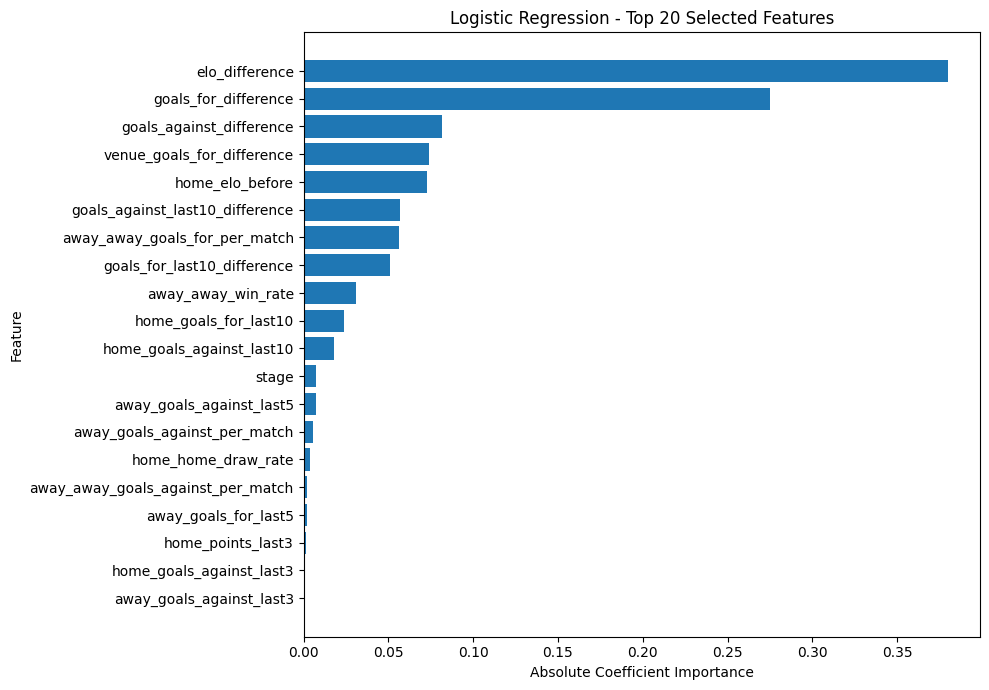

Best hyperparameters: {'classifier__C': 0.01}
Best CV Macro F1     : 0.4415
Majority baseline accuracy: 0.4412


,Actual,Predicted
Away Win,30.41,26.26
Draw,25.47,35.79
Home Win,44.12,37.96


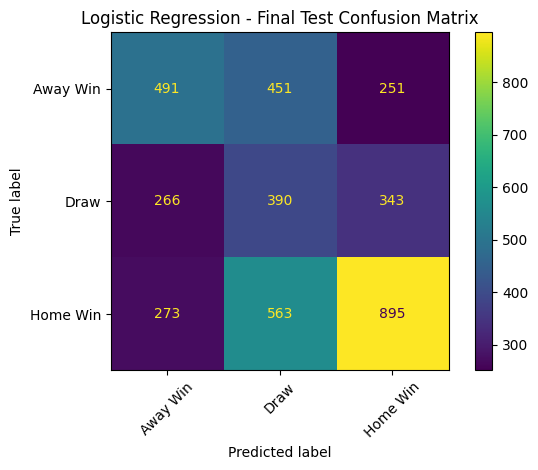

Final selected training: (17294, 26)
Final selected validation: (3873, 26)
Final selected test: (3923, 26)
Logistic Regression outputs saved successfully to LR_DIR.


In [36]:
final_lr_selector = (best_lr_pipeline.named_steps["selector"])
final_lr_selected_features = (X_train_corr.columns[final_lr_selector.get_support()].tolist())
print("Final Logistic Regression selected:", len(final_lr_selected_features), "features")
print("\nFinal selected features:")

for feature in final_lr_selected_features:
    print("-", feature)

final_lr_model = (best_lr_pipeline.named_steps["classifier"])
coef_matrix = final_lr_model.coef_

# For multiclass classification, aggregate
# the absolute coefficient magnitude across classes.
coef_importance = np.sum(np.abs(coef_matrix), axis=0)

final_coefficient_importance = pd.DataFrame({
    "Feature": final_lr_selected_features,
    "Coefficient_Importance": coef_importance
}).sort_values("Coefficient_Importance", ascending=False)
display(final_coefficient_importance.head(20))

top_20_lr = (
    final_coefficient_importance
    .head(20)
    .sort_values("Coefficient_Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(top_20_lr["Feature"], top_20_lr["Coefficient_Importance"])
plt.xlabel("Absolute Coefficient Importance")
plt.ylabel("Feature")
plt.title("Logistic Regression - Top 20 Selected Features")
plt.tight_layout()
plt.show()

print("Best hyperparameters:", lr_grid_search.best_params_)
print("Best CV Macro F1     :", round(lr_grid_search.best_score_, 4))

# Majority baseline and predicted vs actual distribution (test)
maj = pd.Series(y_train_encoded).value_counts().idxmax()
print("Majority baseline accuracy:", round(accuracy_score(y_test_encoded, np.full(len(y_test_encoded), maj)), 4))

dist = pd.DataFrame({
    "Actual": pd.Series(y_test_encoded).value_counts(normalize=True).sort_index(),
    "Predicted": pd.Series(y_test_pred).value_counts(normalize=True).sort_index(),
})
dist.index = target_encoder.classes_
display((dist * 100).round(2))

ConfusionMatrixDisplay.from_predictions(
    y_test_encoded, y_test_pred,
    display_labels=target_encoder.classes_, xticks_rotation=45)
plt.title("Logistic Regression - Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

X_train_lr_final = (final_lr_selector.transform(X_train_corr))
X_val_lr_final = (final_lr_selector.transform(X_val_corr))
X_test_lr_final = (final_lr_selector.transform(X_test_corr))
X_train_lr_final = pd.DataFrame(X_train_lr_final,columns=final_lr_selected_features)
X_val_lr_final = pd.DataFrame(X_val_lr_final, columns=final_lr_selected_features)
X_test_lr_final = pd.DataFrame(X_test_lr_final, columns=final_lr_selected_features)

print("Final selected training:", X_train_lr_final.shape)
print("Final selected validation:", X_val_lr_final.shape)
print("Final selected test:", X_test_lr_final.shape)

# Save model-specific datasets (renamed so they don't clash with final_dataset)
X_train_lr_final.to_csv(os.path.join(LR_DIR, "X_train_lr_selected.csv"), index=False)
X_val_lr_final.to_csv(os.path.join(LR_DIR, "X_validation_lr_selected.csv"), index=False)
X_test_lr_final.to_csv(os.path.join(LR_DIR, "X_test_lr_selected.csv"), index=False)

# Save artifacts
joblib.dump(corr_drop_columns, os.path.join(LR_DIR, "correlation_drop_columns.joblib"))
joblib.dump(lr_selector, os.path.join(LR_DIR, "l1_feature_selector_baseline.joblib"))
joblib.dump(final_lr_selector, os.path.join(LR_DIR, "l1_feature_selector_final.joblib"))
joblib.dump(best_lr_pipeline, os.path.join(LR_DIR, "logistic_regression_tuned_pipeline.joblib"))
joblib.dump(best_threshold, os.path.join(LR_DIR, "calibrated_draw_threshold.joblib"))

pd.DataFrame({"Feature": final_lr_selected_features}).to_csv(os.path.join(LR_DIR, "logistic_regression_selected_features.csv"), index=False)

# Save results
lr_selection_results.to_csv(os.path.join(LR_DIR, "l1_selection_C_results.csv"), index=False)
comparison_df.to_csv(os.path.join(LR_DIR, "logistic_regression_results.csv"))
final_coefficient_importance.to_csv(os.path.join(LR_DIR, "logistic_regression_coefficient_importance.csv"), index=False)
print("Logistic Regression outputs saved successfully to LR_DIR.")

## 9. Random Forest

Uses the unscaled tree-model matrix. The baseline and tuned models are retained; feature filtering is fit on training data only.

In [37]:
os.makedirs(RF_DIR, exist_ok=True)
USE_MARKET_FEATURES = False
X_train_final, X_val_final, X_test_final, MARKET_COLS = prepare_model_inputs(
    X_train_tree_base, X_val_tree_base, X_test_tree_base,
    y_train_encoded, y_val_encoded, y_test_encoded,
    use_market_features=USE_MARKET_FEATURES,
    expected_val_rows=len(val_df), expected_test_rows=len(test_df),
    model_name='Random Forest',
)
print('Matrix shapes:', X_train_final.shape, X_val_final.shape, X_test_final.shape)

Random Forest: model-input validation passed; market features dropped (7 columns found).
Matrix shapes: (17294, 87) (3873, 87) (3923, 87)


In [38]:
CORR_THRESHOLD = 0.90
corr_matrix = X_train_final.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_drop_columns = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]

X_train_corr = X_train_final.drop(columns=corr_drop_columns)
X_val_corr   = X_val_final.drop(columns=corr_drop_columns)
X_test_corr  = X_test_final.drop(columns=corr_drop_columns)

print("Features before:", X_train_final.shape[1], "| removed:", len(corr_drop_columns),
      "| remaining:", X_train_corr.shape[1])
print("Key features kept:",
      [c for c in ["elo_difference", "goals_for_difference"] if c in X_train_corr.columns])

Features before: 87 | removed: 20 | remaining: 67
Key features kept: ['elo_difference', 'goals_for_difference']


In [39]:
RF_MAX_FEATURES = 50

rf_selector = SelectFromModel(
    RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=20,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    ),
    threshold="median",
    max_features=RF_MAX_FEATURES
)

rf_selector.fit(X_train_corr, y_train_encoded)
rf_selected_features = X_train_corr.columns[rf_selector.get_support()].tolist()
print(f"MDI selected {len(rf_selected_features)} features.")

# Extract subsets as DataFrames
X_train_rf = X_train_corr[rf_selected_features].copy()
X_val_rf = X_val_corr[rf_selected_features].copy()
X_test_rf = X_test_corr[rf_selected_features].copy()

print("Selected Matrix Shapes:")
print(f"  Training   : {X_train_rf.shape}")
print(f"  Validation : {X_val_rf.shape}")
print(f"  Test       : {X_test_rf.shape}")

rf_baseline = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=20,
    class_weight="balanced_subsample", random_state=42, n_jobs=-1
).fit(X_train_rf, y_train_encoded)

y_train_proba_base = rf_baseline.predict_proba(X_train_rf)
y_val_proba_base   = rf_baseline.predict_proba(X_val_rf)

base_threshold = tune_draw_threshold(y_val_encoded, y_val_proba_base)
y_train_pred_base = predict_with_draw_threshold(y_train_proba_base, base_threshold)
y_val_pred_base, base_metrics = evaluate(y_val_encoded, y_val_proba_base, base_threshold)

print("=" * 60)
print("BASELINE RANDOM FOREST")
print("=" * 60)
print(f"Draw decision threshold (selected on validation): {base_threshold:.3f}")
print(f"Train Accuracy      : {accuracy_score(y_train_encoded, y_train_pred_base):.4f}")
print(f"Train Macro F1      : {f1_score(y_train_encoded, y_train_pred_base, average='macro'):.4f}")
print(f"Validation Accuracy : {base_metrics['Accuracy']:.4f}")
print(f"Validation Macro F1 : {base_metrics['Macro F1']:.4f}")
print(f"Validation ROC-AUC  : {base_metrics['ROC-AUC']:.4f}")
print(classification_report(y_val_encoded, y_val_pred_base,
                            target_names=target_encoder.classes_, zero_division=0))

MDI selected 34 features.
Selected Matrix Shapes:
  Training   : (17294, 34)
  Validation : (3873, 34)
  Test       : (3923, 34)
BASELINE RANDOM FOREST
Draw decision threshold (selected on validation): 0.370
Train Accuracy      : 0.5978
Train Macro F1      : 0.5908
Validation Accuracy : 0.4774
Validation Macro F1 : 0.4503
Validation ROC-AUC  : 0.6622
              precision    recall  f1-score   support

    Away Win       0.45      0.54      0.49      1147
        Draw       0.29      0.27      0.28       973
    Home Win       0.61      0.55      0.58      1753

    accuracy                           0.48      3873
   macro avg       0.45      0.45      0.45      3873
weighted avg       0.48      0.48      0.48      3873



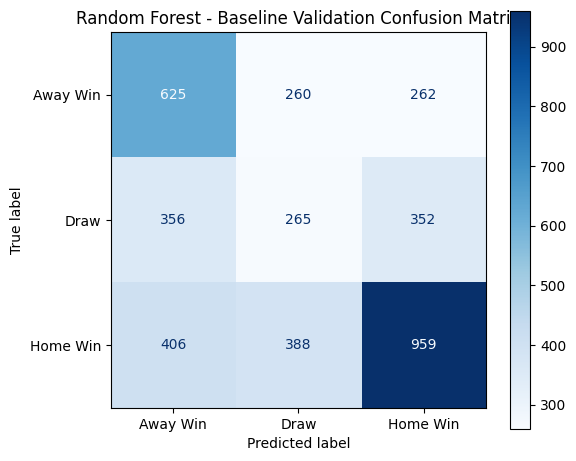

In [40]:
# Plot Baseline Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_encoded, y_val_pred_base,
    display_labels=target_encoder.classes_, cmap="Blues", ax=ax
)

plt.title("Random Forest - Baseline Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RF_DIR, "baseline_confusion_matrix.png"), dpi=300)
plt.show()

In [41]:
rf_pipeline = Pipeline([
    ("selector", SelectFromModel(
        RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=20,
                               class_weight="balanced_subsample",
                               random_state=42, n_jobs=1),
        threshold="median", max_features=RF_MAX_FEATURES)),
    ("classifier", RandomForestClassifier(
        class_weight="balanced_subsample", random_state=42, n_jobs=1))
])

param_distributions = {
    "classifier__n_estimators":      [200, 300, 400],
    "classifier__max_depth":         [4, 6, 8, 10, 12],
    "classifier__min_samples_split": [20, 40, 80],
    "classifier__min_samples_leaf":  [10, 20, 50, 100],
    "classifier__max_features":      ["sqrt", "log2", 0.3, 0.5],
    "classifier__criterion":         ["gini", "entropy"],
}

cv = TimeSeriesSplit(n_splits=5)

rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline, param_distributions=param_distributions, n_iter=25, scoring="f1_macro",
    cv=cv, verbose=1, random_state=42, n_jobs=-1, refit=True, return_train_score=True
)
rf_random_search.fit(X_train_corr, y_train_encoded)

print("Best parameters:")
for k, v in rf_random_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Macro F1: {rf_random_search.best_score_:.4f}")

best_rf_pipeline = rf_random_search.best_estimator_

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters:
  classifier__n_estimators: 200
  classifier__min_samples_split: 20
  classifier__min_samples_leaf: 100
  classifier__max_features: 0.3
  classifier__max_depth: 4
  classifier__criterion: entropy
Best CV Macro F1: 0.4517


Tuned draw decision threshold (selected on validation): 0.360
TUNED RANDOM FOREST
Train Macro F1      : 0.4644
Validation Macro F1 : 0.4549
CV Macro F1         : 0.4517
              precision    recall  f1-score   support

    Away Win       0.49      0.51      0.50      1147
        Draw       0.28      0.37      0.32       973
    Home Win       0.62      0.49      0.55      1753

    accuracy                           0.47      3873
   macro avg       0.46      0.46      0.45      3873
weighted avg       0.50      0.47      0.48      3873



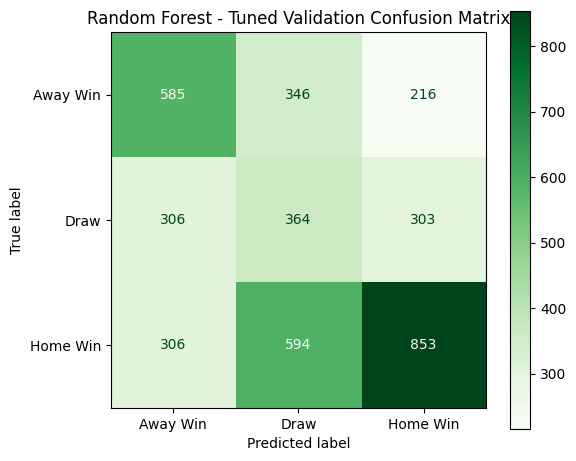

In [42]:
y_val_proba_tuned = best_rf_pipeline.predict_proba(X_val_corr)
best_threshold = tune_draw_threshold(y_val_encoded, y_val_proba_tuned)
print(f"Tuned draw decision threshold (selected on validation): {best_threshold:.3f}")

y_val_pred_tuned, val_metrics = evaluate(y_val_encoded, y_val_proba_tuned, best_threshold)
y_train_proba_tuned = best_rf_pipeline.predict_proba(X_train_corr)
y_train_pred_tuned = predict_with_draw_threshold(y_train_proba_tuned, best_threshold)

print("=" * 60)
print("TUNED RANDOM FOREST")
print("=" * 60)
print(f"Train Macro F1      : {f1_score(y_train_encoded, y_train_pred_tuned, average='macro'):.4f}")
print(f"Validation Macro F1 : {val_metrics['Macro F1']:.4f}")
print(f"CV Macro F1         : {rf_random_search.best_score_:.4f}")
print(classification_report(
    y_val_encoded,
    y_val_pred_tuned,
    target_names=target_encoder.classes_,
    zero_division=0)
)

# Plot Tuned Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val_encoded, y_val_pred_tuned,
    display_labels=target_encoder.classes_, cmap="Greens", ax=ax)
plt.title("Random Forest - Tuned Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RF_DIR, "tuned_validation_confusion_matrix.png"), dpi=300)
plt.show()

,Feature,Importance
0,elo_difference,0.274054
1,goals_for_difference,0.232243
2,win_rate_difference,0.127639
3,venue_goals_for_difference,0.088618
4,venue_win_rate_difference,0.042003
5,home_elo_before,0.034333
6,goals_against_difference,0.028670
7,away_elo_before,0.019746
8,points_last10_difference,0.019391
9,goals_for_last10_difference,0.016883


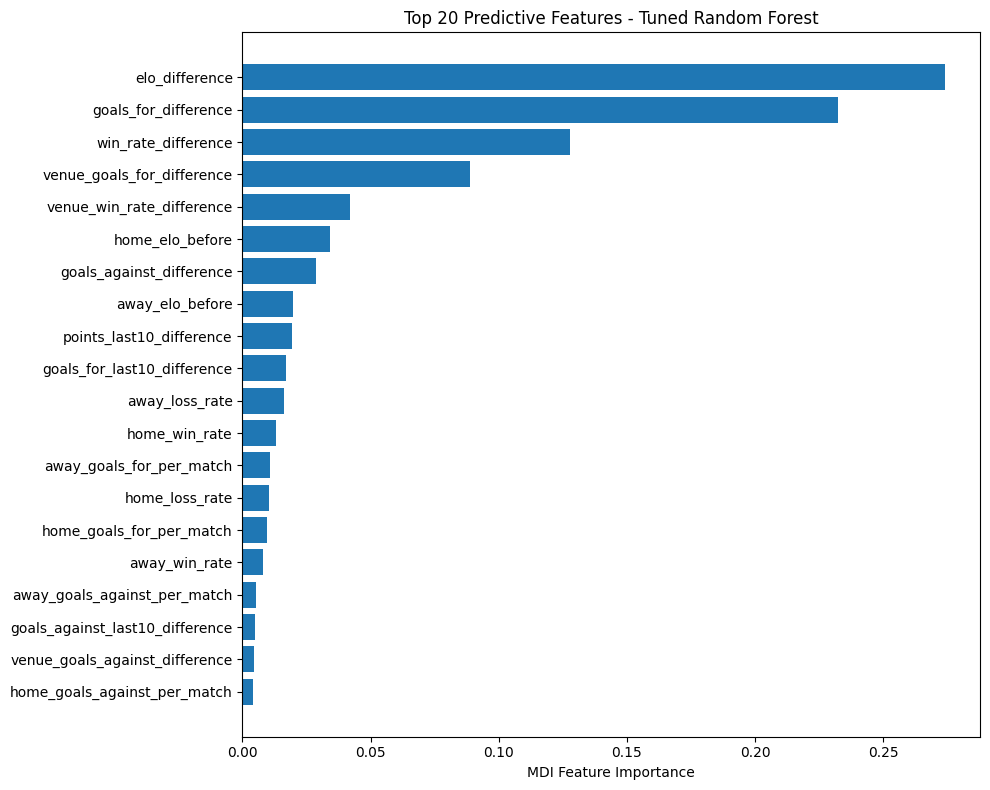

In [43]:
final_selector   = best_rf_pipeline.named_steps["selector"]
final_classifier = best_rf_pipeline.named_steps["classifier"]
final_rf_features = X_train_corr.columns[final_selector.get_support()].tolist()

feature_importance_df = pd.DataFrame({
    "Feature": final_rf_features,
    "Importance": final_classifier.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)
display(feature_importance_df.head(20))

# Plot Top 20 Features
top_20 = feature_importance_df.head(20).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top_20["Feature"], top_20["Importance"], color="#1f77b4")
plt.xlabel("MDI Feature Importance")
plt.title("Top 20 Predictive Features - Tuned Random Forest")
plt.tight_layout()
plt.savefig(os.path.join(RF_DIR, "top_20_feature_importances.png"), dpi=300)
plt.show()

,Baseline Validation,Tuned Validation,Final Test
Accuracy,0.4774,0.4653,0.4507
Macro Precision,0.4502,0.4632,0.4506
Macro Recall,0.4548,0.4569,0.4413
Macro F1,0.4503,0.4549,0.4409
Weighted F1,0.4777,0.4752,0.4610
ROC-AUC,0.6622,0.6634,0.6493
Argmax Accuracy,0.4686,0.4735,0.4535


,Baseline Validation,Tuned Validation,Improvement
Accuracy,0.4774,0.4653,-0.0121
Macro Precision,0.4502,0.4632,0.0130
Macro Recall,0.4548,0.4569,0.0021
Macro F1,0.4503,0.4549,0.0046
Weighted F1,0.4777,0.4752,-0.0025
ROC-AUC,0.6622,0.6634,0.0012
Argmax Accuracy,0.4686,0.4735,0.0049



Final Test Report:
              precision    recall  f1-score   support

    Away Win       0.46      0.47      0.46      1193
        Draw       0.28      0.37      0.32       999
    Home Win       0.62      0.49      0.54      1731

    accuracy                           0.45      3923
   macro avg       0.45      0.44      0.44      3923
weighted avg       0.48      0.45      0.46      3923

Majority baseline accuracy: 0.4412


,Actual,Predicted
Away Win,30.41,30.74
Draw,25.47,34.49
Home Win,44.12,34.77


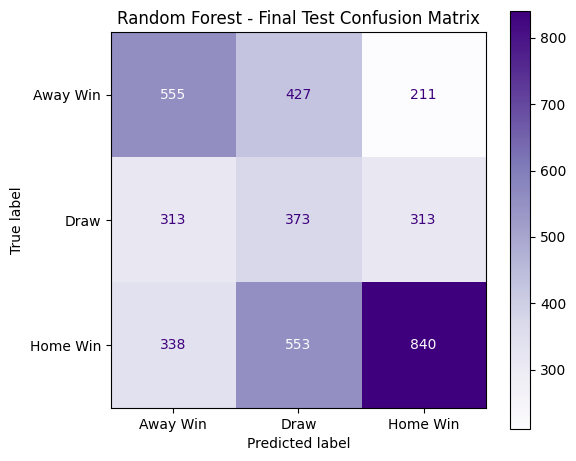

,Stage,Accuracy,Precision,Recall,F1-Score,Macro F1,ROC-AUC
0,Baseline Validation,0.4774,0.4502,0.4548,0.4777,0.4503,0.6622
1,Tuned Validation,0.4653,0.4632,0.4569,0.4752,0.4549,0.6634
2,Final Test,0.4507,0.4506,0.4413,0.4610,0.4409,0.6493


Random Forest outputs saved to: /content/drive/MyDrive/ML Assignment/random_forest


In [44]:
y_test_proba = best_rf_pipeline.predict_proba(X_test_corr)
y_test_pred, test_metrics = evaluate(y_test_encoded, y_test_proba, best_threshold)

comparison_df = pd.DataFrame({
    "Baseline Validation": base_metrics,
    "Tuned Validation": val_metrics,
    "Final Test": test_metrics
})
display(comparison_df.round(4))

improvement = (comparison_df["Tuned Validation"] - comparison_df["Baseline Validation"]).rename("Improvement")
display(pd.concat([comparison_df[["Baseline Validation", "Tuned Validation"]], improvement], axis=1).round(4))

print("\nFinal Test Report:")
print(classification_report(y_test_encoded, y_test_pred,
                            target_names=target_encoder.classes_, zero_division=0))

maj = pd.Series(y_train_encoded).value_counts().idxmax()
print("Majority baseline accuracy:",
      round(accuracy_score(y_test_encoded, np.full(len(y_test_encoded), maj)), 4))

dist = pd.DataFrame({
    "Actual": pd.Series(y_test_encoded).value_counts(normalize=True).sort_index(),
    "Predicted": pd.Series(y_test_pred).value_counts(normalize=True).sort_index(),
})
dist.index = target_encoder.classes_
display((dist * 100).round(2))

# Final Test Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded, y_test_pred,
    display_labels=target_encoder.classes_, cmap="Purples", ax=ax
)

plt.title("Random Forest - Final Test Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(RF_DIR, "final_test_confusion_matrix.png"), dpi=300)
plt.show()

# Overall Lifecycle Results Summary Table
final_summary_df = pd.DataFrame({
    "Stage": ["Baseline Validation", "Tuned Validation", "Final Test"],
    "Accuracy": [base_metrics["Accuracy"], val_metrics["Accuracy"], test_metrics["Accuracy"]],
    "Precision": [base_metrics["Macro Precision"], val_metrics["Macro Precision"], test_metrics["Macro Precision"]],
    "Recall": [base_metrics["Macro Recall"], val_metrics["Macro Recall"], test_metrics["Macro Recall"]],
    "F1-Score": [base_metrics["Weighted F1"], val_metrics["Weighted F1"], test_metrics["Weighted F1"]],
    "Macro F1": [base_metrics["Macro F1"], val_metrics["Macro F1"], test_metrics["Macro F1"]],
    "ROC-AUC": [base_metrics["ROC-AUC"], val_metrics["ROC-AUC"], test_metrics["ROC-AUC"]]
})
display(final_summary_df.round(4))

X_train_corr[final_rf_features].to_csv(os.path.join(RF_DIR,"X_train_rf_selected.csv"), index=False)
X_val_corr[final_rf_features].to_csv(os.path.join(RF_DIR, "X_validation_rf_selected.csv"), index=False)
X_test_corr[final_rf_features].to_csv(os.path.join(RF_DIR, "X_test_rf_selected.csv"), index=False)

joblib.dump(best_rf_pipeline, os.path.join(RF_DIR, "random_forest_tuned_pipeline.joblib"))
joblib.dump(final_selector, os.path.join(RF_DIR, "rf_feature_selector.joblib"))
joblib.dump(corr_drop_columns, os.path.join(RF_DIR, "correlation_dropped_columns.joblib"))
joblib.dump(final_rf_features, os.path.join(RF_DIR, "random_forest_selected_features.joblib"))
joblib.dump(best_threshold, os.path.join(RF_DIR, "calibrated_draw_threshold.joblib"))

comparison_df.to_csv(os.path.join(RF_DIR, "random_forest_results.csv"))
feature_importance_df.to_csv(os.path.join(RF_DIR, "random_forest_feature_importance.csv"), index=False)
pd.DataFrame(rf_random_search.cv_results_).to_csv(os.path.join(RF_DIR, "random_forest_cv_results.csv"), index=False)
print("Random Forest outputs saved to:", RF_DIR)

## 10. XGBoost

Uses balanced sample weights, training-only correlation and feature selection, and validation-selected draw thresholds.

In [45]:
os.makedirs(XGB_DIR, exist_ok=True)
USE_MARKET_FEATURES = False
X_train_final, X_val_final, X_test_final, MARKET_COLS = prepare_model_inputs(
    X_train_tree_base, X_val_tree_base, X_test_tree_base,
    y_train_encoded, y_val_encoded, y_test_encoded,
    use_market_features=USE_MARKET_FEATURES,
    expected_val_rows=len(val_df), expected_test_rows=len(test_df),
    model_name='XGBoost',
)
train_sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_encoded)
print('XGBoost model matrices:', X_train_final.shape, X_val_final.shape, X_test_final.shape)
print('Training sample weights:', train_sample_weights.shape)

XGBoost: model-input validation passed; market features dropped (7 columns found).
XGBoost model matrices: (17294, 87) (3873, 87) (3923, 87)
Training sample weights: (17294,)


In [46]:
# Data alignment and leakage guard

EXPECTED_VAL_ROWS, EXPECTED_TEST_ROWS = len(val_df), len(test_df)

assert list(X_train_final.columns) == list(X_val_final.columns) == list(X_test_final.columns), \
    "Train/validation/test columns differ"
assert len(X_train_final) == len(y_train_encoded)
assert len(X_val_final)   == len(y_val_encoded)  == EXPECTED_VAL_ROWS,  "Validation set was shrunk"
assert len(X_test_final)  == len(y_test_encoded) == EXPECTED_TEST_ROWS, "Test set was shrunk"

# Leakage / identifier / raw-odds guard (second line of defence)
EVENT_COLUMNS = ["goal", "shoton", "shotoff", "foulcommit",
                 "card", "cross", "corner", "possession"]
PLAYER_ID_COLUMNS = [f"{s}_player_{i}" for s in ("home", "away") for i in range(1, 12)]
ODDS_COLS = [f"{b}{o}" for b in ("B365", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS")
             for o in ("H", "D", "A")]
FORBIDDEN = (["home_team_goal", "away_team_goal", "target_outcome",
              "total_goals", "goal_difference"]
             + EVENT_COLUMNS + PLAYER_ID_COLUMNS + ODDS_COLS)

found = [c for c in X_train_final.columns if c in FORBIDDEN or "_implied_" in c]
assert not found, f"Forbidden columns present: {found}"

# Data quality: numeric only, no missing, no infinite values
assert X_train_final.select_dtypes(exclude=np.number).shape[1] == 0, "Non-numeric columns present"
for name, d in [("train", X_train_final), ("validation", X_val_final), ("test", X_test_final)]:
    assert d.isna().sum().sum() == 0, f"{name}: missing values"
    assert np.isfinite(d.to_numpy()).all(), f"{name}: infinite values"

print("Final XGBoost input verification passed: identical columns, full validation/test sets, "
      "no leakage columns, no missing or infinite values.")

print("\nFeature count:", X_train_final.shape[1])
print("Training rows:", len(X_train_final))
print("Validation rows:", len(X_val_final))
print("Test rows:", len(X_test_final))

Final XGBoost input verification passed: identical columns, full validation/test sets, no leakage columns, no missing or infinite values.

Feature count: 87
Training rows: 17294
Validation rows: 3873
Test rows: 3923


In [47]:
CORR_THRESHOLD = 0.90

corr_matrix = X_train_final.corr().abs()

upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

protected = {c for c in X_train_final.columns if c.startswith("market_")}
protected.discard("market_away_probability")  # exactly redundant, since the three probabilities sum to 1

corr_drop_columns = [
    col for col in upper_triangle.columns
    if (upper_triangle[col] > CORR_THRESHOLD).any() and col not in protected
]
if "market_away_probability" in X_train_final.columns:
    corr_drop_columns.append("market_away_probability")

X_train_corr = X_train_final.drop(columns=corr_drop_columns, errors="ignore").copy()
X_val_corr = X_val_final.drop(columns=corr_drop_columns, errors="ignore").copy()
X_test_corr = X_test_final.drop(columns=corr_drop_columns, errors="ignore").copy()

print("Correlation threshold:", CORR_THRESHOLD)
print("Features before correlation filtering:", X_train_final.shape[1])
print("Features removed:", len(corr_drop_columns))
print("Features remaining:", X_train_corr.shape[1])

assert list(X_train_corr.columns) == list(X_val_corr.columns)
assert list(X_train_corr.columns) == list(X_test_corr.columns)

Correlation threshold: 0.9
Features before correlation filtering: 87
Features removed: 20
Features remaining: 67


In [48]:
XGB_TARGET_FEATURES = min(50, X_train_corr.shape[1])

xgb_selector_model = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.8, objective="multi:softprob",
    eval_metric="mlogloss", importance_type="gain", random_state=42, n_jobs=-1
)

xgb_selector = SelectFromModel(estimator=xgb_selector_model, threshold=-np.inf, max_features=XGB_TARGET_FEATURES)

# Fit selector with balanced sample weights
xgb_selector.fit(X_train_corr, y_train_encoded, sample_weight=train_sample_weights)
xgb_selected_features = (X_train_corr.columns[xgb_selector.get_support()].tolist())
print("XGBoost Gain selected:", len(xgb_selected_features), "features")

print("\nSelected features:")
for i, feature in enumerate(xgb_selected_features, start=1):
    print(f"{i:2d}. {feature}")

X_train_xgb = X_train_corr[xgb_selected_features].copy()
X_val_xgb = X_val_corr[xgb_selected_features].copy()
X_test_xgb = X_test_corr[xgb_selected_features].copy()

print("\nSelected Matrix Shapes:")
print("Training   :", X_train_xgb.shape)
print("Validation :", X_val_xgb.shape)
print("Test       :", X_test_xgb.shape)

XGBoost Gain selected: 50 features

Selected features:
 1. stage
 2. home_win_rate
 3. home_draw_rate
 4. home_loss_rate
 5. home_goals_for_per_match
 6. home_goals_against_per_match
 7. home_home_win_rate
 8. home_home_goals_against_per_match
 9. home_points_last3
10. home_points_last5
11. home_points_last10
12. home_goals_for_last5
13. home_goals_for_last10
14. home_goals_against_last10
15. home_days_since_last_match
16. home_elo_before
17. away_win_rate
18. away_loss_rate
19. away_goals_for_per_match
20. away_goals_against_per_match
21. away_away_win_rate
22. away_away_draw_rate
23. away_away_goals_for_per_match
24. away_away_goals_against_per_match
25. away_points_last3
26. away_points_last5
27. away_points_last10
28. away_goals_for_last3
29. away_goals_against_last3
30. away_goals_against_last10
31. away_elo_before
32. win_rate_difference
33. goals_for_difference
34. goals_against_difference
35. venue_win_rate_difference
36. venue_goals_for_difference
37. venue_goals_against_diffe

In [49]:
# Train and evaluate the baseline XGBoost model

xgb_baseline = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.0, reg_lambda=1.0,
    objective="multi:softprob", eval_metric="mlogloss", random_state=42, n_jobs=-1
)

# Fit baseline with balanced sample weights
xgb_baseline.fit(
    X_train_xgb, y_train_encoded,
    sample_weight=train_sample_weights
)

# Predict probabilities
y_train_proba_base = xgb_baseline.predict_proba(X_train_xgb)
y_val_proba_base = xgb_baseline.predict_proba(X_val_xgb)

# Calibrate optimal baseline draw threshold on validation set using a unified grid
thr_grid = np.linspace(0.20, 0.42, 23)
base_threshold = 0.33
best_base_f1 = 0.0

for t in thr_grid:
    temp_preds = predict_with_draw_threshold(y_val_proba_base, threshold=t)
    score = f1_score(y_val_encoded, temp_preds, average="macro", zero_division=0)
    if score > best_base_f1:
        best_base_f1 = score
        base_threshold = t

if base_threshold in (thr_grid[0], thr_grid[-1]):
    print("WARNING: threshold is at the edge of the grid, widen the search range.")

print(f"Baseline draw decision threshold (selected on validation): {base_threshold:.3f}")

# Generate baseline predictions using calibrated cutoff
y_train_pred_base = predict_with_draw_threshold(y_train_proba_base, threshold=base_threshold)
y_val_pred_base = predict_with_draw_threshold(y_val_proba_base, threshold=base_threshold)

Baseline draw decision threshold (selected on validation): 0.370


BASELINE XGBOOST VALIDATION
Training Accuracy : 0.6229
Validation Accuracy: 0.4549
Macro Precision   : 0.4426
Macro Recall      : 0.4412
Macro F1          : 0.4391
Weighted F1       : 0.4617
ROC-AUC           : 0.6592

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.46      0.51      0.48      1147
        Draw       0.27      0.32      0.29       973
    Home Win       0.60      0.49      0.54      1753

    accuracy                           0.45      3873
   macro avg       0.44      0.44      0.44      3873
weighted avg       0.47      0.45      0.46      3873



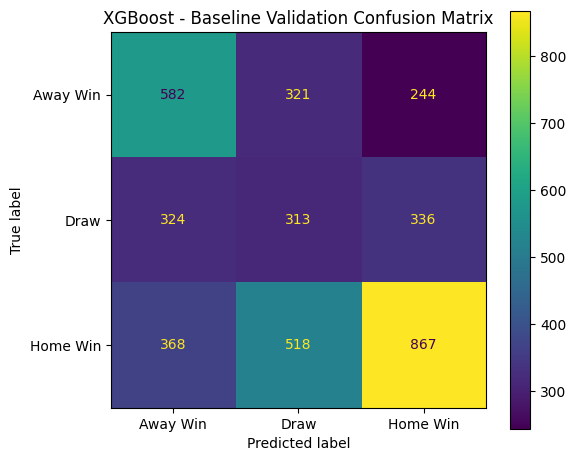

In [50]:
baseline_train_accuracy = accuracy_score(y_train_encoded, y_train_pred_base)
baseline_val_accuracy = accuracy_score(y_val_encoded, y_val_pred_base)
baseline_macro_precision = precision_score(y_val_encoded, y_val_pred_base, average="macro", zero_division=0)
baseline_macro_recall = recall_score(y_val_encoded, y_val_pred_base, average="macro", zero_division=0)
baseline_macro_f1 = f1_score(y_val_encoded, y_val_pred_base, average="macro", zero_division=0)
baseline_weighted_f1 = f1_score(y_val_encoded, y_val_pred_base, average="weighted", zero_division=0)
baseline_roc_auc = roc_auc_score(y_val_encoded, y_val_proba_base, multi_class="ovr", average="weighted")

print("=" * 60)
print("BASELINE XGBOOST VALIDATION")
print("=" * 60)
print(
    f"Training Accuracy : "
    f"{baseline_train_accuracy:.4f}"
)
print(
    f"Validation Accuracy: "
    f"{baseline_val_accuracy:.4f}"
)
print(
    f"Macro Precision   : "
    f"{baseline_macro_precision:.4f}"
)
print(
    f"Macro Recall      : "
    f"{baseline_macro_recall:.4f}"
)
print(
    f"Macro F1          : "
    f"{baseline_macro_f1:.4f}"
)
print(
    f"Weighted F1       : "
    f"{baseline_weighted_f1:.4f}"
)
print(
    f"ROC-AUC           : "
    f"{baseline_roc_auc:.4f}"
)
print("\nClassification Report:")
print(classification_report(y_val_encoded, y_val_pred_base, target_names=target_encoder.classes_, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val_encoded, y_val_pred_base, display_labels=target_encoder.classes_, ax=ax)
plt.title("XGBoost - Baseline Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(XGB_DIR, "baseline_confusion_matrix.png"), dpi=300)
plt.show()

In [51]:
xgb_pipeline = Pipeline([
    (
        "selector",
        SelectFromModel(
            estimator=XGBClassifier(
                n_estimators=200,
                max_depth=4,
                learning_rate=0.05,
                min_child_weight=3,

                subsample=0.8,
                colsample_bytree=0.8,

                objective="multi:softprob",
                eval_metric="mlogloss",
                importance_type="gain",

                random_state=42,
                n_jobs=1
            ),

            threshold=-np.inf,
            max_features=XGB_TARGET_FEATURES
        )
    ),
    ("classifier", XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", random_state=42, n_jobs=1))
])

print("XGBoost pipeline created.")

param_distributions = {
    "classifier__n_estimators": [200, 300, 400, 500, 600],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.10],
    "classifier__min_child_weight": [1, 3, 5, 7, 10],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0.0, 0.05, 0.1, 0.3, 0.5],
    "classifier__reg_alpha": [0.0, 0.01, 0.1, 0.5, 1.0],
    "classifier__reg_lambda": [1.0, 2.0, 5.0, 10.0]
}

# Use TimeSeriesSplit to prevent time leakage
cv = TimeSeriesSplit(n_splits=5)

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline, param_distributions=param_distributions, n_iter=40,
    scoring="f1_macro", cv=cv, verbose=1, random_state=42, n_jobs=-1, refit=True, return_train_score=True
)

print("Executing Weighted XGBoost RandomizedSearchCV with TimeSeriesSplit...")

# Pass sample weights via fit_params to BOTH the selector and classifier steps inside the pipeline
fit_params = {
    "selector__sample_weight": train_sample_weights,
    "classifier__sample_weight": train_sample_weights,
}

xgb_random_search.fit(X_train_corr, y_train_encoded, **fit_params)

print("\nBest Parameters Found:")
for k, v in xgb_random_search.best_params_.items():
    print(f"  {k}: {v}")

print(f"\nBest Cross-Validation Macro F1: {xgb_random_search.best_score_:.4f}")

best_xgb_pipeline = xgb_random_search.best_estimator_

XGBoost pipeline created.
Executing Weighted XGBoost RandomizedSearchCV with TimeSeriesSplit...
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Parameters Found:
  classifier__subsample: 0.7
  classifier__reg_lambda: 2.0
  classifier__reg_alpha: 0.1
  classifier__n_estimators: 200
  classifier__min_child_weight: 7
  classifier__max_depth: 2
  classifier__learning_rate: 0.08
  classifier__gamma: 0.05
  classifier__colsample_bytree: 0.7

Best Cross-Validation Macro F1: 0.4466


Tuned draw decision threshold (selected on validation): 0.370
TUNED XGBOOST VALIDATION (WITH DRAW THRESHOLDING)
Accuracy        : 0.4637
Macro Precision : 0.4448
Macro Recall    : 0.4463
Macro F1        : 0.4432
Weighted F1     : 0.4681
ROC-AUC         : 0.6611

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.46      0.53      0.49      1147
        Draw       0.27      0.29      0.28       973
    Home Win       0.61      0.51      0.56      1753

    accuracy                           0.46      3873
   macro avg       0.44      0.45      0.44      3873
weighted avg       0.48      0.46      0.47      3873



,Metric,Baseline,Tuned,Improvement
0,Accuracy,0.4549,0.4637,0.0088
1,Macro Precision,0.4426,0.4448,0.0022
2,Macro Recall,0.4412,0.4463,0.0051
3,Macro F1,0.4391,0.4432,0.0041
4,Weighted F1,0.4617,0.4681,0.0065
5,ROC-AUC,0.6592,0.6611,0.0019


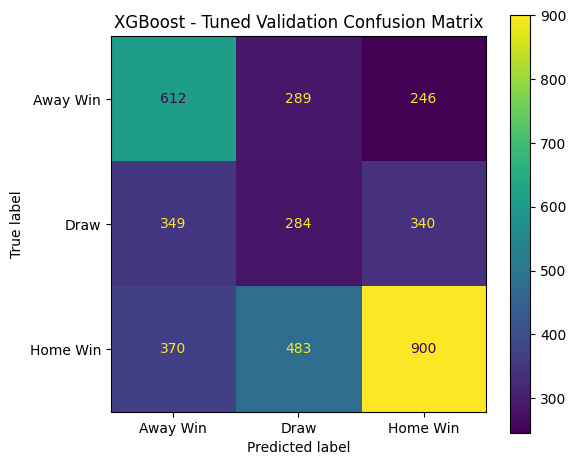

In [52]:
y_val_proba_tuned = best_xgb_pipeline.predict_proba(X_val_corr)

# Calibrate optimal draw threshold for the tuned pipeline using the unified grid
thr_grid = np.linspace(0.20, 0.42, 23)
best_threshold = 0.33
best_val_macro_f1 = 0.0

for t in thr_grid:
    temp_preds = predict_with_draw_threshold(y_val_proba_tuned, threshold=t)
    score = f1_score(y_val_encoded, temp_preds, average="macro", zero_division=0)
    if score > best_val_macro_f1:
        best_val_macro_f1 = score
        best_threshold = t

if best_threshold in (thr_grid[0], thr_grid[-1]):
    print("WARNING: threshold is at the edge of the grid, widen the search range.")

print(f"Tuned draw decision threshold (selected on validation): {best_threshold:.3f}")

y_val_pred_tuned = predict_with_draw_threshold(y_val_proba_tuned, threshold=best_threshold)

tuned_val_accuracy = accuracy_score(y_val_encoded, y_val_pred_tuned)
tuned_macro_precision = precision_score(y_val_encoded, y_val_pred_tuned, average="macro", zero_division=0)
tuned_macro_recall = recall_score(y_val_encoded, y_val_pred_tuned, average="macro", zero_division=0)
tuned_macro_f1 = f1_score(y_val_encoded, y_val_pred_tuned, average="macro", zero_division=0)
tuned_weighted_f1 = f1_score(y_val_encoded, y_val_pred_tuned, average="weighted", zero_division=0)
tuned_roc_auc = roc_auc_score(y_val_encoded, y_val_proba_tuned, multi_class="ovr", average="weighted")

print("=" * 60)
print("TUNED XGBOOST VALIDATION (WITH DRAW THRESHOLDING)")
print("=" * 60)
print(f"Accuracy        : {tuned_val_accuracy:.4f}")
print(f"Macro Precision : {tuned_macro_precision:.4f}")
print(f"Macro Recall    : {tuned_macro_recall:.4f}")
print(f"Macro F1        : {tuned_macro_f1:.4f}")
print(f"Weighted F1     : {tuned_weighted_f1:.4f}")
print(f"ROC-AUC         : {tuned_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_val_encoded, y_val_pred_tuned, target_names=target_encoder.classes_, zero_division=0))

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall",
               "Macro F1", "Weighted F1", "ROC-AUC"],
    "Baseline": [baseline_val_accuracy, baseline_macro_precision, baseline_macro_recall,
                 baseline_macro_f1, baseline_weighted_f1, baseline_roc_auc],
    "Tuned": [tuned_val_accuracy, tuned_macro_precision, tuned_macro_recall,
              tuned_macro_f1, tuned_weighted_f1, tuned_roc_auc]
})
comparison_df["Improvement"] = (comparison_df["Tuned"] - comparison_df["Baseline"])
display(comparison_df.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val_encoded, y_val_pred_tuned, display_labels=target_encoder.classes_, ax=ax)
plt.title("XGBoost - Tuned Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(XGB_DIR, "tuned_validation_confusion_matrix.png"), dpi=300)
plt.show()

Final tuned XGBoost feature count: 50

Final selected XGBoost features:
 1. stage
 2. home_win_rate
 3. home_draw_rate
 4. home_loss_rate
 5. home_goals_for_per_match
 6. home_goals_against_per_match
 7. home_home_win_rate
 8. home_home_goals_against_per_match
 9. home_points_last3
10. home_points_last5
11. home_points_last10
12. home_goals_for_last5
13. home_goals_for_last10
14. home_goals_against_last5
15. home_goals_against_last10
16. home_days_since_last_match
17. home_elo_before
18. away_win_rate
19. away_loss_rate
20. away_goals_for_per_match
21. away_goals_against_per_match
22. away_away_draw_rate
23. away_away_goals_for_per_match
24. away_away_goals_against_per_match
25. away_points_last10
26. away_goals_for_last3
27. away_goals_for_last5
28. away_goals_for_last10
29. away_goals_against_last3
30. away_elo_before
31. win_rate_difference
32. goals_for_difference
33. goals_against_difference
34. venue_win_rate_difference
35. venue_goals_for_difference
36. venue_goals_against_diffe

,Feature,Importance
0,elo_difference,0.138194
1,goals_for_difference,0.094885
2,win_rate_difference,0.063952
3,venue_goals_for_difference,0.050935
4,goals_against_difference,0.029122
5,home_elo_before,0.022267
6,away_win_rate,0.020133
7,home_goals_for_per_match,0.019647
8,home_points_last10,0.018491
9,venue_win_rate_difference,0.018221


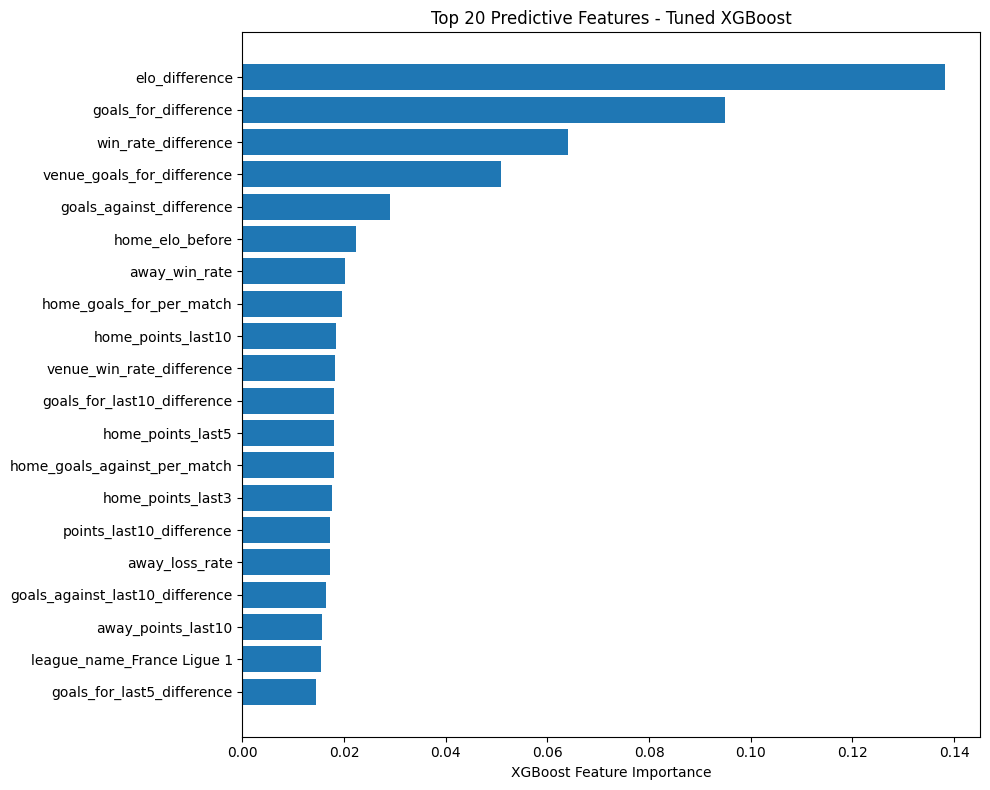

In [53]:
final_selector = (best_xgb_pipeline.named_steps["selector"])
final_classifier = (best_xgb_pipeline.named_steps["classifier"])
final_xgb_features = (X_train_corr.columns[final_selector.get_support()].tolist())

print("Final tuned XGBoost feature count:", len(final_xgb_features))

print("\nFinal selected XGBoost features:")
for i, feature in enumerate(final_xgb_features, start=1):
    print(f"{i:2d}. {feature}")

feature_importance_df = pd.DataFrame({
    "Feature": final_xgb_features,
    "Importance": final_classifier.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.head(30))

top_20 = (feature_importance_df.head(20).sort_values("Importance"))

plt.figure(figsize=(10, 8))
plt.barh(top_20["Feature"], top_20["Importance"])
plt.xlabel("XGBoost Feature Importance")
plt.title("Top 20 Predictive Features - Tuned XGBoost")
plt.tight_layout()
plt.savefig(os.path.join(XGB_DIR, "top_20_feature_importances.png"), dpi=300)
plt.show()

FINAL XGBOOST TEST BENCHMARK (WITH DRAW THRESHOLDING)
Accuracy        : 0.4591
Macro Precision : 0.4339
Macro Recall    : 0.4361
Macro F1        : 0.4338
Weighted F1     : 0.4599
ROC-AUC         : 0.6467

Final Test Classification Report:
              precision    recall  f1-score   support

    Away Win       0.43      0.50      0.46      1193
        Draw       0.28      0.27      0.27       999
    Home Win       0.59      0.54      0.57      1731

    accuracy                           0.46      3923
   macro avg       0.43      0.44      0.43      3923
weighted avg       0.46      0.46      0.46      3923

Majority-Class Baseline
----------------------------------------
Accuracy : 0.4412
Macro F1 : 0.2041

XGBoost
----------------------------------------
Accuracy : 0.4591
Macro F1 : 0.4338


,Actual,Predicted
Away Win,30.41,35.10
Draw,25.47,24.39
Home Win,44.12,40.50


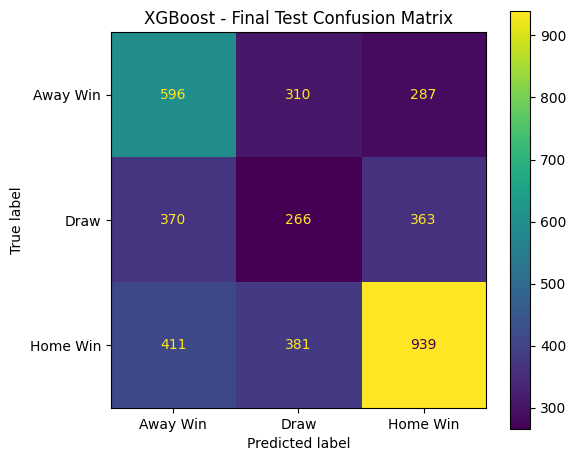

,Stage,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC
0,Baseline Validation,0.4549,0.4426,0.4412,0.4391,0.4617,0.6592
1,Tuned Validation,0.4637,0.4448,0.4463,0.4432,0.4681,0.6611
2,Final Test,0.4591,0.4339,0.4361,0.4338,0.4599,0.6467


Final XGBoost selected feature matrices:
Training   : (17294, 50)
Validation : (3873, 50)
Test       : (3923, 50)
Final dataset alignment and sanity checks passed.
All XGBoost outputs successfully saved.


In [54]:
y_test_proba = best_xgb_pipeline.predict_proba(X_test_corr)
y_test_pred = predict_with_draw_threshold(y_test_proba, threshold=best_threshold)

test_accuracy = accuracy_score(y_test_encoded, y_test_pred)
test_macro_precision = precision_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)
test_macro_recall = recall_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)
test_macro_f1 = f1_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test_encoded, y_test_pred, average="weighted", zero_division=0)
test_roc_auc = roc_auc_score(y_test_encoded, y_test_proba, multi_class="ovr", average="weighted")

print("=" * 60)
print("FINAL XGBOOST TEST BENCHMARK (WITH DRAW THRESHOLDING)")
print("=" * 60)
print(f"Accuracy        : {test_accuracy:.4f}")
print(f"Macro Precision : {test_macro_precision:.4f}")
print(f"Macro Recall    : {test_macro_recall:.4f}")
print(f"Macro F1        : {test_macro_f1:.4f}")
print(f"Weighted F1     : {test_weighted_f1:.4f}")
print(f"ROC-AUC         : {test_roc_auc:.4f}")
print("=" * 60)

print("\nFinal Test Classification Report:")
print(classification_report(y_test_encoded, y_test_pred, target_names=target_encoder.classes_, zero_division=0))

majority_class = (pd.Series(y_train_encoded).value_counts().idxmax())
majority_pred = np.full(len(y_test_encoded), majority_class)
majority_accuracy = accuracy_score(y_test_encoded, majority_pred)
majority_macro_f1 = f1_score(y_test_encoded, majority_pred, average="macro", zero_division=0)

print("Majority-Class Baseline")
print("-" * 40)
print(f"Accuracy : {majority_accuracy:.4f}")
print(f"Macro F1 : {majority_macro_f1:.4f}")
print("\nXGBoost")
print("-" * 40)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Macro F1 : {test_macro_f1:.4f}")

distribution_df = pd.DataFrame({
    "Actual": (pd.Series(y_test_encoded).value_counts(normalize=True).sort_index()),
    "Predicted": (pd.Series(y_test_pred).value_counts(normalize=True).sort_index())
})

distribution_df.index = [
    target_encoder.classes_[i]
    for i in distribution_df.index
]

display((distribution_df * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions( y_test_encoded, y_test_pred, display_labels=target_encoder.classes_, ax=ax)

plt.title("XGBoost - Final Test Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(XGB_DIR, "final_test_confusion_matrix.png"), dpi=300)
plt.show()

final_summary_df = pd.DataFrame({
    "Stage": ["Baseline Validation", "Tuned Validation", "Final Test"],
    "Accuracy": [baseline_val_accuracy, tuned_val_accuracy, test_accuracy],
    "Macro Precision": [baseline_macro_precision, tuned_macro_precision, test_macro_precision],
    "Macro Recall": [baseline_macro_recall, tuned_macro_recall, test_macro_recall],
    "Macro F1": [baseline_macro_f1, tuned_macro_f1, test_macro_f1],
    "Weighted F1": [baseline_weighted_f1, tuned_weighted_f1, test_weighted_f1],
    "ROC-AUC": [baseline_roc_auc, tuned_roc_auc, test_roc_auc]
})

display(final_summary_df.round(4))

X_train_xgb_final = X_train_corr[final_xgb_features].copy()
X_val_xgb_final = X_val_corr[final_xgb_features].copy()
X_test_xgb_final = X_test_corr[final_xgb_features].copy()

print("Final XGBoost selected feature matrices:")
print("Training   :", X_train_xgb_final.shape)
print("Validation :", X_val_xgb_final.shape)
print("Test       :", X_test_xgb_final.shape)

assert len(X_train_xgb_final) == len(y_train_encoded)
assert len(X_val_xgb_final) == len(y_val_encoded)
assert len(X_test_xgb_final) == len(y_test_encoded)

assert (list(X_train_xgb_final.columns) == list(X_val_xgb_final.columns) == list(X_test_xgb_final.columns))

assert not X_train_xgb_final.isnull().any().any()
assert not X_val_xgb_final.isnull().any().any()
assert not X_test_xgb_final.isnull().any().any()

print(
    "Final dataset alignment and "
    "sanity checks passed."
)

X_train_xgb_final.to_csv(os.path.join(XGB_DIR, "X_train_xgboost.csv"), index=False)
X_val_xgb_final.to_csv(os.path.join(XGB_DIR, "X_validation_xgboost.csv"), index=False)
X_test_xgb_final.to_csv(os.path.join(XGB_DIR, "X_test_xgboost.csv"), index=False)

joblib.dump(best_xgb_pipeline, os.path.join(XGB_DIR, "xgboost_tuned_pipeline.joblib"))
joblib.dump(final_selector, os.path.join(XGB_DIR, "xgb_feature_selector.joblib"))
joblib.dump(corr_drop_columns, os.path.join(XGB_DIR, "correlation_dropped_columns.joblib"))
joblib.dump(final_xgb_features, os.path.join(XGB_DIR, "xgboost_selected_features.joblib"))
joblib.dump(best_threshold, os.path.join(XGB_DIR, "calibrated_draw_threshold.joblib"))

pd.DataFrame({
    "Feature": final_xgb_features
}).to_csv(os.path.join(XGB_DIR, "xgboost_selected_features.csv"), index=False)

comparison_df.to_csv(os.path.join(XGB_DIR, "baseline_vs_tuned_validation.csv"), index=False)
final_summary_df.to_csv(os.path.join(XGB_DIR, "xgboost_lifecycle_results.csv"), index=False)
feature_importance_df.to_csv(os.path.join(XGB_DIR, "xgboost_feature_importance.csv"), index=False)

print("All XGBoost outputs successfully saved.")

## 11. Decision Tree

Keeps the baseline and tuned RFE pipelines, the validation-selected draw threshold, train/validation diagnostics and one final test evaluation.

In [55]:
os.makedirs(DT_DIR, exist_ok=True)
USE_MARKET_FEATURES = False
X_train_tree, X_val_tree, X_test_tree, MARKET_COLS = prepare_model_inputs(
    X_train_tree_base, X_val_tree_base, X_test_tree_base,
    y_train_encoded, y_val_encoded, y_test_encoded,
    use_market_features=USE_MARKET_FEATURES,
    expected_val_rows=len(val_df), expected_test_rows=len(test_df),
    model_name='Decision Tree',
)
print('Matrix shapes:', X_train_tree.shape, X_val_tree.shape, X_test_tree.shape)

Decision Tree: model-input validation passed; market features dropped (7 columns found).
Matrix shapes: (17294, 87) (3873, 87) (3923, 87)


In [56]:
# Data alignment and leakage guard

# Validation and test must be the COMPLETE chronological splits (burn-in is applied to training only)
EXPECTED_VAL_ROWS, EXPECTED_TEST_ROWS = len(val_df), len(test_df)

# 1) Structure and alignment
assert (
    list(X_train_tree.columns)
    == list(X_val_tree.columns)
    == list(X_test_tree.columns)
), "Train/validation/test columns differ"

assert len(X_train_tree) == len(y_train_encoded)
assert len(X_val_tree)   == len(y_val_encoded)   == EXPECTED_VAL_ROWS,  "Validation set was shrunk"
assert len(X_test_tree)  == len(y_test_encoded)  == EXPECTED_TEST_ROWS, "Test set was shrunk"

# 2) Leakage / identifier / raw-odds guard (second line of defence)
EVENT_COLUMNS = ["goal", "shoton", "shotoff", "foulcommit",
                 "card", "cross", "corner", "possession"]
PLAYER_ID_COLUMNS = [f"{s}_player_{i}" for s in ("home", "away") for i in range(1, 12)]
ODDS_COLS = [f"{b}{o}" for b in ("B365", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS")
             for o in ("H", "D", "A")]
FORBIDDEN = (["home_team_goal", "away_team_goal", "target_outcome",
              "total_goals", "goal_difference"]
             + EVENT_COLUMNS + PLAYER_ID_COLUMNS + ODDS_COLS)

found = [c for c in X_train_tree.columns if c in FORBIDDEN or "_implied_" in c]
assert not found, f"Forbidden columns present: {found}"

# 3) Data quality: numeric only, no missing, no infinite values
assert X_train_tree.select_dtypes(exclude=np.number).shape[1] == 0, "Non-numeric columns present"
for name, d in [("train", X_train_tree), ("validation", X_val_tree), ("test", X_test_tree)]:
    assert d.isna().sum().sum() == 0, f"{name}: missing values"
    assert np.isfinite(d.to_numpy()).all(), f"{name}: infinite values"

print("Data integrity verified: identical columns, full validation/test sets, no leakage columns, "
      "no missing or infinite values.")

Data integrity verified: identical columns, full validation/test sets, no leakage columns, no missing or infinite values.


In [57]:
CORR_THRESHOLD = 0.90

corr_matrix = X_train_tree.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

corr_drop_columns = [
    column
    for column in upper_triangle.columns
    if (upper_triangle[column] > CORR_THRESHOLD).any()
]

X_train_corr = X_train_tree.drop(columns=corr_drop_columns)
X_val_corr   = X_val_tree.drop(columns=corr_drop_columns)
X_test_corr  = X_test_tree.drop(columns=corr_drop_columns)

print("Correlation threshold:", CORR_THRESHOLD)

print(
    "Features before:", X_train_tree.shape[1],
    "| removed:", len(corr_drop_columns),
    "| remaining:", X_train_corr.shape[1]
)

print(
    "Key features kept:",
      [
          c for c in ["elo_difference", "goals_for_difference"]
          if c in X_train_corr.columns
      ]
)


print("\nAfter correlation filtering:")
print("Training   :", X_train_corr.shape)
print("Validation :", X_val_corr.shape)
print("Test       :", X_test_corr.shape)

assert (
    list(X_train_corr.columns)
    == list(X_val_corr.columns)
    == list(X_test_corr.columns)
)

print("\nCorrelation filtering completed.")

Correlation threshold: 0.9
Features before: 87 | removed: 20 | remaining: 67
Key features kept: ['elo_difference', 'goals_for_difference']

After correlation filtering:
Training   : (17294, 67)
Validation : (3873, 67)
Test       : (3923, 67)

Correlation filtering completed.


In [58]:
DT_TARGET_FEATURES = min(20, X_train_corr.shape[1])

BASE_TREE_PARAMS = dict(random_state=42, max_depth=6,
                        min_samples_split=40, min_samples_leaf=20,
                        class_weight="balanced")

dt_selector = RFE(DecisionTreeClassifier(**BASE_TREE_PARAMS),
                  n_features_to_select=DT_TARGET_FEATURES, step=0.10)
dt_selector.fit(X_train_corr, y_train_encoded)

dt_selected_features = X_train_corr.columns[dt_selector.get_support()].tolist()
print(f"RFE selected {len(dt_selected_features)} features:")
for f in dt_selected_features:
    print("-", f)

X_train_dt = X_train_corr[dt_selected_features]
X_val_dt   = X_val_corr[dt_selected_features]
X_test_dt  = X_test_corr[dt_selected_features]

print("\nSelected feature matrices:")
print("Training   :", X_train_dt.shape)
print("Validation :", X_val_dt.shape)
print("Test       :", X_test_dt.shape)

RFE selected 20 features:
- home_goals_for_per_match
- home_goals_against_per_match
- home_home_draw_rate
- home_home_goals_against_per_match
- home_points_last10
- home_goals_for_last10
- home_elo_before
- away_win_rate
- away_loss_rate
- away_goals_for_per_match
- away_away_win_rate
- away_away_draw_rate
- away_points_last10
- win_rate_difference
- goals_for_difference
- venue_win_rate_difference
- venue_goals_for_difference
- goals_against_last5_difference
- goals_for_last10_difference
- elo_difference

Selected feature matrices:
Training   : (17294, 20)
Validation : (3873, 20)
Test       : (3923, 20)


Baseline draw decision threshold (selected on validation): 0.360


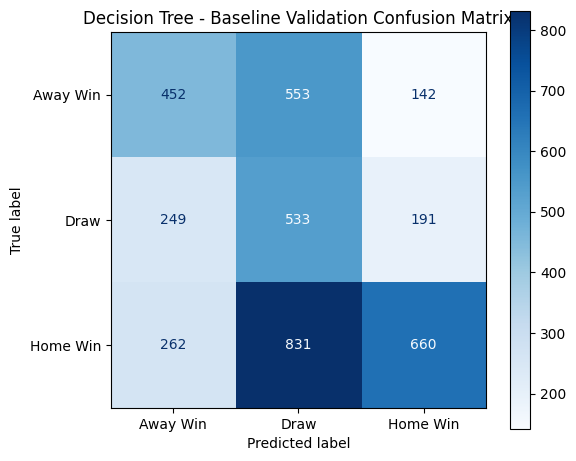

BASELINE DECISION TREE
Draw threshold        : 0.360
Train Accuracy        : 0.4415
Train Macro F1        : 0.4433
Validation Accuracy   : 0.4247
Validation Macro F1   : 0.4260
Validation ROC-AUC    : 0.6519

Baseline Validation Report:
              precision    recall  f1-score   support

    Away Win       0.47      0.39      0.43      1147
        Draw       0.28      0.55      0.37       973
    Home Win       0.66      0.38      0.48      1753

    accuracy                           0.42      3873
   macro avg       0.47      0.44      0.43      3873
weighted avg       0.51      0.42      0.44      3873



In [59]:
dt_baseline = DecisionTreeClassifier(**BASE_TREE_PARAMS).fit(X_train_dt, y_train_encoded)

y_val_proba_base = dt_baseline.predict_proba(X_val_dt)

base_threshold = tune_draw_threshold(
    y_val_encoded,
    y_val_proba_base
)

y_val_pred_base, base_metrics = evaluate(
    y_val_encoded,
    y_val_proba_base,
    base_threshold
)

print(f"Baseline draw decision threshold (selected on validation): {base_threshold:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val_encoded,
    y_val_pred_base,
    display_labels=target_encoder.classes_,
    cmap="Blues",
    ax=ax
)
plt.title("Decision Tree - Baseline Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(DT_DIR, "baseline_confusion_matrix.png"), dpi=300)
plt.show()

y_train_proba_base = dt_baseline.predict_proba(X_train_dt)
y_train_pred_base = predict_with_draw_threshold(y_train_proba_base, base_threshold)

print("=" * 60)
print("BASELINE DECISION TREE")
print("=" * 60)
print(f"Draw threshold        : {base_threshold:.3f}")
print(f"Train Accuracy        : {accuracy_score(y_train_encoded, y_train_pred_base):.4f}")
print(f"Train Macro F1        : {f1_score(y_train_encoded, y_train_pred_base, average='macro'):.4f}")
print(f"Validation Accuracy   : {base_metrics['Accuracy']:.4f}")
print(f"Validation Macro F1   : {base_metrics['Macro F1']:.4f}")
print(f"Validation ROC-AUC    : {base_metrics['ROC-AUC']:.4f}")

print("\nBaseline Validation Report:")
print(classification_report(
    y_val_encoded,
    y_val_pred_base,
    target_names=target_encoder.classes_,
    zero_division=0)
)

In [60]:
dt_pipeline = Pipeline([
    ("selector", RFE(DecisionTreeClassifier(**BASE_TREE_PARAMS),
                     n_features_to_select=DT_TARGET_FEATURES, step=0.10)),
    ("classifier", DecisionTreeClassifier(random_state=42, class_weight="balanced"))
])

param_distributions = {
    "classifier__criterion":         ["gini", "entropy", "log_loss"],
    "classifier__max_depth":         [3, 4, 5, 6, 7, 8],
    "classifier__min_samples_split": [20, 40, 80, 120],
    "classifier__min_samples_leaf":  [20, 50, 100, 150, 200],
    "classifier__max_features":      [None, "sqrt", "log2", 0.5, 0.75],
    "classifier__ccp_alpha":         [0.0, 0.0001, 0.0005, 0.001, 0.005],
}

cv = TimeSeriesSplit(n_splits=5)

dt_random_search = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=param_distributions,
    n_iter=40, scoring="f1_macro", cv=cv,
    verbose=1, random_state=42, n_jobs=-1,
    refit=True, return_train_score=True
)
dt_random_search.fit(X_train_corr, y_train_encoded)

print("Best parameters:")
for k, v in dt_random_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Macro F1: {dt_random_search.best_score_:.4f}")

best_dt_pipeline = dt_random_search.best_estimator_

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters:
  classifier__min_samples_split: 120
  classifier__min_samples_leaf: 100
  classifier__max_features: log2
  classifier__max_depth: 5
  classifier__criterion: log_loss
  classifier__ccp_alpha: 0.0005
Best CV Macro F1: 0.4413


In [61]:
y_val_proba_tuned = best_dt_pipeline.predict_proba(X_val_corr)

best_threshold = tune_draw_threshold(y_val_encoded, y_val_proba_tuned)

print(f"Tuned draw decision threshold (selected on validation): {best_threshold:.3f}")

y_val_pred_tuned, val_metrics = evaluate(y_val_encoded,y_val_proba_tuned,best_threshold)
y_test_proba = best_dt_pipeline.predict_proba(X_test_corr)
y_test_pred, test_metrics = evaluate(y_test_encoded,y_test_proba,best_threshold)

comparison_df = pd.DataFrame({
    "Baseline Validation": base_metrics,
    "Tuned Validation": val_metrics,
    "Final Test": test_metrics
})
display(comparison_df.round(4))

# Convert target encoder classes explicitly to strings to prevent string-formatting issues in classification_report
class_names = [str(cls) for cls in target_encoder.classes_]

print("\nTuned Validation Report:")
print(classification_report(
    y_val_encoded,
    y_val_pred_tuned,
    target_names=class_names,
    zero_division=0)
)

print("\nFinal Test Report:")
print(classification_report(
    y_test_encoded,
    y_test_pred,
    target_names=class_names,
    zero_division=0)
)

improvement = (comparison_df["Tuned Validation"] - comparison_df["Baseline Validation"]).rename("Improvement")
display(pd.concat([comparison_df[["Baseline Validation", "Tuned Validation"]], improvement], axis=1).round(4))

y_train_proba_tuned = best_dt_pipeline.predict_proba(X_train_corr)
y_train_pred_tuned = predict_with_draw_threshold(y_train_proba_tuned, best_threshold)

print("=" * 60)
print("TUNED DECISION TREE")
print("=" * 60)
print(f"Train Macro F1      : {f1_score(y_train_encoded, y_train_pred_tuned, average='macro'):.4f}")
print(f"Validation Macro F1 : {val_metrics['Macro F1']:.4f}")
print(f"CV Macro F1         : {dt_random_search.best_score_:.4f}")

maj = pd.Series(y_train_encoded).value_counts().idxmax()
print("Majority baseline accuracy:",
      round(accuracy_score(y_test_encoded, np.full(len(y_test_encoded), maj)), 4))

dist = pd.DataFrame({
    "Actual": pd.Series(y_test_encoded).value_counts(normalize=True).sort_index(),
    "Predicted": pd.Series(y_test_pred).value_counts(normalize=True).sort_index(),
})
dist.index = class_names
display((dist * 100).round(2))

Tuned draw decision threshold (selected on validation): 0.370


,Baseline Validation,Tuned Validation,Final Test
Accuracy,0.4247,0.4676,0.4588
Macro Precision,0.4707,0.4487,0.4311
Macro Recall,0.4395,0.4481,0.4313
Macro F1,0.4260,0.4474,0.4312
Weighted F1,0.4371,0.4724,0.4588
ROC-AUC,0.6519,0.6510,0.6393
Argmax Accuracy,0.4356,0.4802,0.4621



Tuned Validation Report:
              precision    recall  f1-score   support

    Away Win       0.47      0.50      0.49      1147
        Draw       0.28      0.31      0.29       973
    Home Win       0.60      0.53      0.56      1753

    accuracy                           0.47      3873
   macro avg       0.45      0.45      0.45      3873
weighted avg       0.48      0.47      0.47      3873


Final Test Report:
              precision    recall  f1-score   support

    Away Win       0.45      0.46      0.45      1193
        Draw       0.27      0.27      0.27       999
    Home Win       0.57      0.57      0.57      1731

    accuracy                           0.46      3923
   macro avg       0.43      0.43      0.43      3923
weighted avg       0.46      0.46      0.46      3923



,Baseline Validation,Tuned Validation,Improvement
Accuracy,0.4247,0.4676,0.0429
Macro Precision,0.4707,0.4487,-0.0220
Macro Recall,0.4395,0.4481,0.0087
Macro F1,0.4260,0.4474,0.0214
Weighted F1,0.4371,0.4724,0.0353
ROC-AUC,0.6519,0.6510,-0.0009
Argmax Accuracy,0.4356,0.4802,0.0447


TUNED DECISION TREE
Train Macro F1      : 0.4567
Validation Macro F1 : 0.4474
CV Macro F1         : 0.4413
Majority baseline accuracy: 0.4412


,Actual,Predicted
Away Win,30.41,30.61
Draw,25.47,25.39
Home Win,44.12,44.00


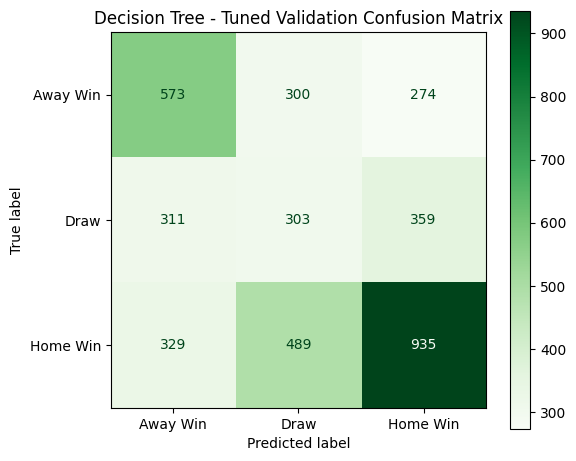

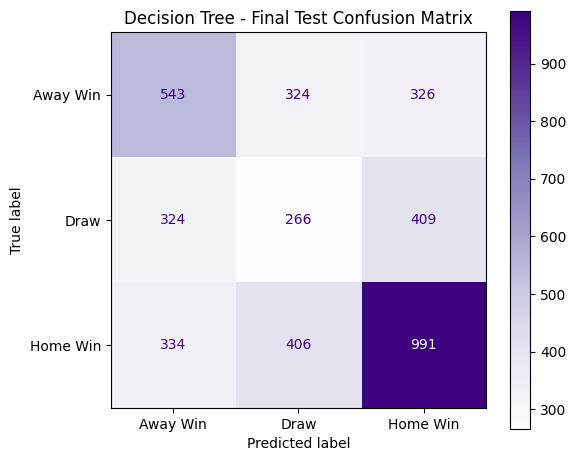

,Feature,Importance
0,away_loss_rate,0.342035
1,venue_goals_for_difference,0.228666
2,venue_win_rate_difference,0.149590
3,elo_difference,0.083543
4,goals_for_difference,0.083196
5,home_elo_before,0.070638
6,home_points_last10,0.011410
7,away_points_last10,0.008020
8,away_away_win_rate,0.006613
9,home_home_goals_against_per_match,0.005506


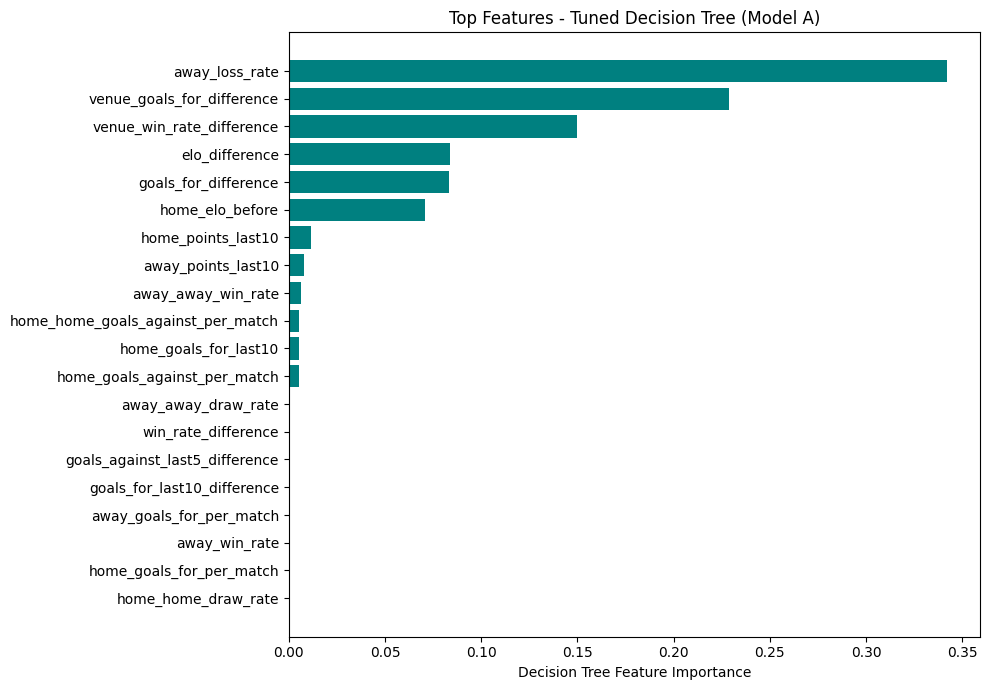

Decision Tree outputs saved to: /content/drive/MyDrive/ML Assignment/decision_tree


In [62]:
for name, y_t, y_p, cmap, fn in [
    ("Tuned Validation", y_val_encoded, y_val_pred_tuned,
     "Greens",
     "tuned_validation_confusion_matrix.png"),

    ("Final Test", y_test_encoded, y_test_pred,
     "Purples",
     "final_test_confusion_matrix.png"),
]:
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_t, y_p,
        display_labels=target_encoder.classes_,
        cmap=cmap,
        ax=ax
    )

    plt.title(f"Decision Tree - {name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(os.path.join(DT_DIR, fn), dpi=300)
    plt.show()

final_selector = best_dt_pipeline.named_steps["selector"]
final_classifier = best_dt_pipeline.named_steps["classifier"]
final_dt_features = X_train_corr.columns[final_selector.get_support()].tolist()

feature_importance_df = pd.DataFrame({
    "Feature": final_dt_features,
    "Importance": final_classifier.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)
display(feature_importance_df.head(20))

top = feature_importance_df.head(20).sort_values("Importance")
plt.figure(figsize=(10, 7))
plt.barh(top["Feature"], top["Importance"], color="teal")
plt.xlabel("Decision Tree Feature Importance")
plt.title("Top Features - Tuned Decision Tree (Model A)")
plt.tight_layout()
plt.savefig(os.path.join(DT_DIR, "decision_tree_feature_importances.png"), dpi=300)
plt.show()

X_train_corr[final_dt_features].to_csv(os.path.join(DT_DIR, "X_train_dt_selected.csv"), index=False)
X_val_corr[final_dt_features].to_csv(os.path.join(DT_DIR, "X_validation_dt_selected.csv"), index=False)
X_test_corr[final_dt_features].to_csv(os.path.join(DT_DIR, "X_test_dt_selected.csv"), index=False)

joblib.dump(best_dt_pipeline, os.path.join(DT_DIR, "decision_tree_tuned_pipeline.joblib"))
joblib.dump(final_selector, os.path.join(DT_DIR, "dt_feature_selector.joblib"))
joblib.dump(corr_drop_columns, os.path.join(DT_DIR, "correlation_dropped_columns.joblib"))
joblib.dump(final_dt_features, os.path.join(DT_DIR, "decision_tree_selected_features.joblib"))
joblib.dump(best_threshold, os.path.join(DT_DIR, "calibrated_draw_threshold.joblib"))

pd.DataFrame({"Feature": final_dt_features}).to_csv(
    os.path.join(
        DT_DIR,
        "decision_tree_selected_features.csv"
    ), index=False
)

comparison_df.to_csv(os.path.join(
    DT_DIR, "decision_tree_results.csv")
)

feature_importance_df.to_csv(os.path.join(
    DT_DIR, "decision_tree_feature_importance.csv"
), index=False)

pd.DataFrame(dt_random_search.cv_results_).to_csv(
    os.path.join(
        DT_DIR,
        "decision_tree_cv_results.csv"
    ), index=False)

print("Decision Tree outputs saved to:", DT_DIR)

## 12. Model Comparison and Final Outputs


In [63]:
# Load model lifecycle summaries written by the four training sections
PATHS = {
    'Logistic Regression': os.path.join(LR_DIR, 'logistic_regression_results.csv'),
    'Decision Tree': os.path.join(DT_DIR, 'decision_tree_results.csv'),
    'Random Forest': os.path.join(RF_DIR, 'random_forest_results.csv'),
}
XGB_PATH = os.path.join(XGB_DIR, 'xgboost_lifecycle_results.csv')
MODEL_ORDER = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']
STAGES = ['Baseline Validation', 'Tuned Validation', 'Final Test']
METRICS = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1', 'ROC-AUC']

results = {}
for model, path in PATHS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f'{model} results file not found: {path}')
    df = pd.read_csv(path, index_col=0).T
    results[model] = df.loc[STAGES, METRICS].astype(float)

if not os.path.exists(XGB_PATH):
    raise FileNotFoundError(f'XGBoost lifecycle file not found: {XGB_PATH}')
results['XGBoost'] = (
    pd.read_csv(XGB_PATH).set_index('Stage').loc[STAGES, METRICS].astype(float)
)
print('All saved model results loaded successfully.')

All saved model results loaded successfully.


In [64]:
def stage_table(stage):

    table = pd.DataFrame({
        model: results[model].loc[stage, METRICS]
        for model in MODEL_ORDER
    }).T
    return table.astype(float)

base_table = stage_table("Baseline Validation")
val_table = stage_table("Tuned Validation")
test_table = stage_table("Final Test")

print("=== BASELINE VALIDATION ===")
display(
    base_table
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

print("\n=== TUNED VALIDATION ===")
display(
    val_table
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

print("\n=== FINAL TEST ===")
display(
    test_table
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

=== BASELINE VALIDATION ===


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC
Logistic Regression,0.4666,0.4707,0.4566,0.4565,0.4781,0.6641
Random Forest,0.4774,0.4502,0.4548,0.4503,0.4777,0.6622
XGBoost,0.4549,0.4426,0.4412,0.4391,0.4617,0.6592
Decision Tree,0.4247,0.4707,0.4395,0.4260,0.4371,0.6519



=== TUNED VALIDATION ===


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC
Logistic Regression,0.4707,0.4739,0.4608,0.4603,0.4820,0.6643
Random Forest,0.4653,0.4632,0.4569,0.4549,0.4752,0.6634
Decision Tree,0.4676,0.4487,0.4481,0.4474,0.4724,0.6510
XGBoost,0.4637,0.4448,0.4463,0.4432,0.4681,0.6611



=== FINAL TEST ===


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC
Random Forest,0.4507,0.4506,0.4413,0.4409,0.4610,0.6493
Logistic Regression,0.4527,0.4519,0.4397,0.4407,0.4623,0.6526
XGBoost,0.4591,0.4339,0.4361,0.4338,0.4599,0.6467
Decision Tree,0.4588,0.4311,0.4313,0.4312,0.4588,0.6393


In [65]:
# Compute comparable training metrics; reuse shared draw-threshold helper

# COMPUTE FINAL TUNED TRAINING METRICS

def calculate_metrics(y_true, probabilities, threshold):

    predictions = predict_with_draw_threshold(probabilities, threshold)

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(y_true, predictions, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, predictions, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true,predictions, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities, multi_class="ovr", average="weighted")
    }

In [66]:
TRAIN_CONFIG = {
    'Logistic Regression': {
        'model': os.path.join(LR_DIR, 'logistic_regression_tuned_pipeline.joblib'),
        'corr_columns': os.path.join(LR_DIR, 'correlation_drop_columns.joblib'),
        'threshold': os.path.join(LR_DIR, 'calibrated_draw_threshold.joblib'),
    },
    'Decision Tree': {
        'model': os.path.join(DT_DIR, 'decision_tree_tuned_pipeline.joblib'),
        'corr_columns': os.path.join(DT_DIR, 'correlation_dropped_columns.joblib'),
        'threshold': os.path.join(DT_DIR, 'calibrated_draw_threshold.joblib'),
    },
    'Random Forest': {
        'model': os.path.join(RF_DIR, 'random_forest_tuned_pipeline.joblib'),
        'corr_columns': os.path.join(RF_DIR, 'correlation_dropped_columns.joblib'),
        'threshold': os.path.join(RF_DIR, 'calibrated_draw_threshold.joblib'),
    },
    'XGBoost': {
        'model': os.path.join(XGB_DIR, 'xgboost_tuned_pipeline.joblib'),
        'corr_columns': os.path.join(XGB_DIR, 'correlation_dropped_columns.joblib'),
        'threshold': os.path.join(XGB_DIR, 'calibrated_draw_threshold.joblib'),
    },
}

TRAIN_MATRICES = {
    'Logistic Regression': X_train_logistic_base,
    'Decision Tree': X_train_tree_base,
    'Random Forest': X_train_tree_base,
    'XGBoost': X_train_tree_base,
}

In [67]:
# Generate comparable training metrics using in-memory matrices and persisted model artifacts

# GENERATE TRAINING COMPARISON TABLE
train_results = {}

for model in MODEL_ORDER:
    print(f"Processing: {model}")
    config = TRAIN_CONFIG[model]

    # Load original model-ready training data
    X_train_model = TRAIN_MATRICES[model].copy()

    market_columns = [
        column
        for column in X_train_model.columns
        if column.startswith("market_")
    ]

    X_train_model = X_train_model.drop(columns=market_columns, errors="ignore")

    # Apply the same train-only correlation filtering used during model training
    correlation_drop_columns = joblib.load(config["corr_columns"])

    X_train_model = X_train_model.drop(columns=correlation_drop_columns, errors="ignore")

    # Load final pipeline and validation-selected threshold
    pipeline = joblib.load(config["model"])
    threshold = joblib.load(config["threshold"])

    # Make sure feature order matches training
    if hasattr(
        pipeline,"feature_names_in_"):

        expected_features = list(pipeline.feature_names_in_)
        missing_features = [
            feature
            for feature in expected_features
            if feature not in X_train_model.columns
        ]

        if missing_features:
            raise ValueError(
                f"{model}: missing expected features: "
                f"{missing_features}"
            )

        X_train_model = X_train_model[expected_features]


    # Final tuned model training probabilities
    train_probabilities = pipeline.predict_proba(X_train_model)

    # Calculate the same metrics used for validation/test
    train_results[model] = calculate_metrics(
        y_train_encoded, train_probabilities, threshold)

train_table = pd.DataFrame(train_results).T
train_table = train_table.loc[MODEL_ORDER, METRICS]

print("\n=== FINAL TUNED TRAINING PERFORMANCE ===")
display(train_table.sort_values("Macro F1", ascending=False).round(4))

Processing: Logistic Regression
Processing: Decision Tree
Processing: Random Forest
Processing: XGBoost

=== FINAL TUNED TRAINING PERFORMANCE ===


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC
XGBoost,0.5080,0.4937,0.4992,0.4931,0.5124,0.6933
Random Forest,0.4747,0.4727,0.4686,0.4644,0.4848,0.6667
Decision Tree,0.4711,0.4606,0.4603,0.4567,0.4789,0.6554
Logistic Regression,0.4554,0.4660,0.4504,0.4471,0.4680,0.6570


In [68]:
best_model = val_table["Macro F1"].idxmax()

print("=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print(f"Selected model: {best_model}")
print(f"Training Macro F1   : {train_table.loc[best_model, 'Macro F1']:.4f}")
print(f"Validation Macro F1 : {val_table.loc[best_model, 'Macro F1']:.4f}")
print(f"Test Macro F1       : {test_table.loc[best_model, 'Macro F1']:.4f}")
print(f"Test ROC-AUC        : {test_table.loc[best_model, 'ROC-AUC']:.4f}")

gap = pd.DataFrame({

    "Train Macro F1":train_table["Macro F1"],
    "Validation Macro F1":val_table["Macro F1"],
    "Test Macro F1":test_table["Macro F1"],
    "Train-Val Gap":train_table["Macro F1"] - val_table["Macro F1"],
    "Val-Test Drop":val_table["Macro F1"] - test_table["Macro F1"],
    "Validation ROC-AUC":val_table["ROC-AUC"],
    "Test ROC-AUC":test_table["ROC-AUC"],
    "AUC Drop":val_table["ROC-AUC"] - test_table["ROC-AUC"]
}).round(4)

print("=== TRAIN / VALIDATION / TEST GENERALISATION ===")
display(gap)

FINAL MODEL SELECTION
Selected model: Logistic Regression
Training Macro F1   : 0.4471
Validation Macro F1 : 0.4603
Test Macro F1       : 0.4407
Test ROC-AUC        : 0.6526
=== TRAIN / VALIDATION / TEST GENERALISATION ===


,Train Macro F1,Validation Macro F1,Test Macro F1,Train-Val Gap,Val-Test Drop,Validation ROC-AUC,Test ROC-AUC,AUC Drop
Logistic Regression,0.4471,0.4603,0.4407,-0.0132,0.0195,0.6643,0.6526,0.0117
Decision Tree,0.4567,0.4474,0.4312,0.0093,0.0162,0.6510,0.6393,0.0117
Random Forest,0.4644,0.4549,0.4409,0.0094,0.0140,0.6634,0.6493,0.0141
XGBoost,0.4931,0.4432,0.4338,0.0499,0.0094,0.6611,0.6467,0.0144


In [69]:
# Majority-class reference baseline; reuse encoded labels already in memory

majority_class = pd.Series(y_train_encoded).value_counts().idxmax()

majority_predictions = np.full(
    len(y_test_encoded), majority_class)

MAJORITY_ACC = accuracy_score(
    y_test_encoded, majority_predictions)

MAJORITY_F1 = f1_score(
    y_test_encoded, majority_predictions, average="macro", zero_division=0)

print("=== MAJORITY-CLASS TEST BASELINE ===")
print(f"Accuracy : {MAJORITY_ACC:.4f}")
print(f"Macro F1 : {MAJORITY_F1:.4f}")

=== MAJORITY-CLASS TEST BASELINE ===
Accuracy : 0.4412
Macro F1 : 0.2041


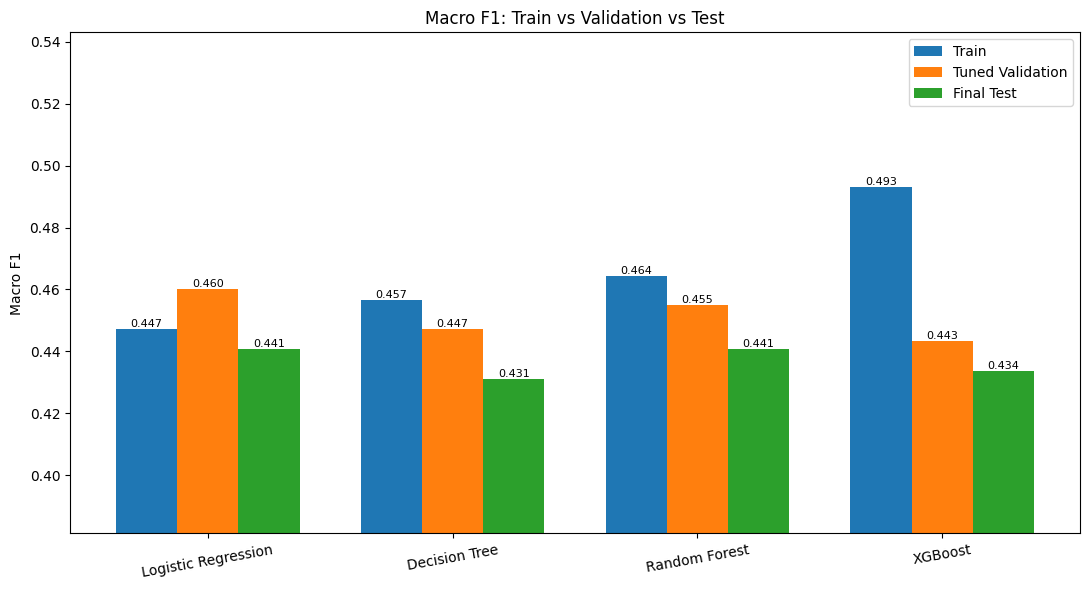

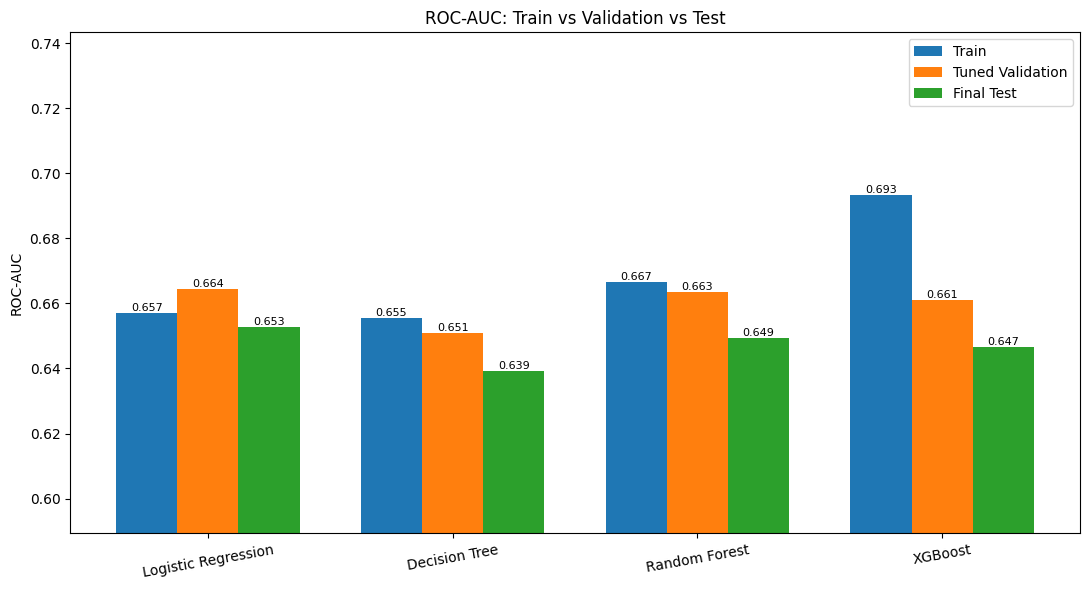

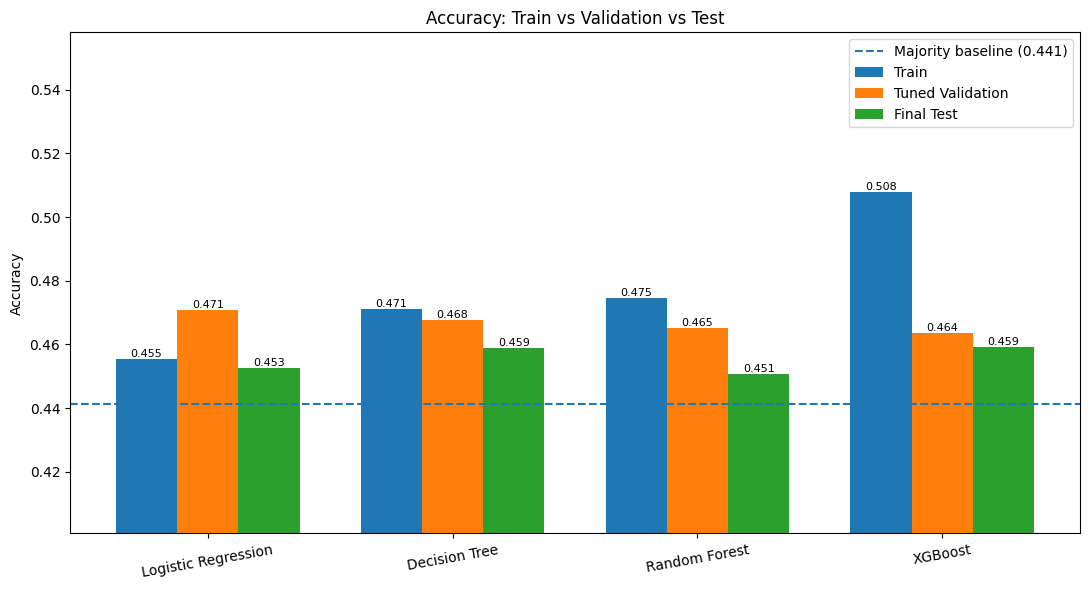

=== FINAL MODEL COMPARISON SUMMARY ===


,Model,Train Accuracy,Train Macro F1,Validation Accuracy,Validation Macro F1,Validation ROC-AUC,Test Accuracy,Test Macro F1,Test ROC-AUC
0,Logistic Regression,0.4554,0.4471,0.4707,0.4603,0.6643,0.4527,0.4407,0.6526
1,Random Forest,0.4747,0.4644,0.4653,0.4549,0.6634,0.4507,0.4409,0.6493
2,Decision Tree,0.4711,0.4567,0.4676,0.4474,0.6510,0.4588,0.4312,0.6393
3,XGBoost,0.5080,0.4931,0.4637,0.4432,0.6611,0.4591,0.4338,0.6467


MODEL COMPARISON OUTPUTS SAVED
Saved to: /content/drive/MyDrive/ML Assignment/final_comparison

Files created:
- comparison_train.csv
- comparison_validation.csv
- comparison_test.csv
- comparison_baseline_validation.csv
- comparison_generalisation_gap.csv
- final_model_comparison.csv
- comparison_macro_f1.png
- comparison_roc_auc.png
- comparison_accuracy.png


In [70]:
def grouped_bar(
    metric,
    filename,
    reference=None
):

    x = np.arange(len(MODEL_ORDER))

    width = 0.25
    fig, ax = plt.subplots(figsize=(11, 6))

    train_bars = ax.bar(x - width, train_table.loc[MODEL_ORDER, metric], width, label="Train")
    val_bars = ax.bar(x, val_table.loc[MODEL_ORDER, metric], width, label="Tuned Validation")
    test_bars = ax.bar(x + width, test_table.loc[MODEL_ORDER, metric], width, label="Final Test")

    ax.bar_label(train_bars, fmt="%.3f", fontsize=8)
    ax.bar_label(val_bars, fmt="%.3f", fontsize=8)
    ax.bar_label(test_bars, fmt="%.3f", fontsize=8)

    if reference is not None:
        ax.axhline(reference, linestyle="--", label=(f"Majority baseline ({reference:.3f})"))

    all_values = np.concatenate([
        train_table.loc[MODEL_ORDER, metric].to_numpy(),
        val_table.loc[MODEL_ORDER,metric].to_numpy(),
        test_table.loc[MODEL_ORDER,metric].to_numpy()
    ])

    lower = max(0, all_values.min() - 0.05)
    upper = min(1, all_values.max() + 0.05)
    ax.set_ylim(lower, upper)

    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_ORDER, rotation=10)

    ax.set_ylabel(metric)
    ax.set_title(f"{metric}: Train vs Validation vs Test")

    ax.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, filename),
        dpi=300, bbox_inches="tight")
    plt.show()

grouped_bar("Macro F1", "comparison_macro_f1.png")
grouped_bar("ROC-AUC", "comparison_roc_auc.png")
grouped_bar("Accuracy", "comparison_accuracy.png", reference=MAJORITY_ACC)

summary_rows = []

for model in MODEL_ORDER:
    summary_rows.append({
        "Model": model,
        "Train Accuracy":train_table.loc[model, "Accuracy"],
        "Train Macro F1":train_table.loc[model, "Macro F1"],

        "Validation Accuracy":val_table.loc[model, "Accuracy"],
        "Validation Macro F1":val_table.loc[model, "Macro F1"],
        "Validation ROC-AUC":val_table.loc[model, "ROC-AUC"],

        "Test Accuracy":test_table.loc[model, "Accuracy"],
        "Test Macro F1":test_table.loc[model, "Macro F1"],
        "Test ROC-AUC":test_table.loc[model, "ROC-AUC"]
    })


final_summary = pd.DataFrame(summary_rows)
final_summary = final_summary.sort_values(
    "Validation Macro F1",ascending=False
).reset_index(drop=True)

print("=== FINAL MODEL COMPARISON SUMMARY ===")
display(final_summary.round(4))

# SAVE FINAL COMPARISON OUTPUTS
train_table.to_csv(os.path.join(OUT_DIR, "comparison_train.csv"))
val_table.to_csv(os.path.join(OUT_DIR, "comparison_validation.csv"))
test_table.to_csv(os.path.join(OUT_DIR, "comparison_test.csv"))
base_table.to_csv(os.path.join(OUT_DIR, "comparison_baseline_validation.csv"))
gap.to_csv(os.path.join(OUT_DIR, "comparison_generalisation_gap.csv"))
final_summary.to_csv(os.path.join(OUT_DIR, "final_model_comparison.csv"), index=False)

print("=" * 60)
print("MODEL COMPARISON OUTPUTS SAVED")
print("=" * 60)

print("Saved to:", OUT_DIR)
print("\nFiles created:")

print("- comparison_train.csv")
print("- comparison_validation.csv")
print("- comparison_test.csv")
print("- comparison_baseline_validation.csv")
print("- comparison_generalisation_gap.csv")
print("- final_model_comparison.csv")
print("- comparison_macro_f1.png")
print("- comparison_roc_auc.png")
print("- comparison_accuracy.png")